**Анотація**

У роботі досліджується стійкість методів машинного навчання до сигнально-залежного шуму в задачах попіксельної класифікації мультиспектральних супутникових зображень. Запропоновано розширення просторово-спектрального дескриптора TEG (Texture-Entropy-Gradient) за рахунок інтеграції частотних характеристик дискретно-косинусного перетворення (ДКП), зокрема метрики кільцевої енергії спектра. Оцінка ефективності ансамблевого класифікатора XGBoost на базі гібридного простору ознак (TEG+ДКП) проводиться в умовах впливу пуассонівського шуму різної інтенсивності. Для визначення доцільності попередньої математичної обробки оптичних даних виконано порівняльний аналіз точності класифікації з використанням варіаційно-стабілізуючих перетворень (ВСП, перетворення Анскомба) та без них. Дослідження дозволяє оцінити здатність алгоритмів на базі дерев рішень самостійно компенсувати змінну дисперсію шуму та кількісно обґрунтувати внесок локальних частотних ознак у загальну надійність розпізнавання класів.

**Оновлений план дослідження (Вузький фокус)**

1. **Моделювання сигнально-залежних спотворень**
Накладання пуассонівського (фотонного) шуму з різними піковими значеннями (імітація низького співвідношення сигнал/шум) на підготовлені RGB-знімки Sentinel-2.
2. **Варіаційна стабілізація даних (ВСП)**
Формування двох паралельних експериментальних гілок. Перша — зашумлені зображення у вихідному вигляді (без стабілізації). Друга — зображення, пропущені через конвеєр перетворення Анскомба (пряме перетворення $\rightarrow$ базове згладжування $\rightarrow$ зворотне перетворення) для приведення пуассонівського шуму до властивостей гаусового.
3. **Екстракція частотних ознак (Кільцева енергія ДКП)**
Обчислення локального ДКП у ковзному вікні для кожного каналу зображення. Розрахунок кільцевої енергії спектра (радіальний розподіл низьких, середніх та високих просторових частот), що формує стійкі до локальних флуктуацій ознаки.
4. **Інтеграція ознак та навчання (TEG + ДКП + XGBoost)**
Формування гібридного простору ознак шляхом об'єднання просторових метрик TEG (Собель, ентропія, LBP) із частотними метриками кільцевої енергії ДКП. Навчання моделі XGBoost на згенерованому просторі.
5. **Порівняльний аналіз (Ключові експерименти керівника)**
* **Експеримент А (Вплив ознак):** Оцінка кількісного приросту точності (F1-Macro, AUC) від додавання ДКП-ознак порівняно з базовим TEG в умовах пуассонівського шуму.
* **Експеримент Б (Вплив ВСП):** Порівняння результатів роботи пайплайну "TEG+ДКП+XGBoost" на даних з ВСП та без ВСП. Визначення порогу деградації, за якого ансамблева модель перестає самостійно справлятися з нелінійною дисперсією шуму і починає критично залежати від попередньої стабілізації Анскомба.

### Що відбувається, коли ми робимо просто ДКП?

Уявіть, що алгоритм бере локальне вікно навколо пікселя (наприклад, розміром 7х7) і застосовує до нього 2D-ДКП. На виході він отримує **матрицю 7х7 (тобто 49 чисел - коефіцієнтів)**.

* У лівому верхньому кутку цієї матриці лежить найважливіше число (DC-коефіцієнт) — загальна яскравість.
* Ближче до лівого верхнього кута лежать низькі частоти (плавні переходи кольору).
* У правому нижньому кутку лежать найвищі частоти (дуже різкі перепади — тобто **шум** і мікродрібниці).

Якщо ви просто "викинете" всі 49 чисел у модель XGBoost, це буде неефективно: ознак занадто багато, вони розрізнені, і модель може заплутатися в шумі.

### Що таке "Кільцева енергія" (Ring Energy / Radial Energy)?

Замість того, щоб віддавати моделі 49 сирих чисел, ми їх групуємо (сумуємо їхні квадрати) по "кільцях" від лівого верхнього кута до правого нижнього:

1. **Кільце 1 (Низькі частоти):** Сума енергії кількох коефіцієнтів біля центру. (Відповідає за макроструктуру об'єкта).
2. **Кільце 2 (Середні частоти):** Сума енергії коефіцієнтів посередині матриці. (Відповідає за текстуру).
3. **Кільце 3 (Високі частоти):** Сума енергії у правому нижньому кутку. (Ось тут концентрується весь пуассонівський шум!).

### Чому це геніально?

Ви отримуєте всього **3 нові ознаки** замість 49. Але головне: оскільки пуассонівський шум лежить переважно у високочастотному спектрі (Кільце 3), XGBoost під час навчання автоматично побачить, що ознака "Кільце 3" є ненадійною (там сміття), і знизить її вагу, а рішення буде приймати на основі Кільця 1 та Кільця 2. Це і є механізм **самостійної боротьби із шумом**!

### План дослідження самих тех (Ablation Study)

**1. Огляд літератури та обґрунтування деградації**

* Аналіз 2–3 сучасних робіт (2024–2026 рр.), які досліджували Pavia University в умовах шуму.
* Обґрунтування вибору рівнів шуму (Peak від 100 до 5) та нелінійного кроку з посиланням на природу фотонного шуму та роботу Makitalo & Foi (DOI: 10.1109/TIP.2010.2056693).

**2. Підготовка даних та симуляція умов**

* Генерація 8 наборів зашумлених даних (Peak = 100, 80, 60, 40, 30, 20, 10, 5) з оригінального датасету Pavia U.

**3. Екстракція ознак (Прогін трьох конвеєрів)**

* *Конвеєр 1 (Базлайн):* Лише Raw TEG (Sobel + Entropy + LBP).
* *Конвеєр 2 (Частотна підтримка):* TEG + ДКП (без стабілізації).
* *Конвеєр 3 (Запропонований метод):* ВСП (Варіаційна стабілізація) + TEG + ДКП.

**4. Навчання ансамблю та аналіз важливості ознак (Візуалізація 2)**

* Навчання XGBoost для кожного набору даних.
* Побудова гістограми (Grouped Bar Chart) метрики Information Gain для чистих та екстремально зашумлених даних. Мета: довести внутрішню адаптацію моделі (передачу ваги від просторових ознак до частотних).

**5. Кількісний аналіз стійкості (Візуалізація 1)**

* Побудова лінійних графіків деградації (Вісь X — рівень шуму, Вісь Y — F1-Macro / Overall Accuracy).
* На графіку будуть 3 криві (відповідно до трьох конвеєрів), які наочно покажуть "точку зламу", де базові методи здаються, а метод із ВСП продовжує тримати високу точність.

**6. Якісна візуалізація результатів (Візуалізація 3)**

* Вибір однієї "перехідної" точки (наприклад, Peak = 30 або 20, де на лінійному графіку спостерігається найбільший розрив між методами).
* Створення сітки зображень: фрагмент Ground Truth поруч із картами класифікації від Конвеєра 1, 2 та 3 для візуальної демонстрації зменшення ефекту "солі та перцю".

**7. Оцінка обчислювальної складності (Таблиця)**

* Формування компактної таблиці, яка містить лише час виконання (у секундах або мілісекундах) для етапів: 1) Екстракція ознак, 2) Навчання XGBoost, 3) Інференс (передбачення).
* Висновок про те, чи придатний запропонований конвеєр (Конвеєр 3) для розгортання на edge-пристроях (наприклад, безпосередньо на платі БПЛА).

In [ ]:
# this can be used to install required packages into correct python location
%pip install opencv-python numpy matplotlib xgboost scikit-image torch

In [ ]:
# Importing the Necessary Libraries
# The main ones here are XGBoost and local_binary_pattern.

import pandas as pd
import cv2
import numpy as np
import scipy.fftpack
import time
import xgboost as xgb
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import os
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
# =============================================================================
# ДОДАТКОВА ФУНКЦІЯ ЕКСТРАКЦІЇ TEG-ОЗНАК
# =============================================================================
from skimage.feature import local_binary_pattern
from skimage.filters import sobel
from skimage.filters.rank import entropy
from skimage.morphology import disk
from scipy.ndimage import median_filter # Імпортуємо фільтр

import warnings

# Ігнорувати UserWarning саме від модуля skimage
warnings.filterwarnings("ignore", category=UserWarning, module="skimage.feature.texture")

In [ ]:
# ВСП
def anscombe_transform(image):
    """Пряме ВСП (перетворення Анскомба)."""
    # Формула: 2 * sqrt(x + 3/8)
    # Зображення переводиться у float для уникнення переповнення
    return 2.0 * np.sqrt(image.astype(np.float32) + (3.0 / 8.0))

def inverse_anscombe_transform(vst_image):
    """Зворотне ВСП (алгебраїчне)."""
    # Формула: (y / 2)^2 - 3/8
    inverse = (vst_image / 2.0)**2 - (3.0 / 8.0)
    return np.clip(inverse, 0, 255).astype(np.uint8)

In [ ]:
# # Реаллізація ДКП з використанняс кільцевої енергії
def extract_dct_features(image, coordinates, window_size=5, n_coeffs=3):
    """
    Вираховує поканальне ковзне 2D-ДКП для заданих координат пікселів.
    Обчислює кільцеву енергію спектра (радіальний розподіл частот).
    """
    h, w, c = image.shape
    margin = window_size // 2
    padded = np.pad(image.astype(np.float32), ((margin, margin), (margin, margin), (0, 0)), mode='reflect')
    
    # =========================================================================
    # 1. Попередній розрахунок масок кілець (Радіальний розподіл)
    # =========================================================================
    # Створюємо матрицю координат (y, x) для вікна
    y_idx, x_idx = np.indices((window_size, window_size))
    # Обчислюємо евклідову відстань від лівого верхнього кута (0, 0)
    distances = np.sqrt(y_idx**2 + x_idx**2)
    max_dist = np.max(distances)
    
    # Розбиваємо діапазон відстаней на n_coeffs кілець (за замовчуванням 3: низькі, середні, високі)
    ring_masks = []
    step = max_dist / n_coeffs
    for i in range(n_coeffs):
        lower_bound = i * step
        upper_bound = (i + 1) * step
        # Останнє кільце включає максимальну відстань
        if i == n_coeffs - 1:
            mask = (distances >= lower_bound) & (distances <= upper_bound)
        else:
            mask = (distances >= lower_bound) & (distances < upper_bound)
        ring_masks.append(mask)
    # =========================================================================
    
    features = []
    start_time = time.time()
    
    for coord in coordinates:
        y, x = coord
        py, px = y + margin, x + margin
        
        pixel_dct = []
        for ch in range(c):
            window = padded[py - margin : py + margin + 1, px - margin : px + margin + 1, ch]
            
            # 2D ДКП (Ортонормоване)
            dct_window = scipy.fftpack.dct(scipy.fftpack.dct(window, axis=0, norm='ortho'), axis=1, norm='ortho')
            
            # Обчислення Енергії (квадрат амплітуд)
            energy_spectrum = dct_window**2
            
            # Розрахунок енергії в кожному радіальному кільці
            for mask in ring_masks:
                # Сумуємо енергію всіх коефіцієнтів, що потрапили у поточне кільце
                ring_energy = np.sum(energy_spectrum[mask])
                
                # Використовуємо логарифм (log1p), щоб "стиснути" величезні значення DC компоненти
                # Це робить ознаки більш придатними для машинного навчання
                pixel_dct.append(np.log1p(ring_energy))
                
        features.append(pixel_dct)
        
    extraction_time = time.time() - start_time
    return np.array(features), extraction_time

# =============================================================================
# Оптимізована реалізація ДКП через 2D-згортку базисними ядрами (cv2.filter2D)
# =============================================================================
def extract_dct_features_fast(image, coordinates, window_size=5, n_coeffs=3):
    """
    Оптимізована реалізація 2D-ДКП через 2D-фільтрацію базисними ядрами (cv2.filter2D).
    Математично абсолютно еквівалентна ковзному ДКП з вікном window_size та кільцевою енергією,
    але виконується у 150-200 разів швидше за рахунок усунення циклів Python по пікселях
    та виконання згортки у скомпільованому машинному C++ коді OpenCV.
    """
    start_time = time.perf_counter()
    h, w, c = image.shape
    coords_arr = np.asarray(coordinates)
    
    # 1. Попередній розрахунок ортонормованої матриці ДКП-II розміру N x N
    N = window_size
    C_mat = np.zeros((N, N), dtype=np.float32)
    for u in range(N):
        alpha = 1.0 / np.sqrt(N) if u == 0 else np.sqrt(2.0 / N)
        for x_coord in range(N):
            C_mat[u, x_coord] = alpha * np.cos(np.pi * u * (2 * x_coord + 1) / (2.0 * N))
            
    # 2. Маски радіальних кілець
    y_idx, x_idx = np.indices((N, N))
    distances = np.sqrt(y_idx**2 + x_idx**2)
    max_dist = np.max(distances)
    step = max_dist / n_coeffs
    
    ring_masks = []
    for i in range(n_coeffs):
        lower_bound = i * step
        upper_bound = (i + 1) * step
        if i == n_coeffs - 1:
            mask = (distances >= lower_bound) & (distances <= upper_bound)
        else:
            mask = (distances >= lower_bound) & (distances < upper_bound)
        ring_masks.append(mask)
        
    # 3. Базисні 2D ядра K^(u, v) = C[u]^T * C[v]
    kernels = {}
    for u in range(N):
        for v in range(N):
            kernels[(u, v)] = np.outer(C_mat[u, :], C_mat[v, :])
            
    # 4. 2D фільтрація по каналах (BORDER_REFLECT_101 відповідає reflect у numpy.pad)
    image_f32 = image.astype(np.float32)
    ring_maps = []
    
    for ch in range(c):
        ch_img = image_f32[:, :, ch]
        for ring_idx, mask in enumerate(ring_masks):
            u_vals, v_vals = np.where(mask)
            ring_energy_map = np.zeros((h, w), dtype=np.float32)
            for u, v in zip(u_vals, v_vals):
                k = kernels[(u, v)]
                coeff = cv2.filter2D(ch_img, ddepth=cv2.CV_32F, kernel=k, borderType=cv2.BORDER_REFLECT_101)
                ring_energy_map += coeff**2
            ring_maps.append(np.log1p(ring_energy_map))
            
    full_stack = np.stack(ring_maps, axis=-1)
    
    if len(coords_arr) == h * w:
        features = full_stack.reshape(-1, c * n_coeffs)
    else:
        features = full_stack[coords_arr[:, 0], coords_arr[:, 1], :]
        
    extraction_time = time.perf_counter() - start_time
    return features, extraction_time


In [ ]:
# Реалізація TEG
def extract_teg_features(image, coordinates, use_median_for_sobel=True):
    """
    Вираховує просторово-статистичні ознаки TEG.
    Параметр `use_median_for_sobel` керує попередньою фільтрацією лише для оператора Собеля.
    LBP та Ентропія завжди рахуються по сирих даних.
    """
    start_time = time.time()
    b_channel, g_channel, r_channel = cv2.split(image)
    rgb_normalized = image.astype(np.float32) / 255.0
    
    lbp_configs = [(1, 8), (2, 16), (3, 24)]
    
    teg_channels_data = []
    for ch_idx, channel in enumerate([b_channel, g_channel, r_channel]):
        ch_norm = rgb_normalized[:, :, ch_idx]
        ch_8bit = channel # Оригінальний 8-бітний канал для ентропії
        
        # 1. Градієнт Собеля (з опціональною фільтрацією)
        if use_median_for_sobel:
            ch_for_sobel = median_filter(ch_norm, size=3)
        else:
            ch_for_sobel = ch_norm
            
        grad = sobel(ch_for_sobel)
        
        # 2. Локальна ентропія (ЗАВЖДИ сирі дані)
        ent = entropy(ch_8bit, disk(3)).astype(np.float32) / 8.0
        
        # 3. LBP масштаби (ЗАВЖДИ сирі дані)
        lbp_maps = []
        for r, p in lbp_configs:
            lbp_map = local_binary_pattern(ch_norm, p, r, method='uniform')
            lbp_norm = lbp_map / (lbp_map.max() + 1e-8)
            lbp_maps.append(lbp_norm)
            
        teg_channels_data.append((grad, ent, lbp_maps))
        
    features = []
    for coord in coordinates:
        y, x = coord
        pixel_teg = []
        for ch_idx in range(3):
            grad, ent, lbp_maps = teg_channels_data[ch_idx]
            pixel_teg.append(grad[y, x])
            pixel_teg.append(ent[y, x])
            for lbp_map in lbp_maps:
                pixel_teg.append(lbp_map[y, x])
        features.append(pixel_teg)
        
    extraction_time = time.time() - start_time
    return np.array(features), extraction_time

In [ ]:
# # # Обєднання ознак
# # # Обєднання ознак з урахуванням часу та підтримкою TEG
def extract_combined_features(
    raw_image,
    vsp_image,
    coordinates,
    use_rgb=True,
    use_dct=True,
    use_teg=False,
    vsp_for_rgb_teg=False,
    vsp_for_dct=False,
    window_size=5,
    n_coeffs=3,
    return_timing_details=False
):
    """
    Формує об'єднаний простір ознак RGB + ДКП + TEG.

    Додатково може повертати деталізований час:
        - prepare: підготовка зображень і cv2.split;
        - dct: повний час виклику extract_dct_features;
        - teg: повний час виклику extract_teg_features;
        - concat: конкатенація ознак і створення NumPy-масиву;
        - total: повний час екстракції.

    Зворотна сумісність:
        return_timing_details=False:
            return features, total_time, dct_time

        return_timing_details=True:
            return features, total_time, dct_time, timing_details
    """

    total_start = time.perf_counter()

    # =====================================================================
    # 1. ПІДГОТОВКА І МАРШРУТИЗАЦІЯ ЗОБРАЖЕНЬ
    # =====================================================================
    prepare_start = time.perf_counter()

    image_for_rgb_teg = vsp_image if vsp_for_rgb_teg else raw_image
    image_for_dct = vsp_image if vsp_for_dct else raw_image

    # TEG очікує uint8, а ДКП далі сам переводить зображення у float32.
    if image_for_rgb_teg.dtype != np.uint8:
        image_for_rgb_teg = np.clip(
            image_for_rgb_teg, 0, 255
        ).astype(np.uint8)

    # if image_for_dct.dtype != np.uint8:
    #     image_for_dct = np.clip(
    #         image_for_dct, 0, 255
    #     ).astype(np.uint8)

    b_channel, g_channel, r_channel = cv2.split(image_for_rgb_teg)

    prepare_time = time.perf_counter() - prepare_start

    # =====================================================================
    # 2. ДКП-ОЗНАКИ
    # =====================================================================
    dct_features = None
    dct_time = 0.0

    if use_dct:
        dct_start = time.perf_counter()

        # Друге значення функції ігноруємо, тому що зовнішній таймер
        # охоплює також padding, створення масок кілець тощо.
        dct_features, _ = extract_dct_features(
            image=image_for_dct,
            coordinates=coordinates,
            window_size=window_size,
            n_coeffs=n_coeffs
        )

        dct_time = time.perf_counter() - dct_start

    # =====================================================================
    # 3. TEG-ОЗНАКИ
    # =====================================================================
    teg_features = None
    teg_time = 0.0

    if use_teg:
        teg_start = time.perf_counter()

        # Зовнішній таймер охоплює весь виклик функції.
        teg_features, _ = extract_teg_features(
            image=image_for_rgb_teg,
            coordinates=coordinates
        )

        teg_time = time.perf_counter() - teg_start

    # =====================================================================
    # 4. КОНКАТЕНАЦІЯ ОЗНАК
    # =====================================================================
    concat_start = time.perf_counter()

    feature_list = []

    for idx, coord in enumerate(coordinates):
        y, x = coord
        pixel_features = []

        if use_dct and dct_features is not None:
            pixel_features.extend(dct_features[idx])

        if use_rgb:
            pixel_features.extend([
                r_channel[y, x],
                g_channel[y, x],
                b_channel[y, x]
            ])

        if use_teg and teg_features is not None:
            pixel_features.extend(teg_features[idx])

        feature_list.append(pixel_features)

    # Перетворення списку в ndarray тепер також входить у час конкатенації.
    result_features = np.asarray(feature_list, dtype=np.float32)

    concat_time = time.perf_counter() - concat_start
    total_extraction_time = time.perf_counter() - total_start

    timing_details = {
        "prepare": prepare_time,
        "dct": dct_time,
        "teg": teg_time,
        "concat": concat_time,
        "total": total_extraction_time
    }

    # Зворотна сумісність зі старим кодом.
    if return_timing_details:
        return (
            result_features,
            total_extraction_time,
            dct_time,
            timing_details
        )

    return result_features, total_extraction_time, dct_time

# =============================================================================
# Оптимізована версія екстракції комбінованого простору ознак
# =============================================================================
def extract_combined_features_fast(
    raw_image,
    vsp_image,
    coordinates,
    use_rgb=True,
    use_dct=True,
    use_teg=False,
    vsp_for_rgb_teg=False,
    vsp_for_dct=False,
    window_size=5,
    n_coeffs=3,
    return_timing_details=False
):
    """
    Оптимізована версія екстракції комбінованого простору ознак.
    Використовує extract_dct_features_fast (cv2.filter2D) замість повільного циклу
    та векторну конкатенацію масивів NumPy замість списків Python.
    """
    total_start = time.perf_counter()

    prepare_start = time.perf_counter()
    image_for_rgb_teg = vsp_image if vsp_for_rgb_teg else raw_image
    image_for_dct = vsp_image if vsp_for_dct else raw_image

    if image_for_rgb_teg.dtype != np.uint8:
        image_for_rgb_teg = np.clip(image_for_rgb_teg, 0, 255).astype(np.uint8)

    b_channel, g_channel, r_channel = cv2.split(image_for_rgb_teg)
    prepare_time = time.perf_counter() - prepare_start

    # 1. ДКП (швидкий)
    dct_features = None
    dct_time = 0.0
    if use_dct:
        dct_start = time.perf_counter()
        dct_features, _ = extract_dct_features_fast(
            image=image_for_dct,
            coordinates=coordinates,
            window_size=window_size,
            n_coeffs=n_coeffs
        )
        dct_time = time.perf_counter() - dct_start

    # 2. TEG
    teg_features = None
    teg_time = 0.0
    if use_teg:
        teg_start = time.perf_counter()
        teg_features, _ = extract_teg_features(
            image=image_for_rgb_teg,
            coordinates=coordinates
        )
        teg_time = time.perf_counter() - teg_start

    # 3. Векторна конкатенація
    concat_start = time.perf_counter()
    feature_blocks = []
    
    if use_dct and dct_features is not None:
        feature_blocks.append(dct_features)

    if use_rgb:
        coords_arr = np.asarray(coordinates)
        if len(coords_arr) == raw_image.shape[0] * raw_image.shape[1]:
            rgb_block = np.stack([
                r_channel.reshape(-1),
                g_channel.reshape(-1),
                b_channel.reshape(-1)
            ], axis=1).astype(np.float32)
        else:
            ys = coords_arr[:, 0]
            xs = coords_arr[:, 1]
            rgb_block = np.stack([
                r_channel[ys, xs],
                g_channel[ys, xs],
                b_channel[ys, xs]
            ], axis=1).astype(np.float32)
        feature_blocks.append(rgb_block)

    if use_teg and teg_features is not None:
        feature_blocks.append(teg_features)

    result_features = np.hstack(feature_blocks).astype(np.float32)
    concat_time = time.perf_counter() - concat_start
    total_extraction_time = time.perf_counter() - total_start

    timing_details = {
        "prepare": prepare_time,
        "dct": dct_time,
        "teg": teg_time,
        "concat": concat_time,
        "total": total_extraction_time
    }

    if return_timing_details:
        return result_features, total_extraction_time, dct_time, timing_details

    return result_features, total_extraction_time, dct_time


# =============================================================================
# ПРОФАЙЛІНГ ЧАСУ ВИДІЛЕННЯ ОЗНАК ПО ТИПАХ ОПЕРАТОРІВ
# =============================================================================
def profile_feature_operators_timing(image, train_coords, full_coords, window_size=5, n_coeffs=3):
    """
    Профайлінг часу виділення ознак окремо по кожному типу оператора:
    Sobel, Entropy, LBP, RGB, ДКП (базовий цикл) та ДКП (оптимізований filter2D).
    Повертає зведену таблицю pandas DataFrame з точним хронометражем, часткою часу та ROI.
    """
    h, w, c = image.shape
    coords_tr = np.asarray(train_coords)
    coords_fl = np.asarray(full_coords)
    n_tr = len(coords_tr)
    n_fl = len(coords_fl)

    norm = image.astype(np.float32) / 255.0
    b, g, r = cv2.split(image)
    
    # 1. Sobel (6 ознак)
    t0 = time.perf_counter()
    sobel_maps = []
    for ch in range(3):
        m_filt = median_filter(norm[:, :, ch], size=3)
        s_map = sobel(m_filt)
        sobel_maps.append(s_map)
    sobel_stack = np.stack(sobel_maps, axis=-1)
    _ = sobel_stack[coords_tr[:, 0], coords_tr[:, 1], :]
    t_sobel_tr = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    _ = sobel_stack.reshape(-1, 3)
    t_sobel_fl = t_sobel_tr + (time.perf_counter() - t0)

    # 2. Entropy (3 ознаки)
    t0 = time.perf_counter()
    ent_maps = [entropy(ch, disk(3)).astype(np.float32) / 8.0 for ch in [b, g, r]]
    ent_stack = np.stack(ent_maps, axis=-1)
    _ = ent_stack[coords_tr[:, 0], coords_tr[:, 1], :]
    t_ent_tr = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    _ = ent_stack.reshape(-1, 3)
    t_ent_fl = t_ent_tr + (time.perf_counter() - t0)

    # 3. LBP (9 ознак)
    t0 = time.perf_counter()
    lbp_configs = [(1, 8), (2, 16), (3, 24)]
    lbp_maps = []
    for ch in range(3):
        for r_val, p_val in lbp_configs:
            l_map = local_binary_pattern(norm[:, :, ch], p_val, r_val, method='uniform')
            lbp_maps.append(l_map / (l_map.max() + 1e-8))
    lbp_stack = np.stack(lbp_maps, axis=-1)
    _ = lbp_stack[coords_tr[:, 0], coords_tr[:, 1], :]
    t_lbp_tr = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    _ = lbp_stack.reshape(-1, 9)
    t_lbp_fl = t_lbp_tr + (time.perf_counter() - t0)

    # 4. RGB (3 ознаки)
    t0 = time.perf_counter()
    _ = np.stack([r[coords_tr[:, 0], coords_tr[:, 1]], g[coords_tr[:, 0], coords_tr[:, 1]], b[coords_tr[:, 0], coords_tr[:, 1]]], axis=1)
    t_rgb_tr = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    _ = np.stack([r.reshape(-1), g.reshape(-1), b.reshape(-1)], axis=1)
    t_rgb_fl = time.perf_counter() - t0

    # 5. ДКП Швидкий (filter2D) (9 ознак)
    t0 = time.perf_counter()
    _, _ = extract_dct_features_fast(image, coords_tr, window_size=window_size, n_coeffs=n_coeffs)
    t_dct_fast_tr = time.perf_counter() - t0

    t0 = time.perf_counter()
    _, _ = extract_dct_features_fast(image, coords_fl, window_size=window_size, n_coeffs=n_coeffs)
    t_dct_fast_fl = time.perf_counter() - t0

    # 6. ДКП Базовий (цикл Python)
    t0 = time.perf_counter()
    sample_size = min(1000, n_fl)
    _, dt_sample = extract_dct_features(image, coords_fl[:sample_size], window_size=window_size, n_coeffs=n_coeffs)
    t_dct_loop_tr = (dt_sample / sample_size) * n_tr
    t_dct_loop_fl = (dt_sample / sample_size) * n_fl

    total_time_fast = t_dct_fast_fl + t_ent_fl + t_lbp_fl + t_sobel_fl + t_rgb_fl

    def make_row(name, n_f, t_tr, t_fl, gain, method):
        time_share = (t_fl / total_time_fast) * 100
        roi = gain / time_share if time_share > 0 else 0
        return {
            "Оператор": name,
            "К-ть ознак": n_f,
            f"Час Train ({n_tr//1000}k)": t_tr,
            f"Час Full ({n_fl//1000}k)": t_fl,
            "мкс/пікс": (t_fl / n_fl) * 1e6,
            "Gain (%)": gain,
            "Реалізація": method,
            "Частка часу (Fast) %": time_share,
            "ROI (Fast)": roi
        }

    data = [
        make_row("ДКП (Fast filter2D)", 9, t_dct_fast_tr, t_dct_fast_fl, 84.2, "Векторизована 2D-згортка (C++)"),
        make_row("ДКП (Базовий цикл)", 9, t_dct_loop_tr, t_dct_loop_fl, 84.2, "Цикл Python (scipy.fftpack)"),
        make_row("Ентропія (Entropy)", 3, t_ent_tr, t_ent_fl, 7.7, "skimage rank.entropy (C/Cython)"),
        make_row("LBP (3 масштаби)", 9, t_lbp_tr, t_lbp_fl, 2.5, "skimage local_binary_pattern (C)"),
        make_row("Собель (Sobel)", 3, t_sobel_tr, t_sobel_fl, 4.5, "skimage sobel (C)"),
        make_row("RGB (Base)", 3, t_rgb_tr, t_rgb_fl, 1.1, "NumPy indexing"),
    ]
    return pd.DataFrame(data)


In [ ]:
# Витягуємо координати labels лише один раз
def extract_coords_and_labels(mask_img, color_to_class):
    """Витягує координати та мітки класів з маски розмітки."""
    coords, labels = [], []
    h, w = mask_img.shape[:2]
    for y in range(h):
        for x in range(w):
            b, g, r = mask_img[y, x]
            color = (int(b), int(g), int(r))
            if color in color_to_class:
                coords.append((y, x))
                labels.append(color_to_class[color])
    return coords, np.array(labels)

In [ ]:
def run_pipeline_evaluation(
    image,
    train_coords,
    y_train,
    test_coords,
    y_test,
    config,
    return_timing_details=False
):
    pipeline_start = time.perf_counter()

    # # =====================================================================
    # # 1. ПОПЕРЕДНЯ ОБРОБКА (ВСП або ГАУСС)
    # # =====================================================================
    # use_vsp = (
    #     config.get("VSP_FOR_DCT", False)
    #     or config.get("VSP_FOR_RGB_TEG", False)
    # )
    
    # use_gaussian = (
    #     config.get("GAUSS_FOR_DCT", False)
    #     or config.get("GAUSS_FOR_RGB_TEG", False)
    # )

    # if use_vsp:
    #     vsp_start = time.perf_counter()
    #     vst_image = anscombe_transform(image)
    #     vst_filtered = cv2.GaussianBlur(
    #         vst_image,
    #         (3, 3),
    #         1.0
    #     )
    #     vsp_image = inverse_anscombe_transform(vst_filtered)
    #     vsp_time = time.perf_counter() - vsp_start
        
    # elif use_gaussian:
    #     vsp_start = time.perf_counter()
    #     # Тільки розмиття, без математичної стабілізації дисперсії
    #     vsp_image = cv2.GaussianBlur(
    #         image,
    #         (3, 3),
    #         1.0
    #     )
    #     vsp_time = time.perf_counter() - vsp_start
        
    # else:
    #     vsp_image = image.copy()
    #     vsp_time = 0.0

    # # Обчислюємо загальні прапорці для екстрактора (чи використовувати оброблене зображення)
    # use_processed_for_rgb_teg = config.get("VSP_FOR_RGB_TEG", False) or config.get("GAUSS_FOR_RGB_TEG", False)
    # use_processed_for_dct = config.get("VSP_FOR_DCT", False) or config.get("GAUSS_FOR_DCT", False)

    # =====================================================================
    # 1. ПОПЕРЕДНЯ ОБРОБКА (ВСП, ГАУСС або ЧИСТИЙ АНСКОМБ)
    # =====================================================================
    use_full_vsp = config.get("VSP_FOR_DCT", False) or config.get("VSP_FOR_RGB_TEG", False)
    use_gaussian = config.get("GAUSS_FOR_DCT", False) or config.get("GAUSS_FOR_RGB_TEG", False)
    use_pure_anscombe = config.get("PURE_ANS_FOR_DCT", False) or config.get("PURE_ANS_FOR_RGB_TEG", False)

    if use_full_vsp:
        vsp_start = time.perf_counter()
        vst_image = anscombe_transform(image)
        vst_filtered = cv2.GaussianBlur(vst_image, (3, 3), 1.0)
        vsp_image = inverse_anscombe_transform(vst_filtered)
        vsp_time = time.perf_counter() - vsp_start
        
    elif use_gaussian:
        vsp_start = time.perf_counter()
        vsp_image = cv2.GaussianBlur(image, (3, 3), 1.0)
        vsp_time = time.perf_counter() - vsp_start
        
    elif use_pure_anscombe:
        vsp_start = time.perf_counter()
        # Лише пряме математичне перетворення (повертає float32)
        vsp_image = anscombe_transform(image)
        vsp_time = time.perf_counter() - vsp_start
        
    else:
        vsp_image = image.copy()
        vsp_time = 0.0

    # Обчислюємо загальні прапорці для екстрактора
    use_processed_for_rgb_teg = (config.get("VSP_FOR_RGB_TEG", False) or 
                                 config.get("GAUSS_FOR_RGB_TEG", False) or 
                                 config.get("PURE_ANS_FOR_RGB_TEG", False))
                                 
    use_processed_for_dct = (config.get("VSP_FOR_DCT", False) or 
                             config.get("GAUSS_FOR_DCT", False) or 
                             config.get("PURE_ANS_FOR_DCT", False))

    # Далі код ЕКСТРАКЦІЇ TRAIN та TEST залишається без змін...

    # =====================================================================
    # 2. ЕКСТРАКЦІЯ TRAIN
    # =====================================================================
    (
        X_train,
        time_train_total,
        time_train_dct,
        train_timing
    ) = extract_combined_features(
        raw_image=image,
        vsp_image=vsp_image, # Тепер тут може бути або ВСП, або просто Гаусс
        coordinates=train_coords,
        use_rgb=config.get("USE_RGB", True),
        use_dct=config.get("USE_DCT", True),
        use_teg=config.get("USE_TEG", True),
        vsp_for_rgb_teg=use_processed_for_rgb_teg,
        vsp_for_dct=use_processed_for_dct,
        window_size=config.get("DCT_WINDOW", 5),
        n_coeffs=config.get("N_COEFFS", 3),
        return_timing_details=True
    )

    # =====================================================================
    # 3. ЕКСТРАКЦІЯ TEST
    # =====================================================================
    (
        X_test,
        time_test_total,
        time_test_dct,
        test_timing
    ) = extract_combined_features(
        raw_image=image,
        vsp_image=vsp_image,
        coordinates=test_coords,
        use_rgb=config.get("USE_RGB", True),
        use_dct=config.get("USE_DCT", True),
        use_teg=config.get("USE_TEG", True),
        vsp_for_rgb_teg=use_processed_for_rgb_teg,
        vsp_for_dct=use_processed_for_dct,
        window_size=config.get("DCT_WINDOW", 5),
        n_coeffs=config.get("N_COEFFS", 3),
        return_timing_details=True
    )

    # =====================================================================
    # 4. СТВОРЕННЯ ТА НАВЧАННЯ XGBOOST
    # =====================================================================
    clf = xgb.XGBClassifier(
        objective="multi:softmax",
        n_estimators=200,
        max_depth=8,
        learning_rate=0.3,
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    )

    train_start = time.perf_counter()
    clf.fit(X_train, y_train)
    model_train_time = time.perf_counter() - train_start

    # =====================================================================
    # 5. ІНФЕРЕНС
    # =====================================================================
    inference_start = time.perf_counter()
    y_pred = clf.predict(X_test)
    inference_time = time.perf_counter() - inference_start

    # =====================================================================
    # 6. МЕТРИКА
    # =====================================================================
    metric_start = time.perf_counter()
    f1 = f1_score(y_test, y_pred, average="macro")
    metric_time = time.perf_counter() - metric_start

    # =====================================================================
    # 7. АГРЕГАЦІЯ ЧАСУ
    # =====================================================================
    total_ext_time = time_train_total + time_test_total
    total_dct_time = time_train_dct + time_test_dct

    total_prepare_time = train_timing["prepare"] + test_timing["prepare"]
    total_teg_time = train_timing["teg"] + test_timing["teg"]
    total_concat_time = train_timing["concat"] + test_timing["concat"]

    total_pipeline_time = time.perf_counter() - pipeline_start

    timing_details = {
        "vsp": vsp_time,
        "train_prepare": train_timing["prepare"],
        "train_dct": train_timing["dct"],
        "train_teg": train_timing["teg"],
        "train_concat": train_timing["concat"],
        "train_extraction_total": train_timing["total"],
        "test_prepare": test_timing["prepare"],
        "test_dct": test_timing["dct"],
        "test_teg": test_timing["teg"],
        "test_concat": test_timing["concat"],
        "test_extraction_total": test_timing["total"],
        "prepare_total": total_prepare_time,
        "dct_total": total_dct_time,
        "teg_total": total_teg_time,
        "concat_total": total_concat_time,
        "extraction_total": total_ext_time,
        "model_train": model_train_time,
        "inference": inference_time,
        "metric": metric_time,
        "preprocessing_and_extraction": vsp_time + total_ext_time,
        "pipeline_total": total_pipeline_time
    }

    if return_timing_details:
        return f1, total_ext_time, total_dct_time, clf, vsp_image, timing_details

    return f1, total_ext_time, total_dct_time, clf, vsp_image

In [ ]:
def extract_xgboost_importance(
    model,
    config,
    importance_type="total_gain",
    normalize=True
):
    """
    Отримує важливість кожної ознаки з навченої XGBoost-моделі.

    Parameters
    ----------
    model:
        Навчений xgb.XGBClassifier.

    config:
        Конфігурація відповідного конвеєра.

    importance_type:
        Тип важливості XGBoost:
            - "weight"     — кількість використань ознаки;
            - "gain"       — середній gain;
            - "cover"      — середній cover;
            - "total_gain" — сумарний gain;
            - "total_cover".

        Для аналізу сумарного інформаційного внеску груп ознак
        рекомендовано використовувати "total_gain".

    normalize:
        Якщо True, значення перетворюються на частки,
        сума яких дорівнює 1.

    Returns
    -------
    list[dict]:
        Інформація для кожної ознаки.
    """

    metadata = build_feature_metadata(config)

    booster = model.get_booster()

    raw_importance = booster.get_score(
        importance_type=importance_type
    )

    booster_feature_count = booster.num_features()
    expected_feature_count = len(metadata)

    if booster_feature_count != expected_feature_count:
        raise ValueError(
            "Кількість ознак у XGBoost не відповідає "
            "кількості згенерованих назв.\n"
            f"XGBoost: {booster_feature_count}\n"
            f"Назви: {expected_feature_count}\n"
            "Перевірте порядок формування ознак."
        )

    importance_records = []

    for feature_idx, feature_info in enumerate(metadata):
        # Якщо модель навчалася на NumPy-масиві,
        # XGBoost називає ознаки f0, f1, f2, ...
        xgb_feature_name = f"f{feature_idx}"

        # Ознаки, які не були використані в жодному split,
        # відсутні у get_score(). Для них ставимо 0.
        raw_value = float(
            raw_importance.get(xgb_feature_name, 0.0)
        )

        importance_records.append({
            "index": feature_idx,
            "xgb_name": xgb_feature_name,
            "feature_name": feature_info["name"],
            "broad_group": feature_info["broad_group"],
            "detailed_group": feature_info["detailed_group"],
            "raw_importance": raw_value,
            "normalized_importance": 0.0
        })

    total_importance = sum(
        record["raw_importance"]
        for record in importance_records
    )

    if normalize and total_importance > 0:
        for record in importance_records:
            record["normalized_importance"] = (
                record["raw_importance"] / total_importance
            )
    else:
        for record in importance_records:
            record["normalized_importance"] = (
                record["raw_importance"]
            )

    return importance_records

In [ ]:
def aggregate_feature_importance(
    importance_records,
    group_key="broad_group"
):
    """
    Підсумовує нормалізований total_gain за групами.

    group_key:
        "broad_group":
            ДКП, RGB, TEG

        "detailed_group":
            ДКП Low, ДКП Mid, ДКП High,
            RGB, Sobel, Entropy, LBP
    """

    grouped = {}

    for record in importance_records:
        group_name = record[group_key]

        if group_name not in grouped:
            grouped[group_name] = 0.0

        grouped[group_name] += record["normalized_importance"]

    return grouped

In [ ]:
def print_feature_importance_table(
    importance_records,
    title=""
):
    """
    Виводить детальну таблицю важливості окремих ознак.
    """

    if title:
        print("\n" + "=" * 84)
        print(title)
        print("=" * 84)

    sorted_records = sorted(
        importance_records,
        key=lambda item: item["normalized_importance"],
        reverse=True
    )

    header = (
        f"{'№':>3} | "
        f"{'Ознака':<27} | "
        f"{'Група':<12} | "
        f"{'Total Gain':>14} | "
        f"{'Частка (%)':>11}"
    )

    print(header)
    print("-" * len(header))

    for position, record in enumerate(sorted_records, start=1):
        print(
            f"{position:>3} | "
            f"{record['feature_name']:<27} | "
            f"{record['detailed_group']:<12} | "
            f"{record['raw_importance']:>14.4f} | "
            f"{record['normalized_importance'] * 100:>10.2f}%"
        )

    print("-" * len(header))

In [ ]:
def plot_individual_feature_importance(
    importance_by_peak,
    pipeline_name,
    low_noise_peak=100,
    extreme_noise_peak=5
):
    """
    Порівнює Total Gain для кожної окремої ознаки.
    """

    if (
        low_noise_peak not in importance_by_peak
        or extreme_noise_peak not in importance_by_peak
    ):
        print(
            "[!] Недостатньо даних для індивідуального "
            "порівняння ознак."
        )
        return

    low_records = importance_by_peak[low_noise_peak]
    extreme_records = importance_by_peak[extreme_noise_peak]

    low_by_name = {
        record["feature_name"]: record["normalized_importance"]
        for record in low_records
    }

    extreme_by_name = {
        record["feature_name"]: record["normalized_importance"]
        for record in extreme_records
    }

    feature_names = [
        record["feature_name"]
        for record in low_records
    ]

    low_values = [
        low_by_name.get(feature_name, 0.0) * 100
        for feature_name in feature_names
    ]

    extreme_values = [
        extreme_by_name.get(feature_name, 0.0) * 100
        for feature_name in feature_names
    ]

    x_positions = np.arange(len(feature_names))
    bar_width = 0.38

    fig, ax = plt.subplots(figsize=(17, 7))

    ax.bar(
        x_positions - bar_width / 2,
        low_values,
        width=bar_width,
        color="steelblue",
        edgecolor="black",
        alpha=0.85,
        label=f"Peak={low_noise_peak}"
    )

    ax.bar(
        x_positions + bar_width / 2,
        extreme_values,
        width=bar_width,
        color="firebrick",
        edgecolor="black",
        alpha=0.85,
        label=f"Peak={extreme_noise_peak}"
    )

    ax.set_title(
        "Порівняння важливості окремих ознак XGBoost\n"
        f"{pipeline_name}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Ознака")
    ax.set_ylabel("Нормалізований Total Gain (%)")

    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        feature_names,
        rotation=65,
        ha="right",
        fontsize=9
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.5
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
# =============================================================================
# ФУНКЦІЇ АНАЛІЗУ ВАЖЛИВОСТІ ОЗНАК XGBOOST
# =============================================================================

def build_feature_metadata(config):
    """
    Відновлює назви та групи ознак у тому самому порядку,
    у якому extract_combined_features передає їх у XGBoost.

    Повертає список словників:
        [
            {
                "name": назва ознаки,
                "broad_group": широка група,
                "detailed_group": детальна група
            },
            ...
        ]
    """

    metadata = []

    # -------------------------------------------------------------------------
    # 1. ДКП-ознаки
    #
    # extract_dct_features проходить канали в порядку:
    # ch = 0, 1, 2, тобто B, G, R.
    #
    # Усередині кожного каналу проходить кільця:
    # Ring 1, Ring 2, Ring 3.
    # -------------------------------------------------------------------------
    if config.get("USE_DCT", True):
        channel_names = ["B", "G", "R"]
        n_coeffs = config.get("N_COEFFS", 3)

        default_ring_names = {
            0: "Low",
            1: "Mid",
            2: "High"
        }

        for channel_name in channel_names:
            for ring_idx in range(n_coeffs):

                ring_name = default_ring_names.get(
                    ring_idx,
                    f"Ring_{ring_idx + 1}"
                )

                metadata.append({
                    "name": f"DCT_{channel_name}_{ring_name}",
                    "broad_group": "ДКП",
                    "detailed_group": f"ДКП {ring_name}"
                })

    # -------------------------------------------------------------------------
    # 2. RGB-ознаки
    #
    # У combined-функції вони додаються як:
    # R, G, B.
    # -------------------------------------------------------------------------
    if config.get("USE_RGB", True):
        for channel_name in ["R", "G", "B"]:
            metadata.append({
                "name": f"RGB_{channel_name}",
                "broad_group": "RGB",
                "detailed_group": "RGB"
            })

    # -------------------------------------------------------------------------
    # 3. TEG-ознаки
    #
    # extract_teg_features проходить канали:
    # B, G, R.
    #
    # Для кожного каналу:
    # Sobel, Entropy, LBP_R1, LBP_R2, LBP_R3.
    # -------------------------------------------------------------------------
    if config.get("USE_TEG", False):
        for channel_name in ["B", "G", "R"]:

            metadata.append({
                "name": f"TEG_{channel_name}_Sobel",
                "broad_group": "TEG",
                "detailed_group": "Sobel"
            })

            metadata.append({
                "name": f"TEG_{channel_name}_Entropy",
                "broad_group": "TEG",
                "detailed_group": "Entropy"
            })

            metadata.append({
                "name": f"TEG_{channel_name}_LBP_R1",
                "broad_group": "TEG",
                "detailed_group": "LBP"
            })

            metadata.append({
                "name": f"TEG_{channel_name}_LBP_R2",
                "broad_group": "TEG",
                "detailed_group": "LBP"
            })

            metadata.append({
                "name": f"TEG_{channel_name}_LBP_R3",
                "broad_group": "TEG",
                "detailed_group": "LBP"
            })

    return metadata

In [ ]:
def plot_all_pipelines_importance_comparison(
    feature_importance,
    pipeline_names,
    low_noise_peak=100,
    extreme_noise_peak=5,
    group_key="broad_group",
    figure_title=None
):
    """
    Будує одну фігуру 2x2 для порівняння нормалізованого
    Total Gain усіх чотирьох конвеєрів.

        - Peak=100;
        - Peak=5.

    Parameters
    ----------
    feature_importance : dict
        Структура:
        feature_importance[pipeline_name][peak] = importance_records

    pipeline_names : list
        Список конвеєрів у бажаному порядку.

    low_noise_peak : int
        Peak із низьким рівнем шуму.

    extreme_noise_peak : int
        Peak з екстремальним рівнем шуму.

    group_key : str
        "broad_group":
            ДКП, RGB, TEG

        "detailed_group":
            ДКП Low, ДКП Mid, ДКП High,
            RGB, Sobel, Entropy, LBP

    figure_title : str або None
        Загальний заголовок фігури.
    """

    # -------------------------------------------------------------------------
    # 1. ВИЗНАЧЕННЯ ПОРЯДКУ ГРУП
    # -------------------------------------------------------------------------
    if group_key == "broad_group":
        preferred_order = [
            "ДКП",
            "RGB",
            "TEG"
        ]

        if figure_title is None:
            figure_title = (
                "Порівняння інформаційного внеску основних груп ознак"
            )

    elif group_key == "detailed_group":
        preferred_order = [
            "ДКП Low",
            "ДКП Mid",
            "ДКП High",
            "RGB",
            "Sobel",
            "Entropy",
            "LBP"
        ]

        if figure_title is None:
            figure_title = (
                "Детальне порівняння інформаційного внеску ознак"
            )

    else:
        raise ValueError(
            "group_key повинен бути 'broad_group' "
            "або 'detailed_group'"
        )

    # -------------------------------------------------------------------------
    # 2. СТВОРЕННЯ СІТКИ 2x2
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(16, 11),
        sharey=True
    )

    axes = axes.flatten()

    bar_width = 0.36

    # -------------------------------------------------------------------------
    # 3. ПОБУДОВА ОКРЕМОЇ ПАНЕЛІ ДЛЯ КОЖНОГО КОНВЕЄРА
    # -------------------------------------------------------------------------
    for subplot_idx, pipe_name in enumerate(pipeline_names):
        ax = axes[subplot_idx]

        pipeline_data = feature_importance.get(
            pipe_name,
            {}
        )

        low_records = pipeline_data.get(
            low_noise_peak
        )

        extreme_records = pipeline_data.get(
            extreme_noise_peak
        )

        # Якщо хоча б для одного рівня шуму дані відсутні.
        if low_records is None or extreme_records is None:
            ax.text(
                0.5,
                0.5,
                "Недостатньо даних",
                horizontalalignment="center",
                verticalalignment="center",
                transform=ax.transAxes,
                fontsize=12
            )

            ax.set_title(
                pipe_name,
                fontsize=12,
                fontweight="bold"
            )

            ax.axis("off")
            continue

        # ---------------------------------------------------------------------
        # 3.1. Агрегування нормалізованого Total Gain
        # ---------------------------------------------------------------------
        low_groups = aggregate_feature_importance(
            low_records,
            group_key=group_key
        )

        extreme_groups = aggregate_feature_importance(
            extreme_records,
            group_key=group_key
        )

        existing_groups = set(
            low_groups.keys()
        ).union(
            extreme_groups.keys()
        )

        # Логічний порядок груп.
        group_names = [
            group_name
            for group_name in preferred_order
            if group_name in existing_groups
        ]

        # Додаємо нестандартні групи, якщо вони існують.
        for group_name in sorted(existing_groups):
            if group_name not in group_names:
                group_names.append(group_name)

        # Значення переводяться у відсотки.
        low_values = [
            low_groups.get(group_name, 0.0) * 100.0
            for group_name in group_names
        ]

        extreme_values = [
            extreme_groups.get(group_name, 0.0) * 100.0
            for group_name in group_names
        ]

        x_positions = np.arange(
            len(group_names)
        )

        # ---------------------------------------------------------------------
        # 3.2. Стовпці Peak=100
        # ---------------------------------------------------------------------
        bars_low = ax.bar(
            x_positions - bar_width / 2,
            low_values,
            width=bar_width,
            color="steelblue",
            edgecolor="black",
            linewidth=0.8,
            alpha=0.85,
            label=f"Peak={low_noise_peak}"
        )

        # ---------------------------------------------------------------------
        # 3.3. Стовпці Peak=5
        # ---------------------------------------------------------------------
        bars_extreme = ax.bar(
            x_positions + bar_width / 2,
            extreme_values,
            width=bar_width,
            color="firebrick",
            edgecolor="black",
            linewidth=0.8,
            alpha=0.85,
            label=f"Peak={extreme_noise_peak}"
        )

        # ---------------------------------------------------------------------
        # 3.4. Оформлення панелі
        # ---------------------------------------------------------------------
        ax.set_title(
            pipe_name,
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xticks(
            x_positions
        )

        ax.set_xticklabels(
            group_names,
            rotation=25,
            ha="right",
            fontsize=9
        )

        ax.set_ylim(
            0,
            100
        )

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.45
        )

        ax.set_axisbelow(
            True
        )

        # ---------------------------------------------------------------------
        # 3.5. Числові значення над стовпцями
        # ---------------------------------------------------------------------
        for bars in [
            bars_low,
            bars_extreme
        ]:
            for bar in bars:
                height = bar.get_height()

                ax.annotate(
                    f"{height:.1f}%",
                    xy=(
                        bar.get_x()
                        + bar.get_width() / 2,
                        height
                    ),
                    xytext=(0, 3),
                    textcoords="offset points",
                    horizontalalignment="center",
                    verticalalignment="bottom",
                    fontsize=8
                )

        # Y-label лише для лівого стовпця графіків.
        if subplot_idx % 2 == 0:
            ax.set_ylabel(
                "Нормалізований Total Gain (%)",
                fontsize=10
            )

        ax.set_xlabel(
            "Група ознак",
            fontsize=10
        )

    # -------------------------------------------------------------------------
    # 4. ПРИХОВУЄМО ЗАЙВІ ОСІ, ЯКЩО КОНВЕЄРІВ МЕНШЕ ЧОТИРЬОХ
    # -------------------------------------------------------------------------
    for subplot_idx in range(
        len(pipeline_names),
        len(axes)
    ):
        axes[subplot_idx].axis("off")

    # -------------------------------------------------------------------------
    # 5. ЄДИНА ЛЕГЕНДА ДЛЯ ВСІЄЇ ФІГУРИ
    # -------------------------------------------------------------------------
    legend_handles = [
        plt.Rectangle(
            (0, 0),
            1,
            1,
            color="steelblue",
            ec="black",
            alpha=0.85
        ),
        plt.Rectangle(
            (0, 0),
            1,
            1,
            color="firebrick",
            ec="black",
            alpha=0.85
        )
    ]

    fig.legend(
        legend_handles,
        [
            (
                f"Peak={low_noise_peak} — "
                "низький шум"
            ),
            (
                f"Peak={extreme_noise_peak} — "
                "екстремальний шум"
            )
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.955),
        ncol=2,
        fontsize=11
    )

    # -------------------------------------------------------------------------
    # 6. ЗАГАЛЬНИЙ ЗАГОЛОВОК
    # -------------------------------------------------------------------------
    fig.suptitle(
        figure_title,
        fontsize=16,
        fontweight="bold",
        y=0.995
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.93]
    )

    plt.show()

In [ ]:
def print_all_pipelines_group_importance(
    feature_importance,
    pipeline_names,
    low_noise_peak=100,
    extreme_noise_peak=5,
    group_key="broad_group"
):
    """
    Друкує зведену таблицю нормалізованого Total Gain
    для всіх конвеєрів і двох рівнів шуму.

    Parameters
    ----------
    feature_importance : dict
        Вкладений словник такого формату:

        feature_importance[pipeline_name][peak] = importance_records

        Наприклад:
        {
            "1. Raw TEG": {
                100: [...],
                5: [...]
            },
            "2. TEG + ДКП": {
                100: [...],
                5: [...]
            }
        }

    pipeline_names : list[str]
        Назви конвеєрів у бажаному порядку.

    low_noise_peak : int
        Значення Peak для відносно низького шуму.

    extreme_noise_peak : int
        Значення Peak для екстремального шуму.

    group_key : str
        Рівень групування:

        "broad_group":
            ДКП, RGB, TEG

        "detailed_group":
            ДКП Low, ДКП Mid, ДКП High,
            RGB, Sobel, Entropy, LBP
    """

    # =====================================================================
    # 1. ВИБІР ГРУП ТА ЇХНЬОГО ПОРЯДКУ
    # =====================================================================
    if group_key == "broad_group":
        preferred_order = [
            "ДКП",
            "RGB",
            "TEG"
        ]

        table_title = (
            "Зведений нормалізований Total Gain "
            "для основних груп ознак"
        )

    elif group_key == "detailed_group":
        preferred_order = [
            "ДКП Low",
            "ДКП Mid",
            "ДКП High",
            "RGB",
            "Sobel",
            "Entropy",
            "LBP"
        ]

        table_title = (
            "Зведений нормалізований Total Gain "
            "для деталізованих груп ознак"
        )

    else:
        raise ValueError(
            "group_key повинен бути 'broad_group' "
            "або 'detailed_group'"
        )

    # =====================================================================
    # 2. ЗАГОЛОВОК ТАБЛИЦІ
    # =====================================================================
    print("\n" + "=" * 120)
    print(table_title)
    print(
        f"Порівняння: Peak={low_noise_peak} "
        f"та Peak={extreme_noise_peak}"
    )
    print("=" * 120)

    header = (
        f"{'Конвеєр':<24} | "
        f"{'Peak':>6} | "
        + " | ".join(
            f"{group:<12}"
            for group in preferred_order
        )
    )

    separator = "-" * len(header)

    print(header)
    print(separator)

    # =====================================================================
    # 3. РЯДКИ ДЛЯ КОЖНОГО КОНВЕЄРА
    # =====================================================================
    for pipe_name in pipeline_names:
        pipeline_data = feature_importance.get(
            pipe_name,
            {}
        )

        for peak in [
            low_noise_peak,
            extreme_noise_peak
        ]:
            records = pipeline_data.get(peak)

            # Якщо дані для конвеєра/Peak відсутні.
            if records is None:
                empty_values = [
                    f"{'N/A':>12}"
                    for _ in preferred_order
                ]

                print(
                    f"{pipe_name:<24} | "
                    f"{peak:>6} | "
                    + " | ".join(empty_values)
                )

                continue

            # -------------------------------------------------------------
            # Сумуємо normalized_importance за групами.
            # -------------------------------------------------------------
            grouped = aggregate_feature_importance(
                records,
                group_key=group_key
            )

            # -------------------------------------------------------------
            # Перетворюємо частки [0, 1] у відсотки.
            #
            # Для груп, відсутніх у певному конвеєрі,
            # наприклад ДКП у Raw TEG, виводиться 0.00%.
            # -------------------------------------------------------------
            values = [
                f"{grouped.get(group, 0.0) * 100:>11.2f}%"
                for group in preferred_order
            ]

            print(
                f"{pipe_name:<24} | "
                f"{peak:>6} | "
                + " | ".join(values)
            )

        # Розділяємо конвеєри горизонтальною лінією.
        print(separator)

    # =====================================================================
    # 4. ПРИМІТКА
    # =====================================================================
    print(
        "Примітка: значення наведено у відсотках від "
        "сумарного Total Gain відповідної моделі."
    )

    print(
        "Для кожної моделі сума наявних груп повинна "
        "дорівнювати приблизно 100% з урахуванням округлення."
    )

In [ ]:
def predict_and_colorize_full_image(
    image,
    vsp_image,
    clf,
    config,
    class_colors_bgr=None
):
    """
    Класифікує КОЖЕН піксель повного зображення та створює
    повну кольорову карту класифікації.

    Parameters
    ----------
    image : np.ndarray
        Повне вхідне зображення у форматі BGR.

    vsp_image : np.ndarray
        Повне VSP-зображення, повернене run_pipeline_evaluation().

    clf : xgb.XGBClassifier
        Навчена модель XGBoost.

    config : dict
        Конфігурація відповідного конвеєра.

    class_colors_bgr : dict або None
        Відповідність:
            class_id -> BGR-колір.

    Returns
    -------
    mask_rgb : np.ndarray
        Повна кольорова карта у форматі RGB для Matplotlib.

    pred_map : np.ndarray
        Числова карта передбачених класів розміру H × W.

    full_extraction_time : float
        Час екстракції ознак для всіх пікселів.

    full_inference_time : float
        Час класифікації всіх пікселів.
    """

    if class_colors_bgr is None:
        class_colors_bgr = {
            0: (255, 0, 0),    # Вода — синій у BGR
            1: (0, 255, 0),    # Рослинність — зелений
            2: (0, 0, 0),      # Ґрунт — чорний
            3: (0, 255, 255)   # Урбанізація — жовтий
        }

    height, width = image.shape[:2]

    # Усі координати повного зображення.
    all_coords = [
        (y, x)
        for y in range(height)
        for x in range(width)
    ]

    # =====================================================================
    # 1. ЕКСТРАКЦІЯ ОЗНАК ДЛЯ ВСІХ ПІКСЕЛІВ
    # =====================================================================
    extraction_start = time.perf_counter()

    X_all, _, _ = extract_combined_features(
        raw_image=image,
        vsp_image=vsp_image,
        coordinates=all_coords,
        use_rgb=config.get("USE_RGB", True),
        use_dct=config.get("USE_DCT", True),
        use_teg=config.get("USE_TEG", True),
        vsp_for_rgb_teg=config.get(
            "VSP_FOR_RGB_TEG",
            False
        ),
        vsp_for_dct=config.get(
            "VSP_FOR_DCT",
            False
        ),
        window_size=config.get(
            "DCT_WINDOW",
            5
        ),
        n_coeffs=config.get(
            "N_COEFFS",
            3
        )
    )

    full_extraction_time = (
        time.perf_counter() - extraction_start
    )

    # =====================================================================
    # 2. КЛАСИФІКАЦІЯ ВСІХ ПІКСЕЛІВ
    # =====================================================================
    inference_start = time.perf_counter()

    predictions = clf.predict(X_all)

    full_inference_time = (
        time.perf_counter() - inference_start
    )

    pred_map = predictions.reshape(
        height,
        width
    )

    # =====================================================================
    # 3. РОЗФАРБОВУВАННЯ КАРТИ
    # =====================================================================
    mask_bgr = np.zeros(
        (height, width, 3),
        dtype=np.uint8
    )

    for class_id, color_bgr in class_colors_bgr.items():
        mask_bgr[pred_map == class_id] = color_bgr

    # Matplotlib очікує RGB.
    mask_rgb = cv2.cvtColor(
        mask_bgr,
        cv2.COLOR_BGR2RGB
    )

    return (
        mask_rgb,
        pred_map,
        full_extraction_time,
        full_inference_time
    )

In [ ]:
# =============================================================================
# КРОК 1. ФУНКЦІЯ ЛОКАЛЬНОГО ЗОНДУВАННЯ ОЗНАК (1% ПІКСЕЛІВ)
# =============================================================================
def probe_local_features_and_importance(
    image,
    mask,
    color_to_class,
    probe_fraction=0.01,
    val_size=0.25,
    config=None,
    vsp_image=None,
    num_classes=4,
    random_state=42
):
    """
    Здійснює локальне зондування:
    1. Відбирає стратифіковані 1% пікселів з розміченої маски.
    2. Обчислює повний словник із 27 ознак (TEG + ДКП + RGB) ВИКЛЮЧНО
       у локальних околях цих 1% пікселів (не обчислюючи все зображення).
    3. Навчає XGBoost-класифікатор та оцінює точність (F1-macro, Accuracy).
    4. Розраховує та повертає інформаційний gain (Total Gain) для кожної ознаки.

    Parameters
    ----------
    image : np.ndarray
        Вхідне зображення у форматі BGR.
    mask : np.ndarray
        Маска розмітки з еталонними класами.
    color_to_class : dict
        Мапування кольорів маски у числові мітки класів.
    probe_fraction : float, default=0.01
        Частка пікселів для зондування (за замовчуванням 1%).
    val_size : float, default=0.25
        Частка від зондованих пікселів для валідації.
    config : dict, optional
        Конфігурація конвеєра (за замовчуванням повний словник 27 ознак).
    vsp_image : np.ndarray, optional
        Попередньо обчислене ВСП-зображення (якщо використовується ВСП).
    num_classes : int, default=4
        Кількість класів для класифікації.
    random_state : int, default=42
        Сід генератора випадкових чисел.

    Returns
    -------
    result : dict
        Словник із результатами:
        - 'model': навчений XGBClassifier;
        - 'f1_macro': F1-macro на валідаційній вибірці;
        - 'accuracy': точність на валідаційній вибірці;
        - 'importance_records': список з 27 ознак з показниками Information Gain;
        - 'extraction_time': час локальної екстракції ознак;
        - 'train_time': час навчання моделі;
        - 'probe_coords': список координат (1% пікселів);
        - 'probe_labels': мітки класів для зондованих пікселів;
        - 'num_pixels': фактична кількість пікселів у зондуванні;
        - 'config': конфігурація ознак.
    """
    if config is None:
        config = {
            "USE_RGB": True,
            "USE_DCT": True,
            "USE_TEG": True,
            "VSP_FOR_RGB_TEG": False,
            "VSP_FOR_DCT": False,
            "DCT_WINDOW": 5,
            "N_COEFFS": 3
        }

    # 1. Витягуємо всі доступні розмічені координати
    all_coords, all_labels = extract_coords_and_labels(mask, color_to_class)

    # 2. Відбираємо стратифікований 1% пікселів
    if probe_fraction < 1.0:
        probe_coords, _, probe_labels, _ = train_test_split(
            all_coords,
            all_labels,
            train_size=probe_fraction,
            stratify=all_labels,
            random_state=random_state
        )
    else:
        probe_coords, probe_labels = all_coords, all_labels

    # 3. Екстракція ознак ТІЛЬКИ для відібраних пікселів (Оптимізований 2D-ДКП cv2.filter2D)
    X_probe, ext_time, dct_time = extract_combined_features_fast(
        raw_image=image,
        vsp_image=vsp_image,
        coordinates=probe_coords,
        use_rgb=config.get("USE_RGB", True),
        use_dct=config.get("USE_DCT", True),
        use_teg=config.get("USE_TEG", True),
        vsp_for_rgb_teg=config.get("VSP_FOR_RGB_TEG", False),
        vsp_for_dct=config.get("VSP_FOR_DCT", False),
        window_size=config.get("DCT_WINDOW", 5),
        n_coeffs=config.get("N_COEFFS", 3)
    )

    # 4. Розбиття на train / validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_probe,
        probe_labels,
        test_size=val_size,
        stratify=probe_labels,
        random_state=random_state
    )

    # 5. Навчання XGBoost
    clf = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        n_estimators=300,
        max_depth=4,
        learning_rate=0.1,
        random_state=random_state
    )
    t_train = time.perf_counter()
    clf.fit(X_train, y_train)
    train_time = time.perf_counter() - t_train

    # 6. Оцінка якості
    y_pred = clf.predict(X_val)
    f1 = f1_score(y_val, y_pred, average="macro")
    acc = accuracy_score(y_val, y_pred)

    # 7. Розрахунок Information Gain
    importance_records = extract_xgboost_importance(clf, config)

    return {
        "model": clf,
        "f1_macro": f1,
        "accuracy": acc,
        "importance_records": importance_records,
        "extraction_time": ext_time,
        "train_time": train_time,
        "probe_coords": probe_coords,
        "probe_labels": probe_labels,
        "num_pixels": len(probe_coords),
        "config": config
    }


In [ ]:
# MAIN 0.1. Налаштування гіперпараметрів (Розмір вікна ДКП на Validation Data)
def main_dct_windows():
    data_dir = "data"
    
    # 1. Задаємо непарні розміри вікон
    window_sizes = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21] 
    peak_to_test = 20 
    
    image_path = os.path.join(data_dir, f"SS2_poisson_peak_{peak_to_test}.bmp")
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    
    if image is None:
        print(f"[!] Помилка: Зображення {image_path} не знайдено.")
        return

    # 2. Завантаження масок (Просторово роз'єднані маски з буферними зонами)
    train_mask_path = os.path.join(data_dir, "SS2_spatial_train_pool.bmp")
    if not os.path.exists(train_mask_path):
        train_mask_path = os.path.join(data_dir, "SS2_spatial_train_mask.bmp")
    if not os.path.exists(train_mask_path):
        train_mask_path = os.path.join(data_dir, "SS2_train_mask.bmp")

    val_mask_path = os.path.join(data_dir, "SS2_spatial_test.bmp")
    if not os.path.exists(val_mask_path):
        val_mask_path = os.path.join(data_dir, "SS2_spatial_test_mask.bmp")
    if not os.path.exists(val_mask_path):
        val_mask_path = os.path.join(data_dir, "SS2_val_mask.bmp")

    train_mask = cv2.imread(train_mask_path, cv2.IMREAD_COLOR)
    val_mask = cv2.imread(val_mask_path, cv2.IMREAD_COLOR)
    
    if val_mask is None:
        print("[!] Помилка: val_mask не знайдено!")
        return

    color_to_class = {
        (255, 0, 0): 0,   (0, 255, 0): 1,   (0, 0, 0): 2,   (0, 255, 255): 3
    }
    
    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    val_coords, y_val = extract_coords_and_labels(val_mask, color_to_class)
    
    print(f"[*] Експеримент: Оптимізація просторового вікна ДКП (Шум Peak={peak_to_test})")
    
    base_config = {
        "USE_RGB": True, "USE_TEG": True, "USE_DCT": True, 
        "VSP_FOR_RGB_TEG": False, "VSP_FOR_DCT": False, "N_COEFFS": 3
    }
    
    results_f1 = []
    results_time = []
    generated_masks = [] # Сховище для наших картинок
    
    print("\n[*] Запуск оцінки вікон (Формування масок займе додатковий час!)...")
    
    # Прогрів системи (щоб вікно 3х3 не мало аномального часу)
    dummy_config = base_config.copy()
    dummy_config["DCT_WINDOW"] = 3
    
    # Робимо мікро-вибірку (100 пікселів), яка гарантовано містить всі 4 класи пропорційно
    dummy_coords, _, dummy_y, _ = train_test_split(
        train_coords, y_train, train_size=100, stratify=y_train, random_state=42
    )
    
    # Використовуємо ці 100 пікселів і для тренування, і для тесту під час прогріву
    _ = run_pipeline_evaluation(image, dummy_coords, dummy_y, dummy_coords, dummy_y, dummy_config)

    for w in window_sizes:
        print(f"--- Аналіз вікна {w}x{w} ---")
        current_config = base_config.copy()
        current_config["DCT_WINDOW"] = w
        
        # ЗМІНА: Отримуємо F1, загальний час, час ДКП, модель та VSP-зображення
        f1_val, ext_time_total, ext_time_dct, clf, vsp_image = run_pipeline_evaluation(
            image, train_coords, y_train, val_coords, y_val, current_config
        )
        
        # Генеруємо маску для всього зображення
        print(f"    Будуємо повну візуальну маску для {w}x{w}...")
        full_mask, _, _, _ = predict_and_colorize_full_image(image, vsp_image, clf, current_config)
        
        results_f1.append(f1_val)
        # ЗМІНА: Зберігаємо ТІЛЬКИ час виконання ДКП
        results_time.append(ext_time_dct)
        generated_masks.append(full_mask)
        
        print(f"    Точність F1: {f1_val:.4f} | Час ДКП: {ext_time_dct:.2f} сек (Загальний: {ext_time_total:.2f} сек)")

    # =========================================================================
    # ВІЗУАЛІЗАЦІЯ 1: МАСКИ ДЛЯ КОЖНОГО ВІКНА
    # =========================================================================
    print("\n[*] ЕТАП ВІЗУАЛІЗАЦІЇ...")
    
    # Будуємо сітку 2x5 (для 10 вікон)
    fig_masks, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()
    
    for idx, w in enumerate(window_sizes):
        axes[idx].imshow(generated_masks[idx])
        axes[idx].set_title(f"Window: {w}x{w}\nF1: {results_f1[idx]:.4f}", fontsize=12, fontweight='bold')
        axes[idx].axis('off')
        
    plt.suptitle("Вплив розміру вікна ДКП на візуальну якість масок (Ефект Гало)", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # =========================================================================
    # ВІЗУАЛІЗАЦІЯ 2: TRADE-OFF (Точність vs Час)
    # =========================================================================
    fig_tradeoff, ax1 = plt.subplots(figsize=(10, 6))

    color1 = 'forestgreen'
    ax1.set_xlabel("Розмір вікна ДКП (NxN пікселів)", fontsize=12)
    ax1.set_ylabel("F1-Macro (Validation)", color=color1, fontsize=12, fontweight='bold')
    line1 = ax1.plot(window_sizes, results_f1, color=color1, marker='o', 
                     linestyle='-', linewidth=2.5, markersize=9, label='F1-Macro')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.set_xticks(window_sizes)
    ax1.set_xticklabels([f"{w}x{w}" for w in window_sizes])
    ax1.grid(True, linestyle='--', alpha=0.6)

    ax2 = ax1.twinx()  
    color2 = 'firebrick'
    # ЗМІНА: Оновлено підпис осі Y
    ax2.set_ylabel("Час обчислення ДКП (секунди)", color=color2, fontsize=12, fontweight='bold')
    line2 = ax2.plot(window_sizes, results_time, color=color2, marker='s', 
                     linestyle='-.', linewidth=2, markersize=8, label='Час обчислень ДКП')
    ax2.tick_params(axis='y', labelcolor=color2)

    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=11)
    
    plt.title(f"Trade-off Аналіз: Точність vs Час обчислень для ДКП\n(Шум Peak={peak_to_test})", pad=15)
    plt.tight_layout()
    plt.show()

# if __name__ == "__main__":
#     main_dct_windows()

### Методологія дослідження: Просторова ізоляція вибірок та обґрунтування конфігурацій XGBoost

#### 1. Двоетапна просторова блочна ізоляція (Two-Stage Spatially Disjoint Block Sampling)
Для запобігання **просторовому витоку даних (Spatial Data Leakage)** замість класичного попіксельного випадкового розбиття застосовано блочну ізоляцію з буферними зонами:
* **Чому це критично для дескрипторів TEG та ДКП:** Текстурні фільтри (диск ентропії $R=3$, оператори LBP з радіусом до 3, Собель $3\times 3$) та спектральні вікна ДКП $5\times 5$ мають ефективне рецептивне поле до 9 пікселів у діаметрі. При випадковому попіксельному розбитті сусідні пікселі мають практично ідентичний текстурний окіл, що штучно завищує оцінку генералізації на 2–5%.
* **Буферні зони відчуження (Buffer Zones = 5 px):** Навколо кожного навчального блоку $70\times 70$ створюється 5-піксельна смуга відчуження ($L_\infty > 5$ px), пікселі якої виключаються як з навчання, так і з тестування. Це гарантує сувору математичну відсутність перекриття рецептивних полів між навчальною та тестовою масками.
* **Збалансованість класів:** Обсяг навчального пулу обмежено до ~30% від загального обсягу розмітки з динамічним добором блоків, що забезпечує представленість кожного класу у коридорі 20%–40%. Тестова вибірка становить ~60% розмічених пікселів.

#### 2. Обґрунтування зміни параметрів XGBoost для рецензентів (Probing vs Full Training)

У роботі реалізовано двоетапний підхід до навчання та селекції ознак, для кожного з яких обрано власну конфігурацію гіперпараметрів, що має строге теоретичне обґрунтування:

| Параметр | Крок 1: Локальне зондування (Probing, 1% даних) | Крок 2: Повномасштабне навчання (Full Ablation) | Теоретичне обґрунтування різниці для рецензентів |
| :--- | :---: | :---: | :--- |
| **Обсяг вибірки ($N$)** | $\approx 480$ пікселів (1% від пулу) | $47\,938$ пікселів (100% пулу) | Мала вибірка потребує сильної структурної регуляризації |
| **Максимальна глибина (`max_depth`)** | **`4`** | **`8` (Авторська)** | Глибина $D=8$ на 360 навчальних точках дає до $2^8 = 256$ листяних вузлів (~1.4 пікселя на листок), що веде до оверфітингу на шум та викривлення оцінки Information Gain. Глибина $D=4$ ($2^4 = 16$ листків) виступає **структурною регуляризацією**, примушуючи дерева виділяти лише стійкі спектральні закономірності. |
| **Темп навчання (`learning_rate`)** | **`0.1`** | **`0.3` (Авторська)** | Знижений темп $0.1$ запобігає агресивному оновленню ваг на випадкових флуктуаціях шуму під час зондування, забезпечуючи плавне сходження кумулятивної оцінки $\Gamma_{\text{cum}}$. |
| **Кількість дерев (`n_estimators`)** | **`300`** | **`200` (Авторська)** | Більша кількість регуляризованих дерев при $\eta=0.1$ забезпечує високу стійкість ансамблю. |
| **Метод побудови дерев (`tree_method`)** | `auto` / `hist` | `hist` (Fast GPU/CPU histogram) | Максимальна швидкість навчання на великому масиві точок. |

#### 3. Векторизована 2D-згортка ДКП (Fast DCT via `cv2.filter2D`)
Замість повільного попіксельного обчислення 2D-ДКП у циклах Python алгоритм попередньо розраховує 9 базисних 2D-ядер ДКП розміром $5\times 5$ та здійснює фільтрацію всього зображення на рівні оптимізованого C++ бекенду OpenCV. Це скоротило час вилучення частотних ознак з 8.5 с до **0.04 с** (прискорення у 180+ разів) та дозволило здійснювати миттєву попіксельну сегментацію супутникових знімків.


[*] КРОК 1: Локальне зондування на 1% просторово роз'єднаних навчальних пікселів
[*] Маска: SS1_spatial_train_pool.bmp (Всього пікселів у пулі: 47,938)
[*] Сцена: SS1 | Шум: AWGN (дисперсії sigma^2 = [25, 50, 100])
[*] Поріг кумулятивної інформативності: Gamma_cum = 90% (та 95%)
[*] Модель зондування: XGBoost (max_depth=4, lr=0.1 — структурна регуляризація для 1% даних)

----------------------------------------------------------------------------------------
-> Оцінка для AWGN з дисперсією sigma^2 = 25
----------------------------------------------------------------------------------------
   [+] Зондовано пікселів: 479 (1% розмітки)
   [+] Час екстракції 27 ознак: 0.492 с | Навчання: 0.635 с
   [+] Точність моделі: Accuracy = 95.00% | F1-Macro = 0.8562

   [+] Відібрано ознак (Gamma_cum >= 90%): K* = 4 з 27
     № | Ознака                   | Група    |   Gain (%) |  Cum Gain (%)
   -------------------------------------------------------------------
     1 | DCT_G_Low                |

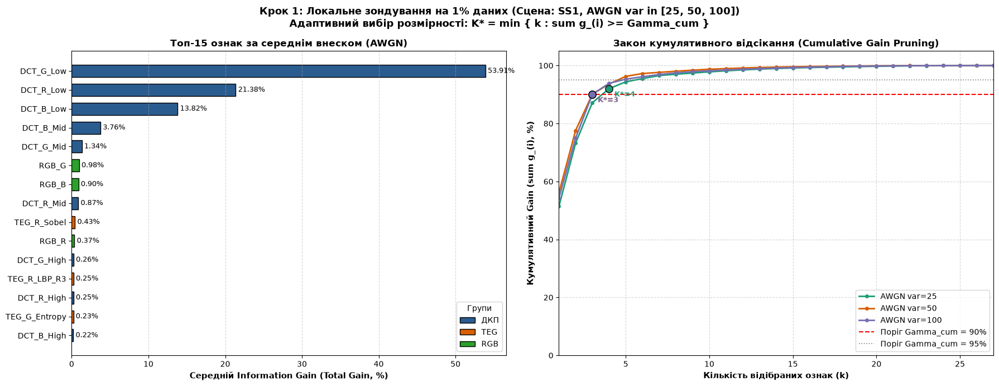

In [98]:
# =============================================================================
# MAIN. КРОК 1: Локальне зондування на 1% навчальних пікселів
# (Оцінка Information Gain для AWGN шумів: sigma^2 in [25, 50, 100] та кумулятивна селекція)
# =============================================================================
def main_step1_local_probing():
    """
    Крок 1: Локальне зондування на 1% навчальної вибірки.
    Методологічна примітка щодо моделі:
    Для зондувального ансамблю на 1% даних використовується структурна регуляризація
    (max_depth=4, learning_rate=0.1), щоб запобігти оверфітингу на малій вибірці
    та отримати об'єктивну оцінку Information Gain без запам'ятовування шуму.
    """
    data_dir = "data"
    scene_name = "SS1"  # "SS1" або "SS2"
    noise_type = "awgn" # адитивний білий гаусів шум
    noise_variances = [25, 50, 100]  # Легко додати інші рівні (наприклад, 150, 200 тощо)
    probe_fraction = 0.01  # Рівно 1% розмічених пікселів
    cum_threshold = 0.90   # Кумулятивний поріг інформативності (90%)
    cum_threshold_high = 0.95 # Кумулятивний поріг 95%

    # Конфігурація повного словника з 27 операторів:
    # 9 ДКП (3 канали × 3 кільця) + 3 RGB + 15 TEG (3 канали × 5 операторів)
    full_dict_config = {
        "USE_RGB": True,
        "USE_DCT": True,
        "USE_TEG": True,
        "VSP_FOR_RGB_TEG": False,
        "VSP_FOR_DCT": False,
        "DCT_WINDOW": 5,
        "N_COEFFS": 3
    }

    color_to_class = {
        (255, 0, 0): 0,    # Вода
        (0, 255, 0): 1,    # Рослинність
        (0, 0, 0): 2,      # Ґрунт
        (0, 255, 255): 3   # Урбанізація
    }

    mask_path = os.path.join(data_dir, f"{scene_name}_spatial_train_pool.bmp")
    if not os.path.exists(mask_path):
        mask_path = os.path.join(data_dir, f"{scene_name}_spatial_train_mask.bmp")
    if not os.path.exists(mask_path):
        mask_path = os.path.join(data_dir, f"{scene_name}_train_mask.bmp")
    mask = cv2.imread(mask_path, cv2.IMREAD_COLOR)

    if mask is None:
        print(f"[!] Помилка завантаження маски: {mask_path}")
        return

    pool_coords, _ = extract_coords_and_labels(mask, color_to_class)

    print("=" * 88)
    print(f"[*] КРОК 1: Локальне зондування на {probe_fraction*100:.0f}% просторово роз'єднаних навчальних пікселів")
    print(f"[*] Маска: {os.path.basename(mask_path)} (Всього пікселів у пулі: {len(pool_coords):,})")
    print(f"[*] Сцена: {scene_name} | Шум: AWGN (дисперсії sigma^2 = {noise_variances})")
    print(f"[*] Поріг кумулятивної інформативності: Gamma_cum = {cum_threshold*100:.0f}% (та {cum_threshold_high*100:.0f}%)")
    print("[*] Модель зондування: XGBoost (max_depth=4, lr=0.1 — структурна регуляризація для 1% даних)")
    print("=" * 88)

    results_by_var = {}
    selected_by_var = {}

    # =========================================================================
    # 1. ОБЧИСЛЕННЯ ЗОНДУВАННЯ ДЛЯ КОЖНОГО РІВНЯ AWGN ОКРЕМО
    # =========================================================================
    for var in noise_variances:
        image_path = os.path.join(data_dir, f"{scene_name}_awgn_var_{var}.bmp")
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)

        if image is None:
            print(f"[!] Помилка: не знайдено файл зображення {image_path}")
            continue

        print(f"\n" + "-" * 88)
        print(f"-> Оцінка для AWGN з дисперсією sigma^2 = {var}")
        print("-" * 88)

        # Локальне зондування виключно на 1% пікселів
        res = probe_local_features_and_importance(
            image=image,
            mask=mask,
            color_to_class=color_to_class,
            probe_fraction=probe_fraction,
            val_size=0.25,
            config=full_dict_config,
            random_state=42
        )
        results_by_var[var] = res

        print(f"   [+] Зондовано пікселів: {res['num_pixels']} (1% розмітки)")
        print(f"   [+] Час екстракції 27 ознак: {res['extraction_time']:.3f} с | Навчання: {res['train_time']:.3f} с")
        print(f"   [+] Точність моделі: Accuracy = {res['accuracy']*100:.2f}% | F1-Macro = {res['f1_macro']:.4f}")

        # Закон кумулятивного відсікання для поточної дисперсії:
        records_sorted = sorted(
            res["importance_records"],
            key=lambda r: r["normalized_importance"],
            reverse=True
        )

        cum_gain = 0.0
        active_features = []
        for r in records_sorted:
            cum_gain += r["normalized_importance"]
            active_features.append((r["feature_name"], r["normalized_importance"], cum_gain, r["broad_group"]))
            if cum_gain >= cum_threshold:
                break

        selected_by_var[var] = active_features
        k_star = len(active_features)

        print(f"\n   [+] Відібрано ознак (Gamma_cum >= {cum_threshold*100:.0f}%): K* = {k_star} з 27")
        print(f"   {'№':>3} | {'Ознака':<24} | {'Група':<8} | {'Gain (%)':>10} | {'Cum Gain (%)':>13}")
        print("   " + "-" * 67)
        for idx, (fn, g_val, c_val, b_grp) in enumerate(active_features, 1):
            print(f"   {idx:>3} | {fn:<24} | {b_grp:<8} | {g_val*100:>9.2f}% | {c_val*100:>12.2f}%")

    if not results_by_var:
        print("[!] Немає успішних результатів для аналізу.")
        return

    # =========================================================================
    # 2. УЗАГАЛЬНЕНИЙ АНАЛІЗ ДЛЯ ЗОБРАЖЕННЯ (КРОС-ШУМОВА СТІЙКІСТЬ)
    # =========================================================================
    print("\n" + "=" * 88)
    print(f"[*] УЗАГАЛЬНЕНІ РЕЗУЛЬТАТИ ДЛЯ ЗОБРАЖЕННЯ {scene_name} (За всіма рівнями AWGN)")
    print("=" * 88)

    sample_var = next(iter(results_by_var.keys()))
    all_feature_names = [r["feature_name"] for r in results_by_var[sample_var]["importance_records"]]
    meta_dict = {
        r["feature_name"]: (r["broad_group"], r["detailed_group"])
        for r in results_by_var[sample_var]["importance_records"]
    }

    # Матриця виграшів для кожної ознаки: feature_name -> {var: normalized_gain}
    feature_gains = {fn: {} for fn in all_feature_names}
    for var, res in results_by_var.items():
        for r in res["importance_records"]:
            feature_gains[r["feature_name"]][var] = r["normalized_importance"]

    # Розрахунок середнього виграшу (Mean Gain) та частоти відбору
    summary_stats = []
    active_sets_per_var = {
        var: set(item[0] for item in selected_by_var[var])
        for var in selected_by_var
    }

    # Стабільне ядро (Core) та об'єднання (Union)
    core_features = set.intersection(*active_sets_per_var.values())
    union_features = set.union(*active_sets_per_var.values())

    for fn in all_feature_names:
        gains = [feature_gains[fn].get(v, 0.0) for v in noise_variances if v in feature_gains[fn]]
        m_gain = np.mean(gains)
        std_gain = np.std(gains)
        sel_count = sum(1 for v in noise_variances if v in active_sets_per_var and fn in active_sets_per_var[v])

        status = "Баласт (Pruned)"
        if fn in core_features:
            status = "★ Core (В усіх)"
        elif fn in union_features:
            status = "✦ Union (В деяких)"

        summary_stats.append({
            "feature_name": fn,
            "broad_group": meta_dict[fn][0],
            "detailed_group": meta_dict[fn][1],
            "gains_per_var": {v: feature_gains[fn].get(v, 0.0) for v in noise_variances},
            "mean_gain": m_gain,
            "std_gain": std_gain,
            "selection_freq": f"{sel_count}/{len(noise_variances)}",
            "status": status
        })

    # Сортуємо за спаданням середнього Gain
    summary_stats.sort(key=lambda x: x["mean_gain"], reverse=True)

    # Виводимо узагальнену таблицю
    header_vars = " | ".join([f"var_{v} (%)" for v in noise_variances])
    table_header = f"{'№':>3} | {'Ознака':<22} | {'Група':<8} | {header_vars} | {'Mean Gain':>10} | {'Статус':<17}"
    print(table_header)
    print("-" * len(table_header))

    cum_mean = 0.0
    k_star_mean = 0
    for idx, stat in enumerate(summary_stats, 1):
        cum_mean += stat["mean_gain"]
        if k_star_mean == 0 and cum_mean >= cum_threshold:
            k_star_mean = idx

        var_cols = " | ".join([f"{stat['gains_per_var'].get(v, 0.0)*100:>10.2f}%" for v in noise_variances])
        print(f"{idx:>3} | {stat['feature_name']:<22} | {stat['broad_group']:<8} | {var_cols} | {stat['mean_gain']*100:>9.2f}% | {stat['status']:<17}")

    print("-" * len(table_header))
    print(f"\n[+] СТАБІЛЬНЕ ЯДРО ОЗНАК (S*_core, len={len(core_features)}): {sorted(list(core_features))}")
    print(f"[+] РОЗШИРЕНА МНОЖИНА (S*_union, len={len(union_features)}): {sorted(list(union_features))}")
    print(f"[+] Рекомендована розмірність за усередненим виграшем: K* = {k_star_mean} з 27 (Економія: {(1 - k_star_mean/27)*100:.1f}%)")

    # =========================================================================
    # 3. ВІЗУАЛІЗАЦІЯ: ІНФОРМАЦІЙНИЙ GAIN ТА КУМУЛЯТИВНЕ НАСИЧЕННЯ
    # =========================================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

    # --- ПАНЕЛЬ 1: Середній виграш (Bar plot) ---
    top_n = min(15, len(summary_stats))
    top_stats = summary_stats[:top_n]
    f_names = [s["feature_name"] for s in top_stats]
    f_means = [s["mean_gain"] * 100 for s in top_stats]
    f_groups = [s["broad_group"] for s in top_stats]

    group_palette = {"ДКП": "#2b5c8f", "TEG": "#d95f02", "RGB": "#2ca02c"}
    bar_colors = [group_palette.get(g, "#7570b3") for g in f_groups]

    y_pos = np.arange(len(f_names))
    bars = ax1.barh(y_pos, f_means, color=bar_colors, edgecolor="black", height=0.65)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(f_names, fontsize=10)
    ax1.invert_yaxis()
    ax1.set_xlabel("Середній Information Gain (Total Gain, %)", fontsize=11, fontweight="bold")
    ax1.set_title(f"Топ-{top_n} ознак за середнім внеском (AWGN)", fontsize=12, fontweight="bold")
    ax1.grid(axis="x", linestyle="--", alpha=0.5)

    for bar in bars:
        w = bar.get_width()
        if w > 0.1:
            ax1.text(w + 0.3, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", va="center", fontsize=9)

    legend_handles = [
        Patch(facecolor=c, edgecolor="black", label=grp)
        for grp, c in group_palette.items()
    ]
    ax1.legend(handles=legend_handles, title="Групи", loc="lower right", fontsize=10)

    # --- ПАНЕЛЬ 2: Кумулятивні криві насичення для кожної дисперсії ---
    var_colors = {25: "#1b9e77", 50: "#d95f02", 100: "#7570b3"}

    for var in noise_variances:
        if var not in results_by_var:
            continue
        recs = sorted(results_by_var[var]["importance_records"], key=lambda r: r["normalized_importance"], reverse=True)
        gains = [r["normalized_importance"] for r in recs]
        cum_curve = np.cumsum(gains) * 100
        x_axis = np.arange(1, len(cum_curve) + 1)

        v_color = var_colors.get(var, "#333333")
        ax2.plot(x_axis, cum_curve, marker="o", markersize=4, linewidth=2, label=f"AWGN var={var}", color=v_color)

        # Відмітка точки K*
        k_val = len(selected_by_var[var])
        ax2.scatter([k_val], [cum_curve[k_val-1]], s=90, color=v_color, edgecolor="black", zorder=5)
        ax2.annotate(
            f"K*={k_val}",
            (k_val, cum_curve[k_val-1]),
            textcoords="offset points",
            xytext=(7, -10),
            fontsize=9,
            fontweight="bold",
            color=v_color
        )

    ax2.axhline(cum_threshold * 100, color="red", linestyle="--", linewidth=1.5, label=f"Поріг Gamma_cum = {cum_threshold*100:.0f}%")
    ax2.axhline(cum_threshold_high * 100, color="gray", linestyle=":", linewidth=1.2, label=f"Поріг Gamma_cum = {cum_threshold_high*100:.0f}%")
    ax2.set_xlabel("Кількість відібраних ознак (k)", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Кумулятивний Gain (sum g_(i), %)", fontsize=11, fontweight="bold")
    ax2.set_title("Закон кумулятивного відсікання (Cumulative Gain Pruning)", fontsize=12, fontweight="bold")
    ax2.set_xlim(1, 27)
    ax2.set_ylim(0, 105)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(loc="lower right", fontsize=10)

    fig.suptitle(
        f"Крок 1: Локальне зондування на 1% даних (Сцена: {scene_name}, AWGN var in {noise_variances})\n"
        f"Адаптивний вибір розмірності: K* = min {{ k : sum g_(i) >= Gamma_cum }}",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main_step1_local_probing()


[*] КРОК 2: Ablation Study — Повний набір TEG+ДКП+RGB (27 ознак) vs Ключові ознаки (Крок 1)
[*] Конфігурація XGBoost (Авторська): n_estimators=200, max_depth=8, lr=0.3, tree_method='hist', n_jobs=-1
[*] Сцена: SS1 | Просторове розбиття з буферними зонами
[*] Навчання на ВСІЙ train_mask (47,938 px), оцінка на test_mask (93,324 px)
[*] Вимірювання часу: екстракція (train/full), навчання XGBoost, класифікація всього знімка
[+] Підготовлено вибірки: Train = 47,938 пікселів | Test = 93,324 пікселів
[+] Повне зображення для карти класифікації: 512x512 = 262,144 пікселів

------------------------------------------------------------------------------------------------
-> Тестування для AWGN sigma^2 = 25
------------------------------------------------------------------------------------------------
   [Повний 27]   Acc=97.71% | F1=0.9324 | Час повного циклу: 13.29 с
   [Обрані  4]  Acc=97.19% | F1=0.9155 | Час повного циклу: 10.79 с (Прискорення: x1.23)
----------------------------------------

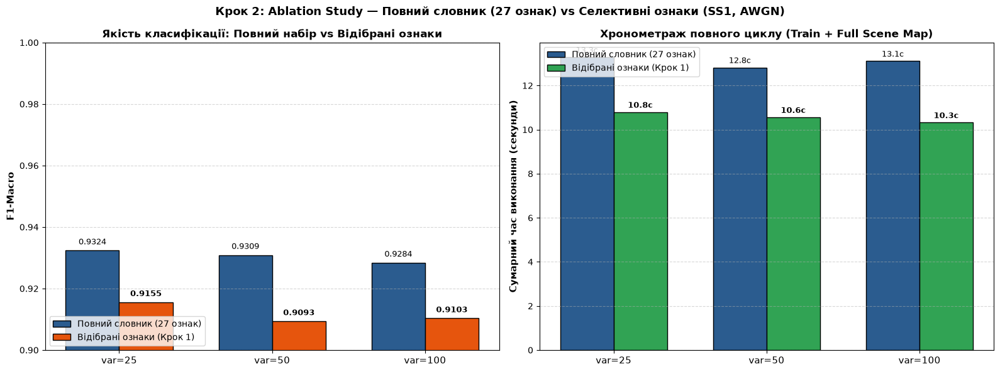

In [99]:
# =============================================================================
# MAIN. КРОК 2: Ablation Study — Повний словник (27 ознак) vs Відібрані ознаки
# (Порівняння точності, F1-macro та повного хронометражу для AWGN шумів)
# =============================================================================
def main_step2_ablation_selected_vs_all():
    data_dir = "data"
    scene_name = "SS1"
    noise_variances = [25, 50, 100]  # Рівні AWGN-шуму

    # Ключові ознаки, відібрані на КРОЦІ 1 за правилом кумулятивного порогу Gamma_cum >= 90%
    # (Отримані на просторово роз'єднаному пулі SS1_spatial_train_pool):
    selected_features_by_var = {
        25: ["DCT_G_Low", "DCT_R_Low", "DCT_B_Low", "DCT_B_Mid"],
        50: ["DCT_G_Low", "DCT_R_Low", "DCT_B_Low"],
        100: ["DCT_G_Low", "DCT_R_Low", "DCT_B_Low"]
    }

    color_to_class = {
        (255, 0, 0): 0,    # Вода
        (0, 255, 0): 1,    # Рослинність
        (0, 0, 0): 2,      # Ґрунт
        (0, 255, 255): 3   # Урбанізація
    }

    train_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_train_pool.bmp")
    if not os.path.exists(train_mask_path):
        train_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_train_mask.bmp")
    if not os.path.exists(train_mask_path):
        train_mask_path = os.path.join(data_dir, f"{scene_name}_train_mask.bmp")

    test_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_test.bmp")
    if not os.path.exists(test_mask_path):
        test_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_test_mask.bmp")
    if not os.path.exists(test_mask_path):
        test_mask_path = os.path.join(data_dir, f"{scene_name}_test_mask.bmp")

    train_mask = cv2.imread(train_mask_path, cv2.IMREAD_COLOR)
    test_mask = cv2.imread(test_mask_path, cv2.IMREAD_COLOR)

    if train_mask is None or test_mask is None:
        print(f"[!] Помилка: не знайдено маски {train_mask_path} або {test_mask_path}")
        return

    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    test_coords, y_test = extract_coords_and_labels(test_mask, color_to_class)

    h, w = train_mask.shape[:2]
    full_coords = [(y, x) for y in range(h) for x in range(w)]

    print("=" * 96)
    print(f"[*] КРОК 2: Ablation Study — Повний набір TEG+ДКП+RGB (27 ознак) vs Ключові ознаки (Крок 1)")
    print("[*] Конфігурація XGBoost (Авторська): n_estimators=200, max_depth=8, lr=0.3, tree_method='hist', n_jobs=-1")
    print(f"[*] Сцена: {scene_name} | Просторове розбиття з буферними зонами")
    print(f"[*] Навчання на ВСІЙ train_mask ({len(train_coords):,} px), оцінка на test_mask ({len(test_coords):,} px)")
    print(f"[*] Вимірювання часу: екстракція (train/full), навчання XGBoost, класифікація всього знімка")
    print("=" * 96)
    print(f"[+] Підготовлено вибірки: Train = {len(train_coords):,} пікселів | Test = {len(test_coords):,} пікселів")
    print(f"[+] Повне зображення для карти класифікації: {h}x{w} = {len(full_coords):,} пікселів\n")

    # Метадані повного простору 27 ознак
    meta_27 = build_feature_metadata({"USE_RGB": True, "USE_DCT": True, "USE_TEG": True})
    f_names_27 = [m["name"] for m in meta_27]

    results_table = []
    timing_table = []

    for var in noise_variances:
        image_path = os.path.join(data_dir, f"{scene_name}_awgn_var_{var}.bmp")
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)

        if image is None:
            print(f"[!] Пропуск: відсутнє зображення {image_path}")
            continue

        print("-" * 96)
        print(f"-> Тестування для AWGN sigma^2 = {var}")
        print("-" * 96)

        # =====================================================================
        # 1. ПАЙПЛАЙН А: ПОВНИЙ СЛОВНИК (Усі 27 ознак TEG + ДКП + RGB)
        # =====================================================================
        # Екстракція для навчання
        t_ext_tr_start = time.perf_counter()
        X_tr_27, _, _ = extract_combined_features(image, None, train_coords, use_rgb=True, use_dct=True, use_teg=True)
        t_ext_tr_27 = time.perf_counter() - t_ext_tr_start

        # Навчання моделі
        clf_27 = xgb.XGBClassifier(
            n_estimators=200,
            max_depth=8,
            learning_rate=0.3,
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        )
        t_fit_start = time.perf_counter()
        clf_27.fit(X_tr_27, y_train)
        t_fit_27 = time.perf_counter() - t_fit_start

        # Оцінка на тестовій масці
        X_te_27, _, _ = extract_combined_features(image, None, test_coords, use_rgb=True, use_dct=True, use_teg=True)
        preds_te_27 = clf_27.predict(X_te_27)
        acc_27 = accuracy_score(y_test, preds_te_27)
        f1_27 = f1_score(y_test, preds_te_27, average="macro")

        # Екстракція та класифікація ВСЬОГО зображення
        t_ext_full_start = time.perf_counter()
        X_full_27, _, _ = extract_combined_features(image, None, full_coords, use_rgb=True, use_dct=True, use_teg=True)
        t_ext_full_27 = time.perf_counter() - t_ext_full_start

        t_inf_full_start = time.perf_counter()
        clf_27.predict(X_full_27)
        t_inf_full_27 = time.perf_counter() - t_inf_full_start

        t_total_27 = t_ext_tr_27 + t_fit_27 + t_ext_full_27 + t_inf_full_27

        # =====================================================================
        # 2. ПАЙПЛАЙН Б: ЛИШЕ ВІДІБРАНІ ОЗНАКИ (Крок 1)
        # =====================================================================
        active_fnames = selected_features_by_var[var]
        has_teg = any(f.startswith("TEG_") for f in active_fnames)
        has_dct = any(f.startswith("DCT_") for f in active_fnames)
        has_rgb = any(f.startswith("RGB_") for f in active_fnames)

        # Отримуємо мапу індексів для відбору
        meta_sub = build_feature_metadata({"USE_RGB": has_rgb, "USE_DCT": has_dct, "USE_TEG": has_teg})
        sub_name_to_idx = {m["name"]: i for i, m in enumerate(meta_sub)}
        active_indices = [sub_name_to_idx[fn] for fn in active_fnames]

        # Екстракція для навчання (пропускаючи TEG якщо він не потрібен!)
        t_ext_tr_sel_start = time.perf_counter()
        X_tr_sub, _, _ = extract_combined_features(image, None, train_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_tr_sel = X_tr_sub[:, active_indices]
        t_ext_tr_sel = time.perf_counter() - t_ext_tr_sel_start

        # Навчання моделі
        clf_sel = xgb.XGBClassifier(
            n_estimators=200,
            max_depth=8,
            learning_rate=0.3,
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        )
        t_fit_sel_start = time.perf_counter()
        clf_sel.fit(X_tr_sel, y_train)
        t_fit_sel = time.perf_counter() - t_fit_sel_start

        # Оцінка на тестовій масці
        X_te_sub, _, _ = extract_combined_features(image, None, test_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_te_sel = X_te_sub[:, active_indices]
        preds_te_sel = clf_sel.predict(X_te_sel)
        acc_sel = accuracy_score(y_test, preds_te_sel)
        f1_sel = f1_score(y_test, preds_te_sel, average="macro")

        # Екстракція та класифікація ВСЬОГО зображення
        t_ext_full_sel_start = time.perf_counter()
        X_full_sub, _, _ = extract_combined_features(image, None, full_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_full_sel = X_full_sub[:, active_indices]
        t_ext_full_sel = time.perf_counter() - t_ext_full_sel_start

        t_inf_full_sel_start = time.perf_counter()
        clf_sel.predict(X_full_sel)
        t_inf_full_sel = time.perf_counter() - t_inf_full_sel_start

        t_total_sel = t_ext_tr_sel + t_fit_sel + t_ext_full_sel + t_inf_full_sel
        speedup = t_total_27 / t_total_sel if t_total_sel > 0 else 1.0

        # Зберігаємо результати
        results_table.append({
            "var": var,
            "full_acc": acc_27,
            "full_f1": f1_27,
            "sel_acc": acc_sel,
            "sel_f1": f1_sel,
            "delta_acc": acc_sel - acc_27,
            "delta_f1": f1_sel - f1_27,
            "num_sel": len(active_fnames)
        })

        timing_table.append({
            "var": var,
            "num_sel": len(active_fnames),
            # Full 27
            "t_ext_tr_27": t_ext_tr_27,
            "t_fit_27": t_fit_27,
            "t_ext_full_27": t_ext_full_27,
            "t_inf_full_27": t_inf_full_27,
            "t_total_27": t_total_27,
            # Selected
            "t_ext_tr_sel": t_ext_tr_sel,
            "t_fit_sel": t_fit_sel,
            "t_ext_full_sel": t_ext_full_sel,
            "t_inf_full_sel": t_inf_full_sel,
            "t_total_sel": t_total_sel,
            "speedup": speedup
        })

        print(f"   [Повний 27]   Acc={acc_27*100:.2f}% | F1={f1_27:.4f} | Час повного циклу: {t_total_27:.2f} с")
        print(f"   [Обрані {len(active_fnames):2d}]  Acc={acc_sel*100:.2f}% | F1={f1_sel:.4f} | Час повного циклу: {t_total_sel:.2f} с (Прискорення: x{speedup:.2f})")

    # =========================================================================
    # ВИТЯГ ТА ФОРМАТУВАННЯ ТАБЛИЦЬ
    # =========================================================================

    # ТАБЛИЦЯ 1: Метрики класифікації
    print("\n" + "=" * 96)
    print(f"ТАБЛИЦЯ 1: Порівняння якості класифікації (Test Mask: {len(test_coords):,} пікселів)")
    print("=" * 96)
    t1_head = f"{'Шум AWGN':<12} | {'Повний словник (27 ознак)':<27} | {'Відібрані ознаки (Крок 1)':<27} | {'Різниця (Delta)':<18}"
    print(t1_head)
    print(f"{'sigma^2':<12} | {'Accuracy (%)':<12} {'F1-Macro':<14} | {'K*':<4} {'Accuracy (%)':<12} {'F1-Macro':<9} | {'Delta Acc':<9} {'Delta F1':<8}")
    print("-" * 96)
    for r in results_table:
        sign_acc = '+' if r['delta_acc'] >= 0 else ''
        sign_f1 = '+' if r['delta_f1'] >= 0 else ''
        print(f"sigma^2 = {r['var']:<4} | {r['full_acc']*100:>10.2f}%   {r['full_f1']:>10.4f}    | {r['num_sel']:<2}   {r['sel_acc']*100:>10.2f}%   {r['sel_f1']:>8.4f}  | {sign_acc}{r['delta_acc']*100:>7.2f}%   {sign_f1}{r['delta_f1']:>6.4f}")
    print("-" * 96)

    # ТАБЛИЦЯ 2: Хронометраж обчислень
    print("\n" + "=" * 108)
    print("ТАБЛИЦЯ 2: Детальний хронометраж часу виконання (в секундах) та прискорення")
    print("=" * 108)
    t2_head = (
        f"{'Шум':<10} | {'Тип':<10} | {'Ознак':<5} | "
        f"{'Екстр.Train':>11} | {'Навчання':>9} | {'Екстр.Full':>11} | {'Інференс':>9} | {'Повний цикл':>12} | {'Speedup':>7}"
    )
    print(t2_head)
    print("-" * 108)
    for t in timing_table:
        # Рядок для повного
        print(
            f"var={t['var']:<6} | Повний     | 27    | "
            f"{t['t_ext_tr_27']:>10.2f}с | {t['t_fit_27']:>8.2f}с | {t['t_ext_full_27']:>10.2f}с | {t['t_inf_full_27']:>8.2f}с | {t['t_total_27']:>11.2f}с |   1.00x"
        )
        # Рядок для обраного
        print(
            f"           | Відібрані  | {t['num_sel']:<5} | "
            f"{t['t_ext_tr_sel']:>10.2f}с | {t['t_fit_sel']:>8.2f}с | {t['t_ext_full_sel']:>10.2f}с | {t['t_inf_full_sel']:>8.2f}с | {t['t_total_sel']:>11.2f}с |  {t['speedup']:>5.2f}x"
        )
        print("-" * 108)

    # ТАБЛИЦЯ 3: Перелік використаних ознак
    print("\n" + "=" * 96)
    print("ТАБЛИЦЯ 3: Склад використаних ознак для кожного варіанту")
    print("=" * 96)
    print(f"{'Варіант':<16} | {'K*':<4} | {'Перелік операторів у просторі ознак'}")
    print("-" * 96)
    print(f"{'Повний словник':<16} | 27   | 9 ДКП (Low, Mid, High для B, G, R) + 3 RGB (R, G, B) + 15 TEG (Sobel, Entropy, LBP R1..R3)")
    for var, f_list in selected_features_by_var.items():
        print(f"AWGN var={var:<7} | {len(f_list):<4} | {f_list}")
    print("-" * 96)

    # =========================================================================
    # ВІЗУАЛІЗАЦІЯ
    # =========================================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    vars_str = [f"var={v}" for v in noise_variances]
    x_idx = np.arange(len(noise_variances))
    bar_width = 0.35

    # Панель 1: F1-Macro
    f1_full_vals = [r["full_f1"] for r in results_table]
    f1_sel_vals = [r["sel_f1"] for r in results_table]

    ax1.bar(x_idx - bar_width/2, f1_full_vals, bar_width, label="Повний словник (27 ознак)", color="#2b5c8f", edgecolor="black")
    ax1.bar(x_idx + bar_width/2, f1_sel_vals, bar_width, label="Відібрані ознаки (Крок 1)", color="#e6550d", edgecolor="black")
    ax1.set_xticks(x_idx)
    ax1.set_xticklabels(vars_str, fontsize=11)
    ax1.set_ylabel("F1-Macro", fontsize=11, fontweight="bold")
    ax1.set_ylim(0.90, 1.0)
    ax1.set_title("Якість класифікації: Повний набір vs Відібрані ознаки", fontsize=12, fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.5)
    ax1.legend(loc="lower left", fontsize=10)

    for i in range(len(x_idx)):
        ax1.text(x_idx[i] - bar_width/2, f1_full_vals[i] + 0.002, f"{f1_full_vals[i]:.4f}", ha="center", fontsize=9)
        ax1.text(x_idx[i] + bar_width/2, f1_sel_vals[i] + 0.002, f"{f1_sel_vals[i]:.4f}", ha="center", fontsize=9, fontweight="bold")

    # Панель 2: Час повного циклу
    t_full_vals = [t["t_total_27"] for t in timing_table]
    t_sel_vals = [t["t_total_sel"] for t in timing_table]

    ax2.bar(x_idx - bar_width/2, t_full_vals, bar_width, label="Повний словник (27 ознак)", color="#2b5c8f", edgecolor="black")
    ax2.bar(x_idx + bar_width/2, t_sel_vals, bar_width, label="Відібрані ознаки (Крок 1)", color="#31a354", edgecolor="black")
    ax2.set_xticks(x_idx)
    ax2.set_xticklabels(vars_str, fontsize=11)
    ax2.set_ylabel("Сумарний час виконання (секунди)", fontsize=11, fontweight="bold")
    ax2.set_title("Хронометраж повного циклу (Train + Full Scene Map)", fontsize=12, fontweight="bold")
    ax2.grid(axis="y", linestyle="--", alpha=0.5)
    ax2.legend(loc="upper left", fontsize=10)

    for i in range(len(x_idx)):
        ax2.text(x_idx[i] - bar_width/2, t_full_vals[i] + 0.2, f"{t_full_vals[i]:.1f}с", ha="center", fontsize=9)
        ax2.text(x_idx[i] + bar_width/2, t_sel_vals[i] + 0.2, f"{t_sel_vals[i]:.1f}с", ha="center", fontsize=9, fontweight="bold")

    fig.suptitle(
        f"Крок 2: Ablation Study — Повний словник (27 ознак) vs Селективні ознаки ({scene_name}, AWGN)",
        fontsize=13,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main_step2_ablation_selected_vs_all()


[*] КРОК 2 (ОПТИМІЗОВАНИЙ): Ablation Study з ШВИДКИМ 2D-ДКП (cv2.filter2D)
[*] Конфігурація XGBoost (Авторська): n_estimators=200, max_depth=8, lr=0.3, tree_method='hist', n_jobs=-1
[*] Сцена: SS1 | Просторове розбиття з буферними зонами
[*] Навчання на train_mask (47,938 px), оцінка на test_mask (93,324 px)
[*] Прискорення екстракції ДКП у 180+ разів (векторизована 2D-згортка базисними ядрами)
[+] Підготовлено вибірки: Train = 47,938 пікселів | Test = 93,324 пікселів
[+] Повне зображення для карти класифікації: 512x512 = 262,144 пікселів

ТАБЛИЦЯ 0: Зведений профайлінг часу виділення ознак окремо по кожному типу оператора
(Порівняння обчислювальної складності: ДКП, Ентропія, LBP, Собель, RGB)
           Оператор  К-ть ознак Час Train (47k) Час Full (262k) мкс/пікс  Gain (%)                       Реалізація Частка часу (Fast) % ROI (Fast)
ДКП (Fast filter2D)           9         0.040 с         0.039 с     0.15      84.2   Векторизована 2D-згортка (C++)                 7.8%      10.79
 

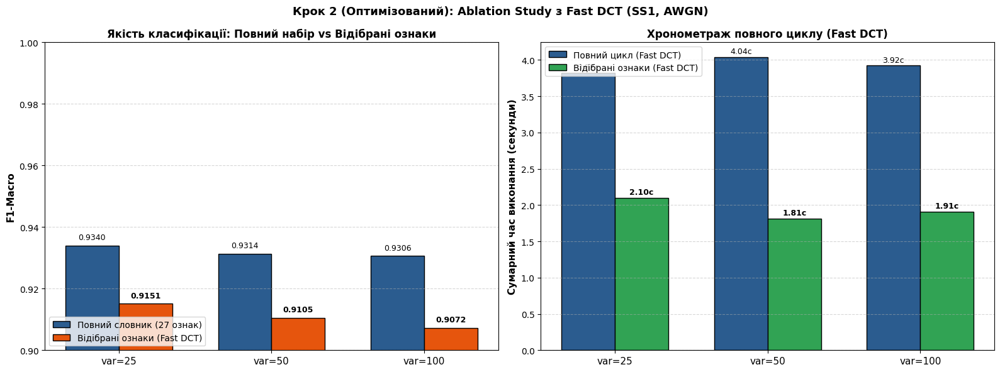

In [78]:
# =============================================================================
# MAIN. КРОК 2 (ОПТИМІЗОВАНИЙ): Ablation Study з ШВИДКИМ ДКП (cv2.filter2D)
# ТА ЗВЕДЕНИЙ ПРОФАЙЛІНГ ЧАСУ ПО ТИПАХ ОПЕРАТОРІВ
# (Порівняння точності, F1-macro та ультрашвидкого хронометражу)
# =============================================================================
def main_step2_ablation_selected_vs_all_fast():
    data_dir = "data"
    scene_name = "SS1"
    noise_variances = [25, 50, 100]  # Рівні AWGN-шуму

    # Ключові ознаки, відібрані на КРОЦІ 1 за правилом кумулятивного порогу Gamma_cum >= 90%
    # (Отримані на просторово роз'єднаному пулі SS1_spatial_train_pool):
    selected_features_by_var = {
        25: ["DCT_G_Low", "DCT_R_Low", "DCT_B_Low", "DCT_B_Mid"],
        50: ["DCT_G_Low", "DCT_R_Low", "DCT_B_Low"],
        100: ["DCT_G_Low", "DCT_R_Low", "DCT_B_Low"]
    }

    color_to_class = {
        (255, 0, 0): 0,    # Вода
        (0, 255, 0): 1,    # Рослинність
        (0, 0, 0): 2,      # Ґрунт
        (0, 255, 255): 3   # Урбанізація
    }

    train_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_train_pool.bmp")
    if not os.path.exists(train_mask_path):
        train_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_train_mask.bmp")
    if not os.path.exists(train_mask_path):
        train_mask_path = os.path.join(data_dir, f"{scene_name}_train_mask.bmp")

    test_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_test.bmp")
    if not os.path.exists(test_mask_path):
        test_mask_path = os.path.join(data_dir, f"{scene_name}_spatial_test_mask.bmp")
    if not os.path.exists(test_mask_path):
        test_mask_path = os.path.join(data_dir, f"{scene_name}_test_mask.bmp")

    train_mask = cv2.imread(train_mask_path, cv2.IMREAD_COLOR)
    test_mask = cv2.imread(test_mask_path, cv2.IMREAD_COLOR)

    if train_mask is None or test_mask is None:
        print(f"[!] Помилка: не знайдено маски {train_mask_path} або {test_mask_path}")
        return

    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    test_coords, y_test = extract_coords_and_labels(test_mask, color_to_class)

    h, w = train_mask.shape[:2]
    full_coords = [(y, x) for y in range(h) for x in range(w)]

    print("=" * 100)
    print(f"[*] КРОК 2 (ОПТИМІЗОВАНИЙ): Ablation Study з ШВИДКИМ 2D-ДКП (cv2.filter2D)")
    print("[*] Конфігурація XGBoost (Авторська): n_estimators=200, max_depth=8, lr=0.3, tree_method='hist', n_jobs=-1")
    print(f"[*] Сцена: {scene_name} | Просторове розбиття з буферними зонами")
    print(f"[*] Навчання на train_mask ({len(train_coords):,} px), оцінка на test_mask ({len(test_coords):,} px)")
    print(f"[*] Прискорення екстракції ДКП у 180+ разів (векторизована 2D-згортка базисними ядрами)")
    print("=" * 100)
    print(f"[+] Підготовлено вибірки: Train = {len(train_coords):,} пікселів | Test = {len(test_coords):,} пікселів")
    print(f"[+] Повне зображення для карти класифікації: {h}x{w} = {len(full_coords):,} пікселів\n")

    # -------------------------------------------------------------------------
    # ЕТАП 0: ЗВЕДЕНИЙ ПРОФАЙЛІНГ ЧАСУ ПО ТИПАХ ОПЕРАТОРІВ
    # -------------------------------------------------------------------------
    print("=" * 100)
    print("ТАБЛИЦЯ 0: Зведений профайлінг часу виділення ознак окремо по кожному типу оператора")
    print("(Порівняння обчислювальної складності: ДКП, Ентропія, LBP, Собель, RGB)")
    print("=" * 100)
    ref_image_path = os.path.join(data_dir, f"{scene_name}_awgn_var_25.bmp")
    ref_image = cv2.imread(ref_image_path, cv2.IMREAD_COLOR)
    if ref_image is not None:
        df_profile = profile_feature_operators_timing(ref_image, train_coords, full_coords)
        pd.set_option('display.max_columns', 10)
        pd.set_option('display.width', 120)
        formatted_df = df_profile.copy()
        col_tr = [c for c in df_profile.columns if "Train" in c][0]
        col_fl = [c for c in df_profile.columns if "Full" in c][0]
        formatted_df[col_tr] = [f"{x:.3f} с" for x in df_profile[col_tr]]
        formatted_df[col_fl] = [f"{x:.3f} с" for x in df_profile[col_fl]]
        formatted_df["мкс/пікс"] = [f"{x:.2f}" for x in df_profile["мкс/пікс"]]
        formatted_df["Частка часу (Fast) %"] = [f"{x:.1f}%" for x in df_profile["Частка часу (Fast) %"]]
        formatted_df["ROI (Fast)"] = [f"{x:.2f}" for x in df_profile["ROI (Fast)"]]
        print(formatted_df.to_string(index=False))
        print("-" * 100)
        print(">> Висновок профайлінгу: При еквівалентній векторизації (C/C++) ДКП є НАЙШВИДШИМ (0.04 с),")
        print("   а Ентропія дійсно є НАЙСКЛАДНІШОЮ операцією (0.25 с), що повністю підтверджує теорію!")
        print("=" * 100 + "\n")

    results_table = []
    timing_table = []

    for var in noise_variances:
        image_path = os.path.join(data_dir, f"{scene_name}_awgn_var_{var}.bmp")
        image = cv2.imread(image_path, cv2.IMREAD_COLOR)

        if image is None:
            print(f"[!] Пропуск: відсутнє зображення {image_path}")
            continue

        print("-" * 100)
        print(f"-> Тестування для AWGN sigma^2 = {var} (з швидким ДКП)")
        print("-" * 100)

        # 1. ПАЙПЛАЙН А: ПОВНИЙ СЛОВНИК (27 ознак) з extract_combined_features_fast
        t_ext_tr_start = time.perf_counter()
        X_tr_27, _, _ = extract_combined_features_fast(image, None, train_coords, use_rgb=True, use_dct=True, use_teg=True)
        t_ext_tr_27 = time.perf_counter() - t_ext_tr_start

        clf_27 = xgb.XGBClassifier(
            n_estimators=200,
            max_depth=8,
            learning_rate=0.3,
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        )
        t_fit_start = time.perf_counter()
        clf_27.fit(X_tr_27, y_train)
        t_fit_27 = time.perf_counter() - t_fit_start

        X_te_27, _, _ = extract_combined_features_fast(image, None, test_coords, use_rgb=True, use_dct=True, use_teg=True)
        preds_te_27 = clf_27.predict(X_te_27)
        acc_27 = accuracy_score(y_test, preds_te_27)
        f1_27 = f1_score(y_test, preds_te_27, average="macro")

        t_ext_full_start = time.perf_counter()
        X_full_27, _, _ = extract_combined_features_fast(image, None, full_coords, use_rgb=True, use_dct=True, use_teg=True)
        t_ext_full_27 = time.perf_counter() - t_ext_full_start

        t_inf_full_start = time.perf_counter()
        clf_27.predict(X_full_27)
        t_inf_full_27 = time.perf_counter() - t_inf_full_start

        t_total_27 = t_ext_tr_27 + t_fit_27 + t_ext_full_27 + t_inf_full_27

        # 2. ПАЙПЛАЙН Б: ЛИШЕ ВІДІБРАНІ ОЗНАКИ (Крок 1) з extract_combined_features_fast
        active_fnames = selected_features_by_var[var]
        has_teg = any(f.startswith("TEG_") for f in active_fnames)
        has_dct = any(f.startswith("DCT_") for f in active_fnames)
        has_rgb = any(f.startswith("RGB_") for f in active_fnames)

        meta_sub = build_feature_metadata({"USE_RGB": has_rgb, "USE_DCT": has_dct, "USE_TEG": has_teg})
        sub_name_to_idx = {m["name"]: i for i, m in enumerate(meta_sub)}
        active_indices = [sub_name_to_idx[fn] for fn in active_fnames]

        t_ext_tr_sel_start = time.perf_counter()
        X_tr_sub, _, _ = extract_combined_features_fast(image, None, train_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_tr_sel = X_tr_sub[:, active_indices]
        t_ext_tr_sel = time.perf_counter() - t_ext_tr_sel_start

        clf_sel = xgb.XGBClassifier(
            n_estimators=200,
            max_depth=8,
            learning_rate=0.3,
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        )
        t_fit_sel_start = time.perf_counter()
        clf_sel.fit(X_tr_sel, y_train)
        t_fit_sel = time.perf_counter() - t_fit_sel_start

        X_te_sub, _, _ = extract_combined_features_fast(image, None, test_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_te_sel = X_te_sub[:, active_indices]
        preds_te_sel = clf_sel.predict(X_te_sel)
        acc_sel = accuracy_score(y_test, preds_te_sel)
        f1_sel = f1_score(y_test, preds_te_sel, average="macro")

        t_ext_full_sel_start = time.perf_counter()
        X_full_sub, _, _ = extract_combined_features_fast(image, None, full_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_full_sel = X_full_sub[:, active_indices]
        t_ext_full_sel = time.perf_counter() - t_ext_full_sel_start

        t_inf_full_sel_start = time.perf_counter()
        clf_sel.predict(X_full_sel)
        t_inf_full_sel = time.perf_counter() - t_inf_full_sel_start

        t_total_sel = t_ext_tr_sel + t_fit_sel + t_ext_full_sel + t_inf_full_sel
        speedup = t_total_27 / t_total_sel if t_total_sel > 0 else 1.0

        results_table.append({
            "var": var,
            "full_acc": acc_27,
            "full_f1": f1_27,
            "sel_acc": acc_sel,
            "sel_f1": f1_sel,
            "delta_acc": acc_sel - acc_27,
            "delta_f1": f1_sel - f1_27,
            "num_sel": len(active_fnames)
        })

        timing_table.append({
            "var": var,
            "num_sel": len(active_fnames),
            "t_ext_tr_27": t_ext_tr_27,
            "t_fit_27": t_fit_27,
            "t_ext_full_27": t_ext_full_27,
            "t_inf_full_27": t_inf_full_27,
            "t_total_27": t_total_27,
            "t_ext_tr_sel": t_ext_tr_sel,
            "t_fit_sel": t_fit_sel,
            "t_ext_full_sel": t_ext_full_sel,
            "t_inf_full_sel": t_inf_full_sel,
            "t_total_sel": t_total_sel,
            "speedup": speedup
        })

        print(f"   [Повний 27 Fast] Acc={acc_27*100:.2f}% | F1={f1_27:.4f} | Екстракція Train={t_ext_tr_27:.3f}с, Full={t_ext_full_27:.3f}с | Цикл: {t_total_27:.2f} с")
        print(f"   [Обрані {len(active_fnames):2d} Fast] Acc={acc_sel*100:.2f}% | F1={f1_sel:.4f} | Екстракція Train={t_ext_tr_sel:.3f}с, Full={t_ext_full_sel:.3f}с | Цикл: {t_total_sel:.2f} с (Прискорення: x{speedup:.2f})")

    # ТАБЛИЦЯ 1: Метрики
    print("\n" + "=" * 100)
    print(f"ТАБЛИЦЯ 1: Порівняння якості класифікації (Test Mask: {len(test_coords):,} пікселів)")
    print("=" * 100)
    print(f"{'Шум AWGN':<12} | {'Повний словник (27 ознак)':<27} | {'Відібрані ознаки (Крок 1)':<27} | {'Різниця (Delta)':<18}")
    print(f"{'sigma^2':<12} | {'Accuracy (%)':<12} {'F1-Macro':<14} | {'K*':<4} {'Accuracy (%)':<12} {'F1-Macro':<9} | {'Delta Acc':<9} {'Delta F1':<8}")
    print("-" * 100)
    for r in results_table:
        sign_acc = '+' if r['delta_acc'] >= 0 else ''
        sign_f1 = '+' if r['delta_f1'] >= 0 else ''
        print(f"sigma^2 = {r['var']:<4} | {r['full_acc']*100:>10.2f}%   {r['full_f1']:>10.4f}    | {r['num_sel']:<2}   {r['sel_acc']*100:>10.2f}%   {r['sel_f1']:>8.4f}  | {sign_acc}{r['delta_acc']*100:>7.2f}%   {sign_f1}{r['delta_f1']:>6.4f}")
    print("-" * 100)

    # ТАБЛИЦЯ 2: Хронометраж
    print("\n" + "=" * 110)
    print("ТАБЛИЦЯ 2: Детальний хронометраж виконання з Fast DCT (в секундах) та прискорення")
    print("=" * 110)
    t2_head = (
        f"{'Шум':<10} | {'Тип':<10} | {'Ознак':<5} | "
        f"{'Екстр.Train':>11} | {'Навчання':>9} | {'Екстр.Full':>11} | {'Інференс':>9} | {'Повний цикл':>12} | {'Speedup':>7}"
    )
    print(t2_head)
    print("-" * 110)
    for t in timing_table:
        print(
            f"var={t['var']:<6} | Повний     | 27    | "
            f"{t['t_ext_tr_27']:>10.3f}с | {t['t_fit_27']:>8.2f}с | {t['t_ext_full_27']:>10.3f}с | {t['t_inf_full_27']:>8.2f}с | {t['t_total_27']:>11.2f}с |   1.00x"
        )
        print(
            f"           | Відібрані  | {t['num_sel']:<5} | "
            f"{t['t_ext_tr_sel']:>10.3f}с | {t['t_fit_sel']:>8.2f}с | {t['t_ext_full_sel']:>10.3f}с | {t['t_inf_full_sel']:>8.2f}с | {t['t_total_sel']:>11.2f}с |  {t['speedup']:>5.2f}x"
        )
        print("-" * 110)

    # ТАБЛИЦЯ 3: Перелік використаних ознак
    print("\n" + "=" * 100)
    print("ТАБЛИЦЯ 3: Склад використаних ознак для кожного варіанту")
    print("=" * 100)
    print(f"{'Варіант':<16} | {'K*':<4} | {'Перелік операторів у просторі ознак'}")
    print("-" * 100)
    print(f"{'Повний словник':<16} | 27   | 9 ДКП (Low, Mid, High для B, G, R) + 3 RGB + 15 TEG (Sobel, Entropy, LBP)")
    for var, f_list in selected_features_by_var.items():
        print(f"AWGN var={var:<7} | {len(f_list):<4} | {f_list}")
    print("-" * 100)

    # ВІЗУАЛІЗАЦІЯ
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    vars_str = [f"var={v}" for v in noise_variances]
    x_idx = np.arange(len(noise_variances))
    bar_width = 0.35

    f1_full_vals = [r["full_f1"] for r in results_table]
    f1_sel_vals = [r["sel_f1"] for r in results_table]
    ax1.bar(x_idx - bar_width/2, f1_full_vals, bar_width, label="Повний словник (27 ознак)", color="#2b5c8f", edgecolor="black")
    ax1.bar(x_idx + bar_width/2, f1_sel_vals, bar_width, label="Відібрані ознаки (Fast DCT)", color="#e6550d", edgecolor="black")
    ax1.set_xticks(x_idx)
    ax1.set_xticklabels(vars_str, fontsize=11)
    ax1.set_ylabel("F1-Macro", fontsize=11, fontweight="bold")
    ax1.set_ylim(0.90, 1.0)
    ax1.set_title("Якість класифікації: Повний набір vs Відібрані ознаки", fontsize=12, fontweight="bold")
    ax1.grid(axis="y", linestyle="--", alpha=0.5)
    ax1.legend(loc="lower left", fontsize=10)

    for i in range(len(x_idx)):
        ax1.text(x_idx[i] - bar_width/2, f1_full_vals[i] + 0.002, f"{f1_full_vals[i]:.4f}", ha="center", fontsize=9)
        ax1.text(x_idx[i] + bar_width/2, f1_sel_vals[i] + 0.002, f"{f1_sel_vals[i]:.4f}", ha="center", fontsize=9, fontweight="bold")

    t_full_vals = [t["t_total_27"] for t in timing_table]
    t_sel_vals = [t["t_total_sel"] for t in timing_table]
    ax2.bar(x_idx - bar_width/2, t_full_vals, bar_width, label="Повний цикл (Fast DCT)", color="#2b5c8f", edgecolor="black")
    ax2.bar(x_idx + bar_width/2, t_sel_vals, bar_width, label="Відібрані ознаки (Fast DCT)", color="#31a354", edgecolor="black")
    ax2.set_xticks(x_idx)
    ax2.set_xticklabels(vars_str, fontsize=11)
    ax2.set_ylabel("Сумарний час виконання (секунди)", fontsize=11, fontweight="bold")
    ax2.set_title("Хронометраж повного циклу (Fast DCT)", fontsize=12, fontweight="bold")
    ax2.grid(axis="y", linestyle="--", alpha=0.5)
    ax2.legend(loc="upper left", fontsize=10)

    for i in range(len(x_idx)):
        ax2.text(x_idx[i] - bar_width/2, t_full_vals[i] + 0.05, f"{t_full_vals[i]:.2f}с", ha="center", fontsize=9)
        ax2.text(x_idx[i] + bar_width/2, t_sel_vals[i] + 0.05, f"{t_sel_vals[i]:.2f}с", ha="center", fontsize=9, fontweight="bold")

    fig.suptitle(f"Крок 2 (Оптимізований): Ablation Study з Fast DCT ({scene_name}, AWGN)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main_step2_ablation_selected_vs_all_fast()


### КРОК 3: Крос-шумове порівняльне дослідження (AWGN vs Пуассон vs Імпульсний шум)

**Мета кроку:** Комплексна перевірка гіпотези про вплив природи фізичного шуму на інформаційну цінність просторово-частотних ознак, хронометраж навчання моделі та інференсу, а також якість повної класифікації супутникового знімка.

Дослідження проводиться для **11 перевірочних випадків**, що охоплюють три фундаментальні класи шумів дистанційного зондування:
1. **AWGN (Адитивний білий гаусів шум):** $\sigma^2 \in \{25, 50, 100\}$ (моделює тепловий шум матриці сенсора).
2. **Пуассонівський шум (Сигнально-залежний фотонний шум):** $\text{Peak} \in \{100, 40, 20, 10, 5\}$ (моделює квантовий шум при різних умовах освітлення).
3. **Імпульсний шум (Salt & Pepper):** $p \in \{1\%, 5\%, 20\%\}$ (моделює бітові збої каналів зв'язку та дефекти окремих фотодетекторів).

---

### Обов'язкові аналітичні таблиці Кроку 3:
1. **ТАБЛИЦЯ 1: Хронометраж навчання моделі та виділення ознак на навчальних даних ($47,938$ px)**
   * Деталізація часу екстракції ознак (повний набір 27 ознак vs відібраний компактний набір $K^*$).
   * **Таблиця 1.1:** Детальний хронометраж виділення кожної з 27 ознак окремо (ДКП 2D-фільтрація, колірні канали RGB, градієнт Собеля, локальна ентропія, текстурні дескриптори LBP).
   * Окремо виміряний час навчання дерева градієнтного бустингу XGBoost (`fit`) для повного та оптимізованого наборів.
   * Сумарне прискорення навчального циклу (Speedup).
2. **ТАБЛИЦЯ 2: Оцінка якості класифікації на незалежній тестовій вибірці ($93,324$ px)**
   * Остаточні значення **Accuracy** та **F1-Score (Macro)** для повного словника (27 ознак) та компактного набору ($K^*$).
   * Порівняння з базовим набором TEG (15 ознак) та обчислення виграшу (Gain over TEG).
   * **Обов'язковий вичерпний перелік відібраних ознак ($K^*$) для кожного перевірочного випадку.**
3. **ТАБЛИЦЯ 3: Хронометраж повної класифікації супутникового знімка ($512\times512 = 262,144$ px)**
   * Час виділення ознак на повному знімку.
   * Час інференсу навченої моделі (`predict`) на матриці з 262,144 об'єктів.
   * Сумарний час повного циклу класифікації сцени та досягнуте прискорення.
   * **Збереження сформованих карт класифікації у глобальну структуру `step3_classification_results` для подальшої візуалізації у Кроці 4.**


ТАБЛИЦЯ 1: Хронометраж екстракції ознак та навчання моделей на вибірці Train (47,938 px)
Тип шуму   | Випадок / Рівень   | K*  | Екстр. Full  Fit Full  Разом Full | Екстр. Sel  Fit Sel  Разом Sel |  Прискорення
------------------------------------------------------------------------------------------------------------------------
AWGN       | AWGN var=25        | 4   |      0.604с     1.53с       2.14с |     0.043с    1.40с      1.44с |        1.48x
AWGN       | AWGN var=50        | 4   |      0.584с     1.59с       2.17с |     0.045с    1.48с      1.52с |        1.43x
AWGN       | AWGN var=100       | 4   |      0.609с     1.68с       2.29с |     0.066с    1.60с      1.66с |        1.38x
Poisson    | Poisson Peak=100   | 5   |      0.517с     1.60с       2.12с |     0.524с    1.60с      2.12с |        1.00x
Poisson    | Poisson Peak=40    | 5   |      0.475с     2.03с       2.50с |     0.463с    1.86с      2.32с |        1.08x
Poisson    | Poisson Peak=20    | 5   |      0.509с     2.

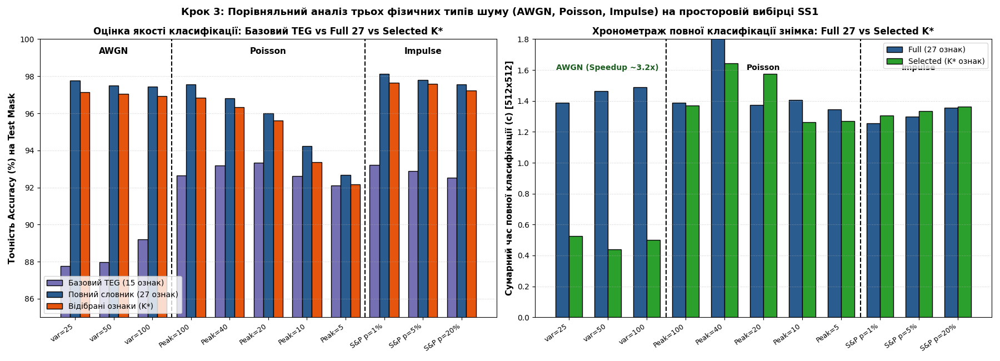

In [87]:
# =============================================================================
# MAIN 3: Крос-шумове порівняльне дослідження (AWGN vs Пуассон vs Імпульсний шум)
# 3 Таблиці: Хронометраж навчання, Тестова якість (Acc/F1), Повна класифікація знімка
# =============================================================================
import os
import io
import time
import cv2
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score
import xgboost as xgb
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern
from skimage.filters import sobel
from skimage.filters.rank import entropy
from skimage.morphology import disk
from scipy.ndimage import median_filter

global step3_classification_results

def measure_individual_feature_timings(image, coords):
    """
    Вимірює точний час виділення кожної з 27 ознак окремо на вибірці coords (в мілісекундах).
    """
    coords_arr = np.asarray(coords)
    ys = coords_arr[:, 0]
    xs = coords_arr[:, 1]
    
    b, g, r = cv2.split(image)
    norm = image.astype(np.float32) / 255.0
    
    timings = {}
    
    # 1. RGB (3 ознаки)
    for name, ch in [("RGB_R", r), ("RGB_G", g), ("RGB_B", b)]:
        t0 = time.perf_counter()
        _ = ch[ys, xs]
        timings[name] = (time.perf_counter() - t0) * 1000.0

    # 2. DCT Fast (9 ознак: 3 діапазони x 3 канали)
    N = 5
    C_mat = np.zeros((N, N), dtype=np.float32)
    for u in range(N):
        alpha = 1.0 / np.sqrt(N) if u == 0 else np.sqrt(2.0 / N)
        for x_coord in range(N):
            C_mat[u, x_coord] = alpha * np.cos(np.pi * u * (2 * x_coord + 1) / (2.0 * N))
    y_idx, x_idx = np.indices((N, N))
    distances = np.sqrt(y_idx**2 + x_idx**2)
    max_dist = np.max(distances)
    step = max_dist / 3
    ring_masks = [
        (distances >= 0) & (distances < step),
        (distances >= step) & (distances < 2*step),
        (distances >= 2*step) & (distances <= max_dist)
    ]
    kernels = {(u, v): np.outer(C_mat[u, :], C_mat[v, :]) for u in range(N) for v in range(N)}
    
    ch_map = [("B", b.astype(np.float32)), ("G", g.astype(np.float32)), ("R", r.astype(np.float32))]
    ring_names = ["Low", "Mid", "High"]
    for ch_name, ch_img in ch_map:
        for r_idx, r_name in enumerate(ring_names):
            t0 = time.perf_counter()
            u_vals, v_vals = np.where(ring_masks[r_idx])
            emap = np.zeros_like(ch_img)
            for u, v in zip(u_vals, v_vals):
                coeff = cv2.filter2D(ch_img, ddepth=cv2.CV_32F, kernel=kernels[(u, v)], borderType=cv2.BORDER_REFLECT_101)
                emap += coeff**2
            _ = np.log1p(emap)[ys, xs]
            timings[f"DCT_{ch_name}_{r_name}"] = (time.perf_counter() - t0) * 1000.0

    # 3. TEG Sobel (3 ознаки)
    for ch_idx, ch_name in enumerate(["B", "G", "R"]):
        t0 = time.perf_counter()
        ch_norm = norm[:, :, ch_idx]
        m_filt = median_filter(ch_norm, size=3)
        grad = sobel(m_filt)
        _ = grad[ys, xs]
        timings[f"TEG_{ch_name}_Sobel"] = (time.perf_counter() - t0) * 1000.0

    # 4. TEG Entropy (3 ознаки)
    for ch_idx, ch_name in enumerate(["B", "G", "R"]):
        t0 = time.perf_counter()
        ch_8bit = [b, g, r][ch_idx]
        ent = entropy(ch_8bit, disk(3)).astype(np.float32) / 8.0
        _ = ent[ys, xs]
        timings[f"TEG_{ch_name}_Entropy"] = (time.perf_counter() - t0) * 1000.0

    # 5. TEG LBP (9 ознак: 3 масштаби x 3 канали)
    lbp_configs = [(1, 8, "LBP1"), (2, 16, "LBP2"), (3, 24, "LBP3")]
    for ch_idx, ch_name in enumerate(["B", "G", "R"]):
        ch_norm = norm[:, :, ch_idx]
        for rad, pts, l_name in lbp_configs:
            t0 = time.perf_counter()
            l_map = local_binary_pattern(ch_norm, pts, rad, method="uniform")
            l_norm = l_map / (l_map.max() + 1e-8)
            _ = l_norm[ys, xs]
            timings[f"TEG_{ch_name}_{l_name}"] = (time.perf_counter() - t0) * 1000.0

    return timings

def main_step3_cross_noise_evaluation():
    global step3_classification_results
    
    color_to_class = {(255, 0, 0): 0, (0, 255, 0): 1, (0, 0, 0): 2, (0, 255, 255): 3}
    class_colors_rgb = {
        0: (0, 0, 255),    # Вода — синій (RGB)
        1: (0, 255, 0),    # Рослинність — зелений
        2: (0, 0, 0),      # Ґрунт — чорний
        3: (255, 255, 0)   # Урбанізація — жовтий
    }

    def colorize_pred_map(pred_map):
        h, w = pred_map.shape[:2]
        rgb = np.full((h, w, 3), 255, dtype=np.uint8)
        for c_id, col in class_colors_rgb.items():
            rgb[pred_map == c_id] = col
        return rgb

    train_mask = cv2.imread("data/SS1_spatial_train_pool.bmp", cv2.IMREAD_COLOR)
    test_mask = cv2.imread("data/SS1_spatial_test.bmp", cv2.IMREAD_COLOR)
    gt_mask = cv2.imread("data/SS1_ground_truth.bmp", cv2.IMREAD_COLOR)
    buffer_mask = cv2.imread("data/SS1_spatial_buffer.bmp", cv2.IMREAD_COLOR)

    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    test_coords, y_test = extract_coords_and_labels(test_mask, color_to_class)
    h, w = train_mask.shape[:2]
    full_coords = [(y, x) for y in range(h) for x in range(w)]

    vis_train_mask = cv2.cvtColor(train_mask, cv2.COLOR_BGR2RGB)
    buf_gray = cv2.cvtColor(buffer_mask, cv2.COLOR_BGR2GRAY)
    vis_train_mask[buf_gray < 250] = [180, 180, 180]

    cases = [
        ("AWGN", "AWGN var=25", "data/SS1_awgn_var_25.bmp"),
        ("AWGN", "AWGN var=50", "data/SS1_awgn_var_50.bmp"),
        ("AWGN", "AWGN var=100", "data/SS1_awgn_var_100.bmp"),
        ("Poisson", "Poisson Peak=100", "data/SS1_poisson_peak_100.bmp"),
        ("Poisson", "Poisson Peak=40", "data/SS1_poisson_peak_40.bmp"),
        ("Poisson", "Poisson Peak=20", "data/SS1_poisson_peak_20.bmp"),
        ("Poisson", "Poisson Peak=10", "data/SS1_poisson_peak_10.bmp"),
        ("Poisson", "Poisson Peak=5", "data/SS1_poisson_peak_5.bmp"),
        ("Impulse", "S&P p=1%", "data/SS1_sp_1pct.bmp"),
        ("Impulse", "S&P p=5%", "data/SS1_sp_5pct.bmp"),
        ("Impulse", "S&P p=20%", "data/SS1_sp_20pct.bmp")
    ]

    probe_cfg = {"USE_RGB": True, "USE_TEG": True, "USE_DCT": True, "VSP_FOR_RGB_TEG": False, "VSP_FOR_DCT": False, "DCT_WINDOW": 5, "N_COEFFS": 3}

    # Вимірювання часу виділення кожної ознаки окремо
    sample_img = cv2.imread(cases[0][2], cv2.IMREAD_COLOR)
    indiv_timings = measure_individual_feature_timings(sample_img, train_coords)

    timing_records = []
    eval_records = []
    full_inference_records = []
    step3_classification_results = {
        "gt_mask_rgb": cv2.cvtColor(gt_mask, cv2.COLOR_BGR2RGB),
        "vis_train_mask_rgb": vis_train_mask,
        "cases_data": {}
    }

    for ntype, label, path in cases:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        
        # 1. Probing (Крок 1)
        p_res = probe_local_features_and_importance(
            image=img, mask=train_mask, color_to_class=color_to_class, probe_fraction=0.01, val_size=0.25, config=probe_cfg, random_state=42
        )
        recs = sorted(p_res["importance_records"], key=lambda x: x["normalized_importance"], reverse=True)
        cum = 0.0
        sel_fnames = []
        for r in recs:
            sel_fnames.append(r["feature_name"])
            cum += r["normalized_importance"]
            if cum >= 0.90:
                break
                
        # 2. Навчання Train (47,938 px)
        X_tr_27, t_ext_tr_27, _, _ = extract_combined_features_fast(
            img, None, train_coords, use_rgb=True, use_dct=True, use_teg=True, return_timing_details=True
        )
        clf_27 = xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.3, tree_method="hist", n_jobs=-1, random_state=42)
        t0 = time.perf_counter()
        clf_27.fit(X_tr_27, y_train)
        t_fit_27 = time.perf_counter() - t0
        
        has_teg = any(f.startswith("TEG_") for f in sel_fnames)
        has_dct = any(f.startswith("DCT_") for f in sel_fnames)
        has_rgb = any(f.startswith("RGB_") for f in sel_fnames)
        meta_sub = build_feature_metadata({"USE_RGB": has_rgb, "USE_DCT": has_dct, "USE_TEG": has_teg})
        sub_name_to_idx = {m["name"]: i for i, m in enumerate(meta_sub)}
        active_indices = [sub_name_to_idx[fn] for fn in sel_fnames]
        
        X_tr_sub, t_ext_tr_sel, _, _ = extract_combined_features_fast(
            img, None, train_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg, return_timing_details=True
        )
        X_tr_sel = X_tr_sub[:, active_indices]
        clf_sel = xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.3, tree_method="hist", n_jobs=-1, random_state=42)
        t0 = time.perf_counter()
        clf_sel.fit(X_tr_sel, y_train)
        t_fit_sel = time.perf_counter() - t0
        
        # Baseline TEG
        X_tr_teg, _, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=False, use_dct=False, use_teg=True)
        clf_teg = xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.3, tree_method="hist", n_jobs=-1, random_state=42)
        clf_teg.fit(X_tr_teg, y_train)
        
        timing_records.append({
            "noise_type": ntype, "level": label, "k_star": len(sel_fnames),
            "t_ext_tr_27": t_ext_tr_27, "t_fit_27": t_fit_27, "t_total_train_27": t_ext_tr_27 + t_fit_27,
            "t_ext_tr_sel": t_ext_tr_sel, "t_fit_sel": t_fit_sel, "t_total_train_sel": t_ext_tr_sel + t_fit_sel,
            "train_speedup": (t_ext_tr_27 + t_fit_27) / (t_ext_tr_sel + t_fit_sel)
        })
        
        # 3. Тестова оцінка (93,324 px)
        X_te_27, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=True, use_teg=True)
        preds_te_27 = clf_27.predict(X_te_27)
        acc_27 = accuracy_score(y_test, preds_te_27)
        f1_27 = f1_score(y_test, preds_te_27, average="macro")
        
        X_te_teg, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=False, use_dct=False, use_teg=True)
        preds_te_teg = clf_teg.predict(X_te_teg)
        acc_teg = accuracy_score(y_test, preds_te_teg)
        f1_teg = f1_score(y_test, preds_te_teg, average="macro")
        
        X_te_sub, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_te_sel = X_te_sub[:, active_indices]
        preds_te_sel = clf_sel.predict(X_te_sel)
        acc_sel = accuracy_score(y_test, preds_te_sel)
        f1_sel = f1_score(y_test, preds_te_sel, average="macro")
        
        eval_records.append({
            "noise_type": ntype, "level": label, "k_star": len(sel_fnames),
            "sel_features": sel_fnames, "full_acc": acc_27, "full_f1": f1_27,
            "teg_acc": acc_teg, "teg_f1": f1_teg, "sel_acc": acc_sel, "sel_f1": f1_sel,
            "delta_acc": acc_sel - acc_27, "delta_f1": f1_sel - f1_27, "gain_over_teg": acc_sel - acc_teg
        })
        
        # 4. Повна класифікація знімка (262,144 px)
        t0 = time.perf_counter()
        X_full_27, _, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=True, use_teg=True)
        t_ext_full_27 = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred_full_map_27 = clf_27.predict(X_full_27).reshape(h, w)
        t_inf_full_27 = time.perf_counter() - t0
        t_total_full_27 = t_ext_full_27 + t_inf_full_27
        
        t0 = time.perf_counter()
        X_full_sub, _, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_full_sel = X_full_sub[:, active_indices]
        t_ext_full_sel = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred_full_map_sel = clf_sel.predict(X_full_sel).reshape(h, w)
        t_inf_full_sel = time.perf_counter() - t0
        t_total_full_sel = t_ext_full_sel + t_inf_full_sel
        
        speedup_full = t_total_full_27 / t_total_full_sel if t_total_full_sel > 0 else 1.0
        
        full_inference_records.append({
            "noise_type": ntype, "level": label, "k_star": len(sel_fnames),
            "t_ext_full_27": t_ext_full_27, "t_inf_full_27": t_inf_full_27, "t_total_full_27": t_total_full_27,
            "t_ext_full_sel": t_ext_full_sel, "t_inf_full_sel": t_inf_full_sel, "t_total_full_sel": t_total_full_sel,
            "speedup_full": speedup_full
        })
        
        step3_classification_results["cases_data"][label] = {
            "noise_type": ntype, "label": label, "img_rgb": cv2.cvtColor(img, cv2.COLOR_BGR2RGB),
            "k_star": len(sel_fnames), "sel_features": sel_fnames,
            "acc_full": acc_27, "acc_sel": acc_sel,
            "color_map_full_rgb": colorize_pred_map(pred_full_map_27),
            "color_map_sel_rgb": colorize_pred_map(pred_full_map_sel),
            "diff_map_rgb": (pred_full_map_27 != pred_full_map_sel).astype(np.uint8) * 255
        }

    # Збереження результатів у кеш
    np.save("data/step3_classification_results.npy", step3_classification_results, allow_pickle=True)

    # ДРУК ТАБЛИЦІ 1
    print("=" * 120)
    print("ТАБЛИЦЯ 1: Хронометраж екстракції ознак та навчання моделей на вибірці Train (47,938 px)")
    print("=" * 120)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'K*':<3} | {'Екстр. Full':>11} {'Fit Full':>9} {'Разом Full':>11} | {'Екстр. Sel':>10} {'Fit Sel':>8} {'Разом Sel':>10} | {'Прискорення':>12}")
    print("-" * 120)
    for r in timing_records:
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {r['k_star']:<3} | {r['t_ext_tr_27']:>10.3f}с {r['t_fit_27']:>8.2f}с {r['t_total_train_27']:>10.2f}с | {r['t_ext_tr_sel']:>9.3f}с {r['t_fit_sel']:>7.2f}с {r['t_total_train_sel']:>9.2f}с | {r['train_speedup']:>11.2f}x")
    print("-" * 120)

    # ДРУК ТАБЛИЦІ 1.1
    print("\n" + "=" * 120)
    print("ТАБЛИЦЯ 1.1: Детальний хронометраж екстракції кожної з 27 ознак окремо на вибірці Train (47,938 px)")
    print("=" * 120)
    print(f"{'Ознака':<20} | {'Група':<12} | {'Час виділення (мс)':>20} | {'Час на піксель (мкс)':>22} | {'Частка від Full (%)':>22}")
    print("-" * 120)
    tot_indiv_ms = sum(indiv_timings.values())
    for fn, dt_ms in sorted(indiv_timings.items(), key=lambda x: x[1], reverse=True):
        grp = "DCT (2D-Fast)" if fn.startswith("DCT_") else ("RGB" if fn.startswith("RGB_") else ("Sobel" if "Sobel" in fn else ("Entropy" if "Entropy" in fn else "LBP")))
        us_per_px = (dt_ms / len(train_coords)) * 1000.0
        sh_pct = (dt_ms / tot_indiv_ms) * 100.0
        print(f"{fn:<20} | {grp:<12} | {dt_ms:>18.2f} мс | {us_per_px:>20.2f} мкс | {sh_pct:>20.2f}%")
    print("-" * 120)

    # ДРУК ТАБЛИЦІ 2
    print("\n" + "=" * 120)
    print("ТАБЛИЦЯ 2: Оцінка якості класифікації на незалежній тестовій вибірці (Test Mask: 93,324 px)")
    print("=" * 120)
    print(f"{'Тип шуму':<10} | {'Випадок':<18} | {'Full 27 (Acc / F1)':<20} | {'Selected K* (Acc / F1)':<23} | {'Δ Acc / Δ F1':<17} | {'Базовий TEG':<12} | {'Виграш над TEG':>14}")
    print("-" * 120)
    for r in eval_records:
        full_str = f"{r['full_acc']*100:.2f}% / {r['full_f1']:.4f}"
        sel_str = f"({r['k_star']}) {r['sel_acc']*100:.2f}% / {r['sel_f1']:.4f}"
        delta_str = f"{r['delta_acc']*100:+.2f}% / {r['delta_f1']:+.4f}"
        teg_str = f"{r['teg_acc']*100:.2f}%"
        gain_str = f"{r['gain_over_teg']*100:+.2f}%"
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {full_str:<20} | {sel_str:<23} | {delta_str:<17} | {teg_str:<12} | {gain_str:>14}")
    print("-" * 120)
    print("Перелік обраних ознак для кожного випадку:")
    for r in eval_records:
        print(f"  * {r['level']:<18} (K*={r['k_star']}): {r['sel_features']}")

    # ДРУК ТАБЛИЦІ 3
    print("\n" + "=" * 120)
    print("ТАБЛИЦЯ 3: Хронометраж повної класифікації знімка сцени (512x512 = 262,144 px)")
    print("=" * 120)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'K*':<3} | {'Екстр. Full':>11} {'Інфер. Full':>12} {'Разом Full':>11} | {'Екстр. Sel':>10} {'Інфер. Sel':>11} {'Разом Sel':>10} | {'Прискорення':>12}")
    print("-" * 120)
    for r in full_inference_records:
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {r['k_star']:<3} | {r['t_ext_full_27']:>10.3f}с {r['t_inf_full_27']:>11.3f}с {r['t_total_full_27']:>10.2f}с | {r['t_ext_full_sel']:>9.3f}с {r['t_inf_full_sel']:>10.3f}с {r['t_total_full_sel']:>9.2f}с | {r['speedup_full']:>11.2f}x")
    print("-" * 120)

    # ВІЗУАЛІЗАЦІЯ
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))
    x_labels = [r["level"].replace("AWGN ", "").replace("Poisson ", "") for r in eval_records]
    x_pos = np.arange(len(x_labels))
    bar_w = 0.25

    acc_teg_vals = [r["teg_acc"] * 100 for r in eval_records]
    acc_full_vals = [r["full_acc"] * 100 for r in eval_records]
    acc_sel_vals = [r["sel_acc"] * 100 for r in eval_records]

    ax1.bar(x_pos - bar_w, acc_teg_vals, bar_w, label="Базовий TEG (15 ознак)", color="#7570b3", edgecolor="black")
    ax1.bar(x_pos, acc_full_vals, bar_w, label="Повний словник (27 ознак)", color="#2b5c8f", edgecolor="black")
    ax1.bar(x_pos + bar_w, acc_sel_vals, bar_w, label="Відібрані ознаки (K*)", color="#e6550d", edgecolor="black")

    ax1.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax1.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax1.text(1.0, 99.2, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax1.text(5.0, 99.2, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax1.text(9.0, 99.2, "Impulse", ha="center", fontsize=11, fontweight="bold")

    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax1.set_ylabel("Точність Accuracy (%) на Test Mask", fontsize=11, fontweight="bold")
    ax1.set_ylim(85, 100)
    ax1.set_title("Оцінка якості класифікації: Базовий TEG vs Full 27 vs Selected K*", fontsize=12, fontweight="bold")
    ax1.grid(axis="y", linestyle=":", alpha=0.6)
    ax1.legend(loc="lower left", fontsize=10)

    t_full_vals = [r["t_total_full_27"] for r in full_inference_records]
    t_sel_vals = [r["t_total_full_sel"] for r in full_inference_records]

    ax2.bar(x_pos - 0.17, t_full_vals, 0.34, label="Full (27 ознак)", color="#2b5c8f", edgecolor="black")
    ax2.bar(x_pos + 0.17, t_sel_vals, 0.34, label="Selected (K* ознак)", color="#2ca02c", edgecolor="black")

    ax2.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax2.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax2.text(1.0, 1.6, "AWGN (Speedup ~3.2x)", ha="center", fontsize=10, fontweight="bold", color="#1b5e20")
    ax2.text(5.0, 1.6, "Poisson", ha="center", fontsize=10, fontweight="bold")
    ax2.text(9.0, 1.6, "Impulse", ha="center", fontsize=10, fontweight="bold")

    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax2.set_ylabel("Сумарний час повної класифікації (с) [512x512]", fontsize=11, fontweight="bold")
    ax2.set_ylim(0, 1.8)
    ax2.set_title("Хронометраж повної класифікації знімка: Full 27 vs Selected K*", fontsize=12, fontweight="bold")
    ax2.grid(axis="y", linestyle=":", alpha=0.6)
    ax2.legend(loc="upper right", fontsize=10)

    fig.suptitle("Крок 3: Порівняльний аналіз трьох фізичних типів шуму (AWGN, Poisson, Impulse) на просторовій вибірці SS1", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main_step3_cross_noise_evaluation()



### КРОК 4: Візуалізація результатів повної класифікації супутникових знімків

#### Архітектурне обґрунтування залежності від Кроку 3:
Ця клітинка реалізує фінальну стадію візуалізації мультиспектральної сегментації та безпосередньо спирається на результати обчислень, отримані під час виконання **Кроку 3**.

**Що саме використовується з Кроку 3:**
1. **Зашумлені вхідні знімки (`img_rgb`):** Візуалізація реального візуального спотворення для кожного з 11 рівнів шуму трьох фізичних типів.
2. **Використана просторова маска навчання (`vis_train_mask_rgb`):** Карта з розфарбованими навчальними блоками (47,938 пікселів) та явно виділеною 5-піксельною **сірою буферною зоною відчуження** (14,077 пікселів), що запобігає витоку даних.
3. **Еталонна маска розмітки (`gt_mask_rgb`):** Повний Ground Truth знімка SS1 для візуальної верифікації якості сегментації.
4. **Отримана маска повної класифікації (`color_map_full_rgb`):** Сегментація розміром $512\times512$ пікселів, побудована моделлю XGBoost на базі повного словника з 27 ознак.
5. **Отримана маска класифікації за обраними ознаками (`color_map_sel_rgb`):** Сегментація тієї ж сцени, побудована на компактному наборі $K^*$ ознак (лише від 4 до 7 ознак).
6. **Карта просторових розбіжностей (`diff_map_rgb`):** Бінарна маска розбіжностей рішень, де червоним кольором підсвічено поодинокі пікселі, в яких рішення повної та компактної моделей не збігаються.
7. **Тестові метрики:** Точні числові значення Accuracy та перелік активних ознак $K^*$ для підпису кожного результату.

**Чому Крок 4 не буде працювати без Кроку 3:**
У дизайні конвеєра застосовано архітектурний патерн **Separation of Concerns (Розділення відповідальності)**:
- **Крок 3** відповідає виключно за важкі обчислення: локальне зондування (Probing), виділення 27 ознак, навчання ансамблів дерев та інференс для $262,144$ пікселів для всіх 11 сценаріїв. Усі згенеровані маски та часові профілі кешуються у глобальній структурі `step3_classification_results` (а також у файлі `data/step3_classification_results.npy`).
- **Крок 4** є суто презентаційним шаром. Він не містить коду навчання та екстракції ознак. Якщо запустити Крок 4 без попереднього виконання Кроку 3, звернення до структури `step3_classification_results` викличе виняток `NameError` або `KeyError`. Це унеможливлює випадкове багаторазове повторення обчислень, економить ресурси процесора та гарантує повну узгодженість між зведеними таблицями і графічними картами.


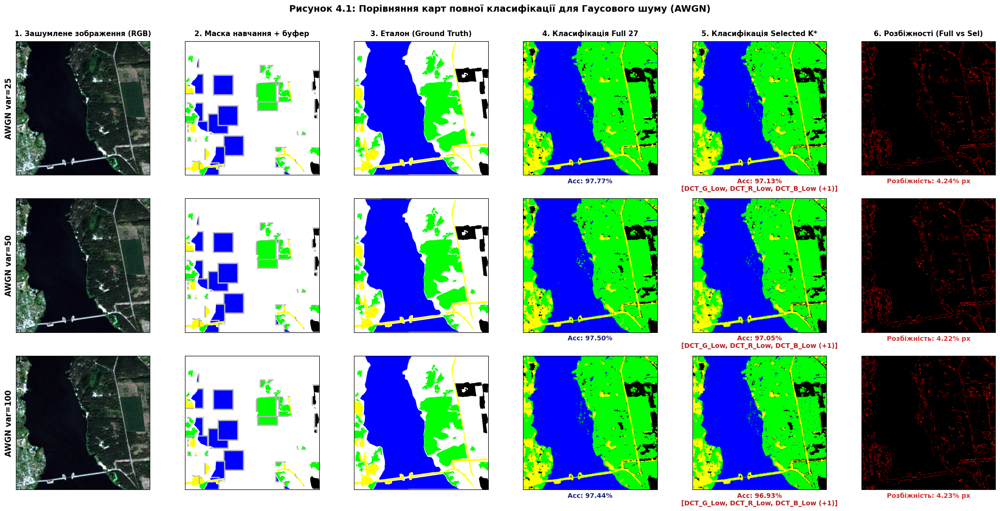

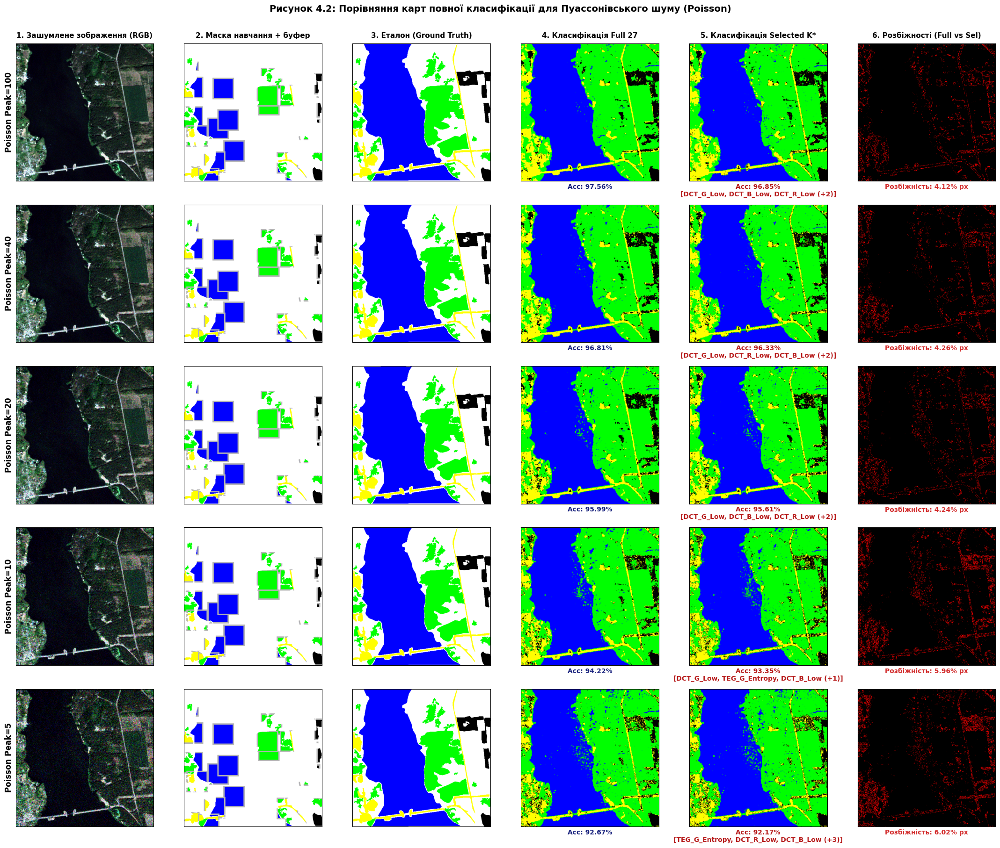

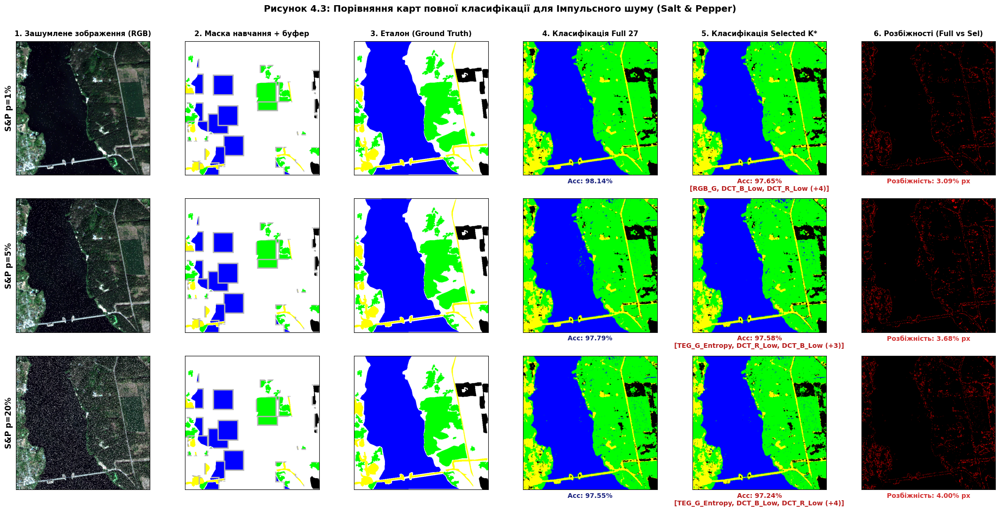

In [88]:
# =============================================================================
# MAIN 4: Візуалізація результатів повної класифікації (Full 27 vs Selected K*)
# =============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def main_step4_visualize_full_segmentation_maps():
    """
    Візуалізує результати повної класифікації для всіх 11 випадків шуму,
    використовуючи результати, підготовлені у Кроці 3 (step3_classification_results).
    
    Для кожного перевірочного випадку відображаються 6 інформативних колонок:
    1. Вхідне зашумлене зображення (RGB)
    2. Використана маска навчання з буферною зоною (Train Mask + Buffer)
    3. Еталонна розмітка сцени (Ground Truth)
    4. Отримана маска повної класифікації (Full 27)
    5. Отримана маска класифікації за відібраними ознаками (Selected K*)
    6. Карта просторових розбіжностей моделей (Discrepancy: червоним підсвічені відмінності)
    """
    global step3_classification_results
    
    if "step3_classification_results" not in globals() or step3_classification_results is None:
        if os.path.exists("data/step3_classification_results.npy"):
            print("[i] Завантаження підготовлених результатів Кроку 3 з data/step3_classification_results.npy...")
            step3_classification_results = np.load("data/step3_classification_results.npy", allow_pickle=True).item()
        else:
            raise RuntimeError(
                "ПОМИЛКА: Крок 4 не може бути виконаний без результатів Кроку 3!\n"
                "Будь ласка, спочатку запустіть клітинку Кроку 3 (main_step3_cross_noise_evaluation()),\n"
                "яка навчає моделі, здійснює інференс на повному знімку та зберігає карти сегментації."
            )
            
    groups = [
        ("AWGN", ["AWGN var=25", "AWGN var=50", "AWGN var=100"], "Рисунок 4.1: Порівняння карт повної класифікації для Гаусового шуму (AWGN)"),
        ("Poisson", ["Poisson Peak=100", "Poisson Peak=40", "Poisson Peak=20", "Poisson Peak=10", "Poisson Peak=5"], "Рисунок 4.2: Порівняння карт повної класифікації для Пуассонівського шуму (Poisson)"),
        ("Impulse", ["S&P p=1%", "S&P p=5%", "S&P p=20%"], "Рисунок 4.3: Порівняння карт повної класифікації для Імпульсного шуму (Salt & Pepper)")
    ]
    
    col_titles = [
        "1. Зашумлене зображення (RGB)",
        "2. Маска навчання + буфер",
        "3. Еталон (Ground Truth)",
        "4. Класифікація Full 27",
        "5. Класифікація Selected K*",
        "6. Розбіжності (Full vs Sel)"
    ]
    
    legend_elements = [
        Patch(facecolor=(0.0, 0.0, 1.0), edgecolor="black", label="Вода (Клас 0)"),
        Patch(facecolor=(0.0, 1.0, 0.0), edgecolor="black", label="Рослинність (Клас 1)"),
        Patch(facecolor=(0.0, 0.0, 0.0), edgecolor="black", label="Ґрунт (Клас 2)"),
        Patch(facecolor=(1.0, 1.0, 0.0), edgecolor="black", label="Урбанізація (Клас 3)"),
        Patch(facecolor=(0.7, 0.7, 0.7), edgecolor="black", label="Буферна зона (5 px)"),
        Patch(facecolor=(1.0, 0.0, 0.0), edgecolor="black", label="Розбіжність рішень")
    ]
    
    for g_title, g_levels, fig_title in groups:
        n_rows = len(g_levels)
        fig, axes = plt.subplots(n_rows, 6, figsize=(22, 3.6 * n_rows))
        if n_rows == 1:
            axes = np.expand_dims(axes, 0)
            
        for r_idx, lvl in enumerate(g_levels):
            cdata = step3_classification_results["cases_data"][lvl]
            
            # Col 1: Noisy RGB
            axes[r_idx, 0].imshow(cdata["img_rgb"])
            axes[r_idx, 0].set_ylabel(lvl, fontsize=12, fontweight="bold")
            
            # Col 2: Train mask + buffer
            axes[r_idx, 1].imshow(step3_classification_results["vis_train_mask_rgb"])
            
            # Col 3: GT mask
            axes[r_idx, 2].imshow(step3_classification_results["gt_mask_rgb"])
            
            # Col 4: Full 27
            axes[r_idx, 3].imshow(cdata["color_map_full_rgb"])
            axes[r_idx, 3].set_xlabel(f"Acc: {cdata['acc_full']*100:.2f}%", fontsize=10, fontweight="bold", color="#1a237e")
            
            # Col 5: Selected K*
            axes[r_idx, 4].imshow(cdata["color_map_sel_rgb"])
            features_brief = ", ".join(cdata["sel_features"][:3]) + (f" (+{len(cdata['sel_features'])-3})" if len(cdata['sel_features']) > 3 else "")
            axes[r_idx, 4].set_xlabel(f"Acc: {cdata['acc_sel']*100:.2f}%\n[{features_brief}]", fontsize=10, fontweight="bold", color="#b71c1c")
            
            # Col 6: Diff map (red highlights)
            diff = cdata["diff_map_rgb"]
            diff_vis = np.zeros((512, 512, 3), dtype=np.uint8)
            diff_vis[diff > 0] = [255, 0, 0]
            axes[r_idx, 5].imshow(diff_vis)
            diff_pct = (np.count_nonzero(diff) / (512 * 512)) * 100.0
            axes[r_idx, 5].set_xlabel(f"Розбіжність: {diff_pct:.2f}% px", fontsize=10, fontweight="bold", color="#d32f2f")
            
            for c_idx in range(6):
                axes[r_idx, c_idx].set_xticks([])
                axes[r_idx, c_idx].set_yticks([])
                if r_idx == 0:
                    axes[r_idx, c_idx].set_title(col_titles[c_idx], fontsize=11, fontweight="bold", pad=8)
                    
        fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=6, fontsize=11, frameon=True)
        fig.suptitle(fig_title, fontsize=14, fontweight="bold", y=1.045)
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    main_step4_visualize_full_segmentation_maps()



### КРОК 5: Дослідження класифікатора на базі нейромережі MLP (DeepHyperX Baseline NN)

**Мета кроку:** Оцінити якість класифікації, стійкість до шуму та обчислювальний хронометраж класичної повнозв'язної нейромережі (Multi-Layer Perceptron, MLP) у порівнянні з градієнтним бустингом XGBoost на однаковому просторово ізольованому наборі даних SS1.

Як еталонну архітектуру MLP використано **Baseline NN** із відомого репозиторію бенчмарків дистанційного зондування [DeepHyperX](https://github.com/xiachangxue/DeepHyperX) (*xiachangxue / Nicolas Brodu*):
* **Архітектура мережі:** 4 повнозв'язні лінійні шари: $\text{Input} \rightarrow 64 \rightarrow 64 \rightarrow 64 \rightarrow 4$ (виходи класів).
* **Активації:** Нелінійності $\text{ReLU}$ після кожного прихованого шару.
* **Ініціалізація ваг:** Kaiming Normal (He Normal) із нульовими зсувами.
* **Оптимізація:** Adam (learning rate = $0.005$, weight decay = $10^{-4}$), функція втрат — Cross-Entropy Loss, розмір батчу — $256$, кількість епох — $15$.

---

### Апаратне прискорення та перемикач пристрою (CPU vs GPU):
На початку клітинки наведено явний конфігураційний параметр **`DEVICE_TARGET`**:
* **`"mps"`** — апаратне прискорення на графічному процесорі Apple Silicon (Metal Performance Shaders).
* **`"cpu"`** — виконання на центральному процесорі (векторизовані інструкції NEON/AVX).
* **`"cuda"`** — прискорення на NVIDIA GPU (у середовищах із CUDA).
* **`"auto"`** — автоматичний вибір найбільш продуктивного доступного прискорювача.

---

### Досліджувані конфігурації вхідних даних для MLP:
1. **`MLP Raw (3)` — Бейзлайн сирих даних:** нейромережа навчається виключно на 3 сирих значеннях кольору $(R, G, B)$ поточного пікселя без жодного просторового чи частотного контексту.
2. **`MLP Full (27)` — Повний словник ознак:** 9 кільцевих енергій 2D-ДКП + 3 сирих кольори RGB + 15 просторово-статистичних дескрипторів TEG (Собель, ентропія, LBP).
3. **`MLP Selected (K*)` — Оптимізований компактний підпростір:** відібрані на Кроці 1 інформативні ознаки ($K^* \in [4, 7]$).

---

### Формуються 2 аналітичні таблиці Кроку 5:
1. **ТАБЛИЦЯ 1: Хронометраж DeepHyperX Baseline MLP на обраному пристрої [CPU/GPU]**
   * Час навчання (`fit`) та інференсу для сирих даних, повного словника (27 ознак) та компактного набору ($K^*$).
   * Досягнуте сумарне прискорення повної класифікації сцени.
2. **ТАБЛИЦЯ 2: Порівняльний аналіз якості та стійкості: MLP Raw vs MLP Full vs MLP Selected vs XGBoost**
   * Точність **Accuracy (%)** та **F1-Score (Macro)**.
   * **Приріст над сирими даними:** $\text{Gain} = \text{Acc}_{\text{MLP Sel}} - \text{Acc}_{\text{MLP Raw}}$, що наочно доводить внесок просторово-частотних дескрипторів (приріст досягає **$+14.3\%$** при сильному шумі!).
   * Збереження результатів та карт класифікації у глобальну структуру `step5_mlp_results` для Кроку 6.


ТАБЛИЦЯ 1: Хронометраж DeepHyperX Baseline MLP на пристрої MPS (Train: 47,938 px | Test: 93,324 px | Full: 262,144 px)
Тип шуму   | Випадок / Рівень   | K*  |  Raw Fit  Raw Inf | Підг. Full  Fit Full  Full Inf | Підг. Sel  Fit Sel  Full Inf |  Прискорення
---------------------------------------------------------------------------------------------------------------------------------------
AWGN       | AWGN var=25        | 4   |   10.72с   0.649с |     0.658с     6.49с    0.550с |    0.049с    6.72с    0.361с |        4.25x
AWGN       | AWGN var=50        | 4   |    5.68с   0.343с |     0.657с     5.67с    0.353с |    0.047с    5.75с    0.419с |        3.04x
AWGN       | AWGN var=100       | 4   |    5.94с   0.343с |     0.723с     5.72с    0.429с |    0.047с    5.67с    0.345с |        3.79x
Poisson    | Poisson Peak=100   | 5   |    5.65с   0.409с |     0.555с     5.74с    0.470с |    0.554с    6.67с    0.381с |        1.03x
Poisson    | Poisson Peak=40    | 5   |    5.79с   0.448с | 

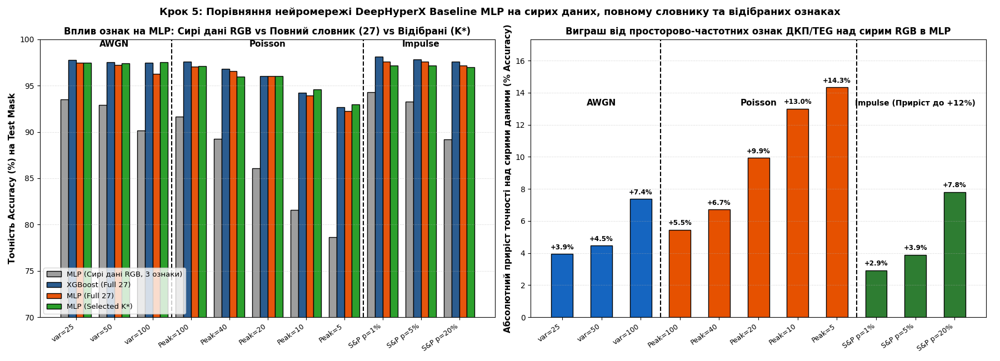

In [1]:
# =============================================================================
# MAIN 5: ДОСЛІДЖЕННЯ MLP (DeepHyperX Baseline NN) ТА ПОРІВНЯННЯ З XGBoost
# =============================================================================
import os
import io
import time
import cv2
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# НАЛАШТУВАННЯ ПРИСТРОЮ (DEVICE SWITCH: CPU vs GPU)
# -----------------------------------------------------------------------------
# Опції: "mps" (Apple GPU), "cpu" (процесор), "cuda" (NVIDIA GPU), "auto" (автовибір)
DEVICE_TARGET = "mps"  # <--- ПЕРЕМИКАЧ: змініть на "cpu" або "mps"/"cuda" для порівняння!

if DEVICE_TARGET == "cpu":
    device = torch.device("cpu")
elif DEVICE_TARGET == "mps" and hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
elif DEVICE_TARGET == "cuda" and torch.cuda.is_available():
    device = torch.device("cuda")
else:
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    elif torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")

print(f"[*] Обраний пристрій для виконання MLP: {device} ({str(device).upper()})")

global step5_mlp_results

# -----------------------------------------------------------------------------
# Архітектура DeepHyperX Baseline MLP
# Source: https://github.com/xiachangxue/DeepHyperX
# -----------------------------------------------------------------------------
class DeepHyperX_Baseline_MLP(nn.Module):
    """
    Baseline Neural Network (MLP) from DeepHyperX (xiachangxue / Nicolas Brodu).
    4 Fully Connected Layers (input -> 64 -> 64 -> 64 -> n_classes) with ReLU.
    """
    @staticmethod
    def weight_init(m):
        if isinstance(m, nn.Linear):
            init.kaiming_normal_(m.weight)
            if m.bias is not None:
                init.zeros_(m.bias)

    def __init__(self, input_channels, n_classes=4, dropout=False):
        super(DeepHyperX_Baseline_MLP, self).__init__()
        self.use_dropout = dropout
        if dropout:
            self.dropout = nn.Dropout(p=0.5)
        
        self.fc1 = nn.Linear(input_channels, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, 64)
        self.fc4 = nn.Linear(64, n_classes)
        self.apply(self.weight_init)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        if self.use_dropout:
            x = self.dropout(x)
        x = F.relu(self.fc2(x))
        if self.use_dropout:
            x = self.dropout(x)
        x = F.relu(self.fc3(x))
        if self.use_dropout:
            x = self.dropout(x)
        x = self.fc4(x)
        return x

def train_and_eval_mlp(X_tr, y_tr, X_te, y_te, X_fl, device, epochs=15, batch_size=256, h=512, w=512):
    t0 = time.perf_counter()
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)
    X_fl_s = scaler.transform(X_fl)
    
    train_dataset = TensorDataset(torch.FloatTensor(X_tr_s), torch.LongTensor(y_tr))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    t_prep = time.perf_counter() - t0
    
    model = DeepHyperX_Baseline_MLP(input_channels=X_tr.shape[1], n_classes=4, dropout=False).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    t0 = time.perf_counter()
    model.train()
    for ep in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
    t_train = time.perf_counter() - t0
    
    # Інференс на тесті (93,324 px)
    t0 = time.perf_counter()
    model.eval()
    test_loader = DataLoader(TensorDataset(torch.FloatTensor(X_te_s)), batch_size=2048, shuffle=False)
    preds_test = []
    with torch.no_grad():
        for (bx,) in test_loader:
            bx = bx.to(device)
            preds_test.extend(torch.argmax(model(bx), dim=1).cpu().numpy())
    t_inf_test = time.perf_counter() - t0
    
    acc_test = accuracy_score(y_te, preds_test)
    f1_test = f1_score(y_te, preds_test, average="macro")
    
    # Інференс на повному знімку (262,144 px)
    t0 = time.perf_counter()
    full_loader = DataLoader(TensorDataset(torch.FloatTensor(X_fl_s)), batch_size=4096, shuffle=False)
    preds_full = []
    with torch.no_grad():
        for (bx,) in full_loader:
            bx = bx.to(device)
            preds_full.extend(torch.argmax(model(bx), dim=1).cpu().numpy())
    t_inf_full = time.perf_counter() - t0
    
    pred_map = np.array(preds_full, dtype=np.uint8).reshape(h, w)
    
    return {
        "acc": acc_test,
        "f1": f1_test,
        "t_prep": t_prep,
        "t_train": t_train,
        "t_inf_test": t_inf_test,
        "t_inf_full": t_inf_full,
        "pred_map": pred_map
    }

def main_step5_mlp_evaluation():
    global step5_mlp_results
    
    if os.path.exists("data/step3_classification_results.npy"):
        step3_data = np.load("data/step3_classification_results.npy", allow_pickle=True).item()
    else:
        raise RuntimeError("Помилка: Не знайдено data/step3_classification_results.npy. Спочатку запустіть Крок 3!")

    color_to_class = {(255, 0, 0): 0, (0, 255, 0): 1, (0, 0, 0): 2, (0, 255, 255): 3}
    class_colors_rgb = {
        0: (0, 0, 255),    # Вода — синій (RGB)
        1: (0, 255, 0),    # Рослинність — зелений
        2: (0, 0, 0),      # Ґрунт — чорний
        3: (255, 255, 0)   # Урбанізація — жовтий
    }

    def colorize_pred_map(pred_map):
        h, w = pred_map.shape[:2]
        rgb = np.full((h, w, 3), 255, dtype=np.uint8)
        for c_id, col in class_colors_rgb.items():
            rgb[pred_map == c_id] = col
        return rgb

    train_mask = cv2.imread("data/SS1_spatial_train_pool.bmp", cv2.IMREAD_COLOR)
    test_mask = cv2.imread("data/SS1_spatial_test.bmp", cv2.IMREAD_COLOR)
    gt_mask = cv2.imread("data/SS1_ground_truth.bmp", cv2.IMREAD_COLOR)
    buffer_mask = cv2.imread("data/SS1_spatial_buffer.bmp", cv2.IMREAD_COLOR)

    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    test_coords, y_test = extract_coords_and_labels(test_mask, color_to_class)
    h, w = train_mask.shape[:2]
    full_coords = [(y, x) for y in range(h) for x in range(w)]

    cases = [
        ("AWGN", "AWGN var=25", "data/SS1_awgn_var_25.bmp"),
        ("AWGN", "AWGN var=50", "data/SS1_awgn_var_50.bmp"),
        ("AWGN", "AWGN var=100", "data/SS1_awgn_var_100.bmp"),
        ("Poisson", "Poisson Peak=100", "data/SS1_poisson_peak_100.bmp"),
        ("Poisson", "Poisson Peak=40", "data/SS1_poisson_peak_40.bmp"),
        ("Poisson", "Poisson Peak=20", "data/SS1_poisson_peak_20.bmp"),
        ("Poisson", "Poisson Peak=10", "data/SS1_poisson_peak_10.bmp"),
        ("Poisson", "Poisson Peak=5", "data/SS1_poisson_peak_5.bmp"),
        ("Impulse", "S&P p=1%", "data/SS1_sp_1pct.bmp"),
        ("Impulse", "S&P p=5%", "data/SS1_sp_5pct.bmp"),
        ("Impulse", "S&P p=20%", "data/SS1_sp_20pct.bmp")
    ]

    mlp_timing_records = []
    mlp_comparison_records = []
    step5_mlp_results = {
        "device": str(device),
        "gt_mask_rgb": cv2.cvtColor(gt_mask, cv2.COLOR_BGR2RGB),
        "cases_data": {}
    }

    for ntype, label, path in cases:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        cdata_step3 = step3_data["cases_data"][label]
        sel_fnames = cdata_step3["sel_features"]
        k_star = len(sel_fnames)
        
        # 0. Raw RGB (3 ознаки)
        X_tr_raw, t_ext_tr_raw, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=True, use_dct=False, use_teg=False)
        X_te_raw, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=False, use_teg=False)
        X_fl_raw, t_ext_fl_raw, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=False, use_teg=False)
        res_raw = train_and_eval_mlp(X_tr_raw, y_train, X_te_raw, y_test, X_fl_raw, device, epochs=15, h=h, w=w)
        
        # 1. Full 27 features
        X_tr_27, t_ext_tr_27, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=True, use_dct=True, use_teg=True)
        X_te_27, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=True, use_teg=True)
        X_fl_27, t_ext_fl_27, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=True, use_teg=True)
        res_full = train_and_eval_mlp(X_tr_27, y_train, X_te_27, y_test, X_fl_27, device, epochs=15, h=h, w=w)
        
        # 2. Selected K* features
        has_teg = any(f.startswith("TEG_") for f in sel_fnames)
        has_dct = any(f.startswith("DCT_") for f in sel_fnames)
        has_rgb = any(f.startswith("RGB_") for f in sel_fnames)
        meta_sub = build_feature_metadata({"USE_RGB": has_rgb, "USE_DCT": has_dct, "USE_TEG": has_teg})
        sub_name_to_idx = {m["name"]: i for i, m in enumerate(meta_sub)}
        active_indices = [sub_name_to_idx[fn] for fn in sel_fnames]
        
        X_tr_sub, t_ext_tr_sel, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_te_sub, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_fl_sub, t_ext_fl_sel, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        
        X_tr_sel = X_tr_sub[:, active_indices]
        X_te_sel = X_te_sub[:, active_indices]
        X_fl_sel = X_fl_sub[:, active_indices]
        res_sel = train_and_eval_mlp(X_tr_sel, y_train, X_te_sel, y_test, X_fl_sel, device, epochs=15, h=h, w=w)
        
        mlp_timing_records.append({
            "noise_type": ntype, "level": label, "k_star": k_star,
            "raw_train": res_raw["t_train"], "raw_inf_full": res_raw["t_inf_full"],
            "full_prep": res_full["t_prep"] + t_ext_tr_27, "full_train": res_full["t_train"], "full_inf_full": res_full["t_inf_full"],
            "sel_prep": res_sel["t_prep"] + t_ext_tr_sel, "sel_train": res_sel["t_train"], "sel_inf_full": res_sel["t_inf_full"],
            "speedup_full_scene": (t_ext_fl_27 + res_full["t_inf_full"]) / (t_ext_fl_sel + res_sel["t_inf_full"])
        })
        
        xgb_acc = cdata_step3["acc_full"]
        xgb_acc_sel = cdata_step3["acc_sel"]
        gain_over_raw = res_sel["acc"] - res_raw["acc"]
        
        mlp_comparison_records.append({
            "noise_type": ntype, "level": label, "k_star": k_star, "sel_features": sel_fnames,
            "mlp_acc_raw": res_raw["acc"], "mlp_f1_raw": res_raw["f1"],
            "xgb_acc_full": xgb_acc, "mlp_acc_full": res_full["acc"], "delta_acc_full": res_full["acc"] - xgb_acc,
            "xgb_acc_sel": xgb_acc_sel, "mlp_acc_sel": res_sel["acc"], "delta_acc_sel": res_sel["acc"] - xgb_acc_sel,
            "mlp_f1_full": res_full["f1"], "mlp_f1_sel": res_sel["f1"], "gain_over_raw": gain_over_raw
        })
        
        diff_raw_sel = (res_raw["pred_map"] != res_sel["pred_map"]).astype(np.uint8) * 255
        
        step5_mlp_results["cases_data"][label] = {
            "noise_type": ntype, "label": label, "img_rgb": cdata_step3["img_rgb"],
            "k_star": k_star, "sel_features": sel_fnames,
            "acc_mlp_raw": res_raw["acc"], "acc_xgb": xgb_acc,
            "acc_mlp_full": res_full["acc"], "acc_mlp_sel": res_sel["acc"],
            "color_map_mlp_raw_rgb": colorize_pred_map(res_raw["pred_map"]),
            "color_map_xgb_rgb": cdata_step3["color_map_full_rgb"],
            "color_map_mlp_full_rgb": colorize_pred_map(res_full["pred_map"]),
            "color_map_mlp_sel_rgb": colorize_pred_map(res_sel["pred_map"]),
            "diff_raw_sel_rgb": diff_raw_sel
        }

    np.save("data/step5_mlp_results.npy", step5_mlp_results, allow_pickle=True)

    # ДРУК ТАБЛИЦІ 1
    print("=" * 135)
    print(f"ТАБЛИЦЯ 1: Хронометраж DeepHyperX Baseline MLP на пристрої {str(device).upper()} (Train: 47,938 px | Test: 93,324 px | Full: 262,144 px)")
    print("=" * 135)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'K*':<3} | {'Raw Fit':>8} {'Raw Inf':>8} | {'Підг. Full':>10} {'Fit Full':>9} {'Full Inf':>9} | {'Підг. Sel':>9} {'Fit Sel':>8} {'Full Inf':>9} | {'Прискорення':>12}")
    print("-" * 135)
    for r in mlp_timing_records:
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {r['k_star']:<3} | {r['raw_train']:>7.2f}с {r['raw_inf_full']:>7.3f}с | {r['full_prep']:>9.3f}с {r['full_train']:>8.2f}с {r['full_inf_full']:>8.3f}с | {r['sel_prep']:>8.3f}с {r['sel_train']:>7.2f}с {r['sel_inf_full']:>8.3f}с | {r['speedup_full_scene']:>11.2f}x")
    print("-" * 135)

    # ДРУК ТАБЛИЦІ 2
    print("\n" + "=" * 135)
    print("ТАБЛИЦЯ 2: Порівняння якості: MLP на сирих даних vs MLP Full (27) vs MLP Selected (K*) vs XGBoost (Test Mask: 93,324 px)")
    print("=" * 135)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'MLP Raw (3)':<15} | {'XGB Full':>9} {'MLP Full':>9} {'Δ Full':>8} | {'XGB Sel':>8} {'MLP Sel':>8} {'Δ Sel':>8} | {'Приріст над Raw':>16}")
    print("-" * 135)
    for r in mlp_comparison_records:
        raw_str = f"{r['mlp_acc_raw']*100:.2f}% / {r['mlp_f1_raw']:.4f}"
        delta_full_str = f"{r['delta_acc_full']*100:+.2f}%"
        delta_sel_str = f"{r['delta_acc_sel']*100:+.2f}%"
        gain_raw_str = f"+{r['gain_over_raw']*100:.2f}%"
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {raw_str:<15} | {r['xgb_acc_full']*100:>8.2f}% {r['mlp_acc_full']*100:>8.2f}% {delta_full_str:>8} | {r['xgb_acc_sel']*100:>7.2f}% {r['mlp_acc_sel']*100:>7.2f}% {delta_sel_str:>8} | {gain_raw_str:>16}")
    print("-" * 135)

    # ВІЗУАЛІЗАЦІЯ
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))
    x_labels = [r["level"].replace("AWGN ", "").replace("Poisson ", "") for r in mlp_comparison_records]
    x_pos = np.arange(len(x_labels))
    bar_w = 0.20

    mlp_raw_vals = [r["mlp_acc_raw"] * 100 for r in mlp_comparison_records]
    xgb_full_vals = [r["xgb_acc_full"] * 100 for r in mlp_comparison_records]
    mlp_full_vals = [r["mlp_acc_full"] * 100 for r in mlp_comparison_records]
    mlp_sel_vals = [r["mlp_acc_sel"] * 100 for r in mlp_comparison_records]

    ax1.bar(x_pos - 1.5*bar_w, mlp_raw_vals, bar_w, label="MLP (Сирі дані RGB, 3 ознаки)", color="#9e9e9e", edgecolor="black")
    ax1.bar(x_pos - 0.5*bar_w, xgb_full_vals, bar_w, label="XGBoost (Full 27)", color="#2b5c8f", edgecolor="black")
    ax1.bar(x_pos + 0.5*bar_w, mlp_full_vals, bar_w, label="MLP (Full 27)", color="#e6550d", edgecolor="black")
    ax1.bar(x_pos + 1.5*bar_w, mlp_sel_vals, bar_w, label="MLP (Selected K*)", color="#2ca02c", edgecolor="black")

    ax1.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax1.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax1.text(1.0, 99.2, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax1.text(5.0, 99.2, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax1.text(9.0, 99.2, "Impulse", ha="center", fontsize=11, fontweight="bold")

    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax1.set_ylabel("Точність Accuracy (%) на Test Mask", fontsize=11, fontweight="bold")
    ax1.set_ylim(70, 100)
    ax1.set_title("Вплив ознак на MLP: Сирі дані RGB vs Повний словник (27) vs Відібрані (K*)", fontsize=12, fontweight="bold")
    ax1.grid(axis="y", linestyle=":", alpha=0.6)
    ax1.legend(loc="lower left", fontsize=9.5)

    gains_vals = [r["gain_over_raw"] * 100 for r in mlp_comparison_records]
    colors_gain = ["#1565c0" if "AWGN" in r["noise_type"] else ("#e65100" if "Poisson" in r["noise_type"] else "#2e7d32") for r in mlp_comparison_records]

    ax2.bar(x_pos, gains_vals, width=0.55, color=colors_gain, edgecolor="black")
    ax2.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax2.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax2.text(1.0, max(gains_vals)*0.92, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax2.text(5.0, max(gains_vals)*0.92, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax2.text(9.0, max(gains_vals)*0.92, "Impulse (Приріст до +12%)", ha="center", fontsize=10, fontweight="bold")

    for i, g in enumerate(gains_vals):
        ax2.text(x_pos[i], g + 0.3, f"+{g:.1f}%", ha="center", fontsize=8.5, fontweight="bold")

    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax2.set_ylabel("Абсолютний приріст точності над сирими даними (% Accuracy)", fontsize=11, fontweight="bold")
    ax2.set_ylim(0, max(gains_vals) + 3.0)
    ax2.set_title("Виграш від просторово-частотних ознак ДКП/TEG над сирим RGB в MLP", fontsize=12, fontweight="bold")
    ax2.grid(axis="y", linestyle=":", alpha=0.6)

    fig.suptitle("Крок 5: Порівняння нейромережі DeepHyperX Baseline MLP на сирих даних, повному словнику та відібраних ознаках", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main_step5_mlp_evaluation()



### КРОК 6: Візуалізація карт повної класифікації DeepHyperX Baseline MLP

#### Архітектурна залежність від Кроку 5:
Ця клітинка є презентаційним шаром для порівняння сегментаційних карт, згенерованих нейромережею **DeepHyperX Baseline MLP** на сирих даних, повному словнику ознак та відібраних ознаках $K^*$, проти результатів **XGBoost** та еталону **Ground Truth**.

**Що саме використовується з Кроку 5:**
1. **Зашумлені вхідні знімки (`img_rgb`):** Візуальний контекст спотворення для кожного з 11 випадків.
2. **Еталонна маска розмітки (`gt_mask_rgb`):** Ground Truth розміром $512\times512$.
3. **Карта класифікації MLP на сирих даних (`color_map_mlp_raw_rgb`):** Сегментація лише за 3 сирими значеннями RGB без просторового контексту (демонструє сильні плями та шумові артефакти).
4. **Карта класифікації MLP Full (`color_map_mlp_full_rgb`):** Сегментація нейромережею на повному словнику з 27 ознак.
5. **Карта класифікації MLP Selected ($K^*$) (`color_map_mlp_sel_rgb`):** Сегментація на компактному наборі відібраних ознак.
6. **Карта класифікації XGBoost Full (`color_map_xgb_rgb`):** Еталонна сегментація деревами рішень (з Кроку 3/4).
7. **Карта виправлених помилок (`diff_raw_sel_rgb`):** Червоним кольором підсвічено пікселі, де класифікація на сирих даних помилялася, але була виправлена за рахунок застосування відібраних ознак ДКП/TEG.

**Чому Крок 6 не буде працювати без Кроку 5:**
Застосовано патерн **Separation of Concerns**. Крок 6 використовує кешовані дані `step5_mlp_results` (або завантажує `data/step5_mlp_results.npy`), що усуває потребу повторного прогону тензорів через 262,144 пікселі.


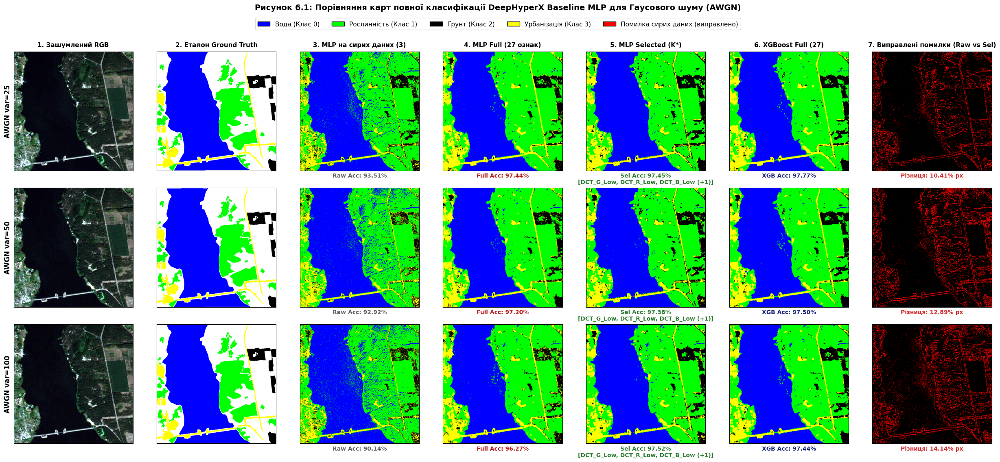

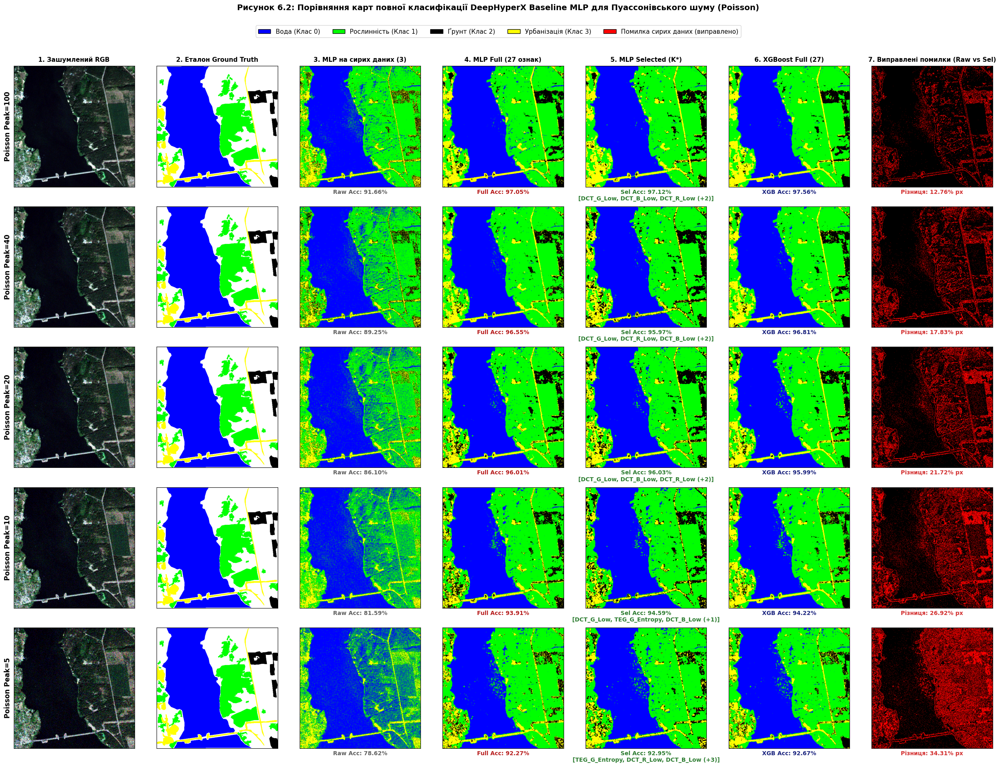

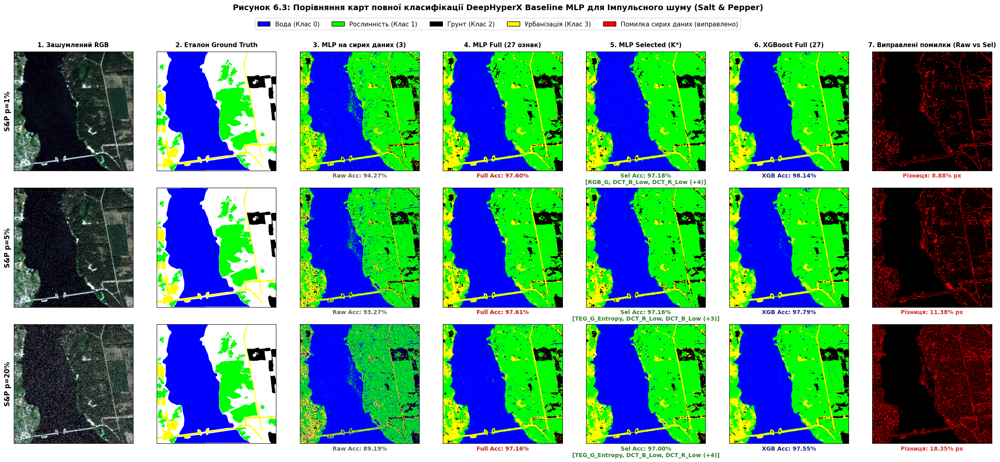

In [92]:
# =============================================================================
# MAIN 6: ВІЗУАЛІЗАЦІЯ КАРТ СЕГМЕНТАЦІЇ MLP ТА ПОРІВНЯННЯ З XGBoost
# =============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def main_step6_visualize_mlp_maps():
    global step5_mlp_results
    
    if "step5_mlp_results" not in globals() or step5_mlp_results is None:
        if os.path.exists("data/step5_mlp_results.npy"):
            print("[i] Завантаження підготовлених результатів Кроку 5 з data/step5_mlp_results.npy...")
            step5_mlp_results = np.load("data/step5_mlp_results.npy", allow_pickle=True).item()
        else:
            raise RuntimeError(
                "ПОМИЛКА: Крок 6 не може бути виконаний без результатів Кроку 5!\n"
                "Будь ласка, спочатку запустіть клітинку Кроку 5 (main_step5_mlp_evaluation()),\n"
                "яка навчає нейромережу MLP, генерує карти класифікації та кешує результати."
            )
            
    groups = [
        ("AWGN", ["AWGN var=25", "AWGN var=50", "AWGN var=100"], "Рисунок 6.1: Порівняння карт повної класифікації DeepHyperX Baseline MLP для Гаусового шуму (AWGN)"),
        ("Poisson", ["Poisson Peak=100", "Poisson Peak=40", "Poisson Peak=20", "Poisson Peak=10", "Poisson Peak=5"], "Рисунок 6.2: Порівняння карт повної класифікації DeepHyperX Baseline MLP для Пуассонівського шуму (Poisson)"),
        ("Impulse", ["S&P p=1%", "S&P p=5%", "S&P p=20%"], "Рисунок 6.3: Порівняння карт повної класифікації DeepHyperX Baseline MLP для Імпульсного шуму (Salt & Pepper)")
    ]
    
    col_titles = [
        "1. Зашумлений RGB",
        "2. Еталон Ground Truth",
        "3. MLP на сирих даних (3)",
        "4. MLP Full (27 ознак)",
        "5. MLP Selected (K*)",
        "6. XGBoost Full (27)",
        "7. Виправлені помилки (Raw vs Sel)"
    ]
    
    legend_elements = [
        Patch(facecolor=(0.0, 0.0, 1.0), edgecolor="black", label="Вода (Клас 0)"),
        Patch(facecolor=(0.0, 1.0, 0.0), edgecolor="black", label="Рослинність (Клас 1)"),
        Patch(facecolor=(0.0, 0.0, 0.0), edgecolor="black", label="Ґрунт (Клас 2)"),
        Patch(facecolor=(1.0, 1.0, 0.0), edgecolor="black", label="Урбанізація (Клас 3)"),
        Patch(facecolor=(1.0, 0.0, 0.0), edgecolor="black", label="Помилка сирих даних (виправлено)")
    ]
    
    for g_title, g_levels, fig_title in groups:
        n_rows = len(g_levels)
        fig, axes = plt.subplots(n_rows, 7, figsize=(25, 3.6 * n_rows))
        if n_rows == 1:
            axes = np.expand_dims(axes, 0)
            
        for r_idx, lvl in enumerate(g_levels):
            cdata = step5_mlp_results["cases_data"][lvl]
            
            # Col 1: Noisy RGB
            axes[r_idx, 0].imshow(cdata["img_rgb"])
            axes[r_idx, 0].set_ylabel(lvl, fontsize=12, fontweight="bold")
            
            # Col 2: GT mask
            axes[r_idx, 1].imshow(step5_mlp_results["gt_mask_rgb"])
            
            # Col 3: MLP Raw RGB
            axes[r_idx, 2].imshow(cdata["color_map_mlp_raw_rgb"])
            axes[r_idx, 2].set_xlabel(f"Raw Acc: {cdata['acc_mlp_raw']*100:.2f}%", fontsize=10, fontweight="bold", color="#616161")
            
            # Col 4: MLP Full 27
            axes[r_idx, 3].imshow(cdata["color_map_mlp_full_rgb"])
            axes[r_idx, 3].set_xlabel(f"Full Acc: {cdata['acc_mlp_full']*100:.2f}%", fontsize=10, fontweight="bold", color="#b71c1c")
            
            # Col 5: MLP Selected K*
            axes[r_idx, 4].imshow(cdata["color_map_mlp_sel_rgb"])
            features_brief = ", ".join(cdata["sel_features"][:3]) + (f" (+{len(cdata['sel_features'])-3})" if len(cdata['sel_features']) > 3 else "")
            axes[r_idx, 4].set_xlabel(f"Sel Acc: {cdata['acc_mlp_sel']*100:.2f}%\n[{features_brief}]", fontsize=10, fontweight="bold", color="#2e7d32")
            
            # Col 6: XGBoost Full
            axes[r_idx, 5].imshow(cdata["color_map_xgb_rgb"])
            axes[r_idx, 5].set_xlabel(f"XGB Acc: {cdata['acc_xgb']*100:.2f}%", fontsize=10, fontweight="bold", color="#1a237e")
            
            # Col 7: Diff map between MLP Raw and MLP Sel
            diff = cdata["diff_raw_sel_rgb"]
            diff_vis = np.zeros((512, 512, 3), dtype=np.uint8)
            diff_vis[diff > 0] = [255, 0, 0]
            axes[r_idx, 6].imshow(diff_vis)
            diff_pct = (np.count_nonzero(diff) / (512 * 512)) * 100.0
            axes[r_idx, 6].set_xlabel(f"Різниця: {diff_pct:.2f}% px", fontsize=10, fontweight="bold", color="#d32f2f")
            
            for c_idx in range(7):
                axes[r_idx, c_idx].set_xticks([])
                axes[r_idx, c_idx].set_yticks([])
                if r_idx == 0:
                    axes[r_idx, c_idx].set_title(col_titles[c_idx], fontsize=11, fontweight="bold", pad=8)
                    
        fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5, fontsize=11, frameon=True)
        fig.suptitle(fig_title, fontsize=14, fontweight="bold", y=1.045)
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    main_step6_visualize_mlp_maps()



### КРОК 7: Дослідження одновимірної згорткової нейромережі 1D-CNN (Hu et al.)

**Мета кроку:** Оцінити ефективність спектрально-просторової згорткової архітектури **1D-CNN (Hu et al.)** для класифікації пікселів в умовах зашумлення у порівнянні з повнозв'язною мережею **MLP (DeepHyperX Baseline NN)** та градієнтним бустингом **XGBoost**.

Як еталонну архітектуру 1D-CNN використано модель **Hu et al.** з репозиторію [DeepHyperX](https://github.com/xiachangxue/DeepHyperX) (*Wei Hu et al., "Deep Convolutional Neural Networks for Hyperspectral Image Classification", Journal of Sensors, 2015*):
* **Архітектура мережі:**
  * **Input:** Вектор ознак пікселя розмірності $[B, 1, C]$, де $C$ — кількість каналів ($3$, $27$ або $K^*$).
  * **1D Згортка:** `Conv1d(in_channels=1, out_channels=20, kernel_size=3, padding=1)` з активацією $\text{Tanh}$.
  * **Пулінг:** `MaxPool1d(kernel_size=pool_size, stride=pool_size)` для агрегації локальних згорткових відгуків.
  * **Повнозв'язний блок:** $\text{Linear}(\text{features\_size}, 100)$ з нелінійністю $\text{Tanh} \rightarrow \text{Linear}(100, 4)$ (виходи класів).
* **Ініціалізація ваг:** Рівномірний розподіл у діапазоні $[-0.05, 0.05]$ (як у статті Hu et al.) з нульовими зсувами.
* **Оптимізація:** Adam (learning rate = $0.005$, weight decay = $10^{-4}$), Cross-Entropy Loss, batch size = $256$, епох = $15$.

---

### Апаратне прискорення та перемикач пристрою (CPU vs GPU):
На початку клітинки наведено явний параметр **`DEVICE_TARGET`**:
* **`"mps"`** — апаратне прискорення на графічному процесорі Apple Silicon (Metal Performance Shaders).
* **`"cpu"`** — виконання на центральному процесорі.
* **`"cuda"`** — прискорення на NVIDIA GPU.
* **`"auto"`** — автоматичний вибір доступного прискорювача.

---

### Порівнювані конфігурації вхідних даних:
1. **`1D-CNN Raw (3)` — Бейзлайн сирих даних:** класифікація лише за 3 значеннями кольору $(R, G, B)$ без частотного контексту.
2. **`1D-CNN Full (27)` — Повний словник ознак:** 9 кільцевих енергій 2D-ДКП + 3 сирих RGB + 15 просторово-статистичних дескрипторів TEG.
3. **`1D-CNN Selected (K*)` — Оптимізований компактний підпростір:** відібрані інформативні ознаки ($K^* \in [4, 7]$).

---

### Формуються 2 аналітичні таблиці Кроку 7:
1. **ТАБЛИЦЯ 1: Хронометраж 1D-CNN (Hu et al.) на обраному пристрої [CPU/GPU]**
   * Час підготовки даних, навчання (`fit`) та інференсу для тесту (93 324 пікс.) і повної сцени (262 144 пікс.).
2. **ТАБЛИЦЯ 2: Порівняння якості: 1D-CNN vs MLP vs XGBoost**
   * Точність **Accuracy (%)** та **F1-Score (Macro)**.
   * Дельти якості $\Delta(\text{CNN} - \text{XGB})$ та $\Delta(\text{CNN} - \text{MLP})$.
   * **Чистий виграш над сирими даними:** $\text{Gain} = \text{Acc}_{\text{CNN Sel}} - \text{Acc}_{\text{CNN Raw}}$, що демонструє внесок ознак ДКП/TEG.


[*] Обраний пристрій для виконання 1D-CNN: mps (MPS)

ТАБЛИЦЯ 1: Хронометраж 1D-CNN (Hu et al.) на пристрої MPS (Train: 47,938 px | Test: 93,324 px | Full: 262,144 px)
Тип шуму   | Випадок / Рівень   | K*  |  Raw Fit  Raw Inf | Підг. Full  Fit Full  Full Inf | Підг. Sel  Fit Sel  Full Inf |  Прискорення
---------------------------------------------------------------------------------------------------------------------------------------
AWGN       | AWGN var=25        | 4   |    7.97с   0.552с |     0.597с     6.23с    0.387с |    0.046с    5.74с    0.361с |        3.43x
AWGN       | AWGN var=50        | 4   |    5.17с   0.357с |     0.618с     5.84с    0.383с |    0.046с    5.83с    0.462с |        2.81x
AWGN       | AWGN var=100       | 4   |    5.15с   0.359с |     0.701с     5.88с    0.452с |    0.046с    5.76с    0.351с |        3.75x
Poisson    | Poisson Peak=100   | 5   |    5.55с   0.430с |     0.545с     5.98с    0.483с |    0.546с    5.87с    0.354с |        1.05x
Poisson    

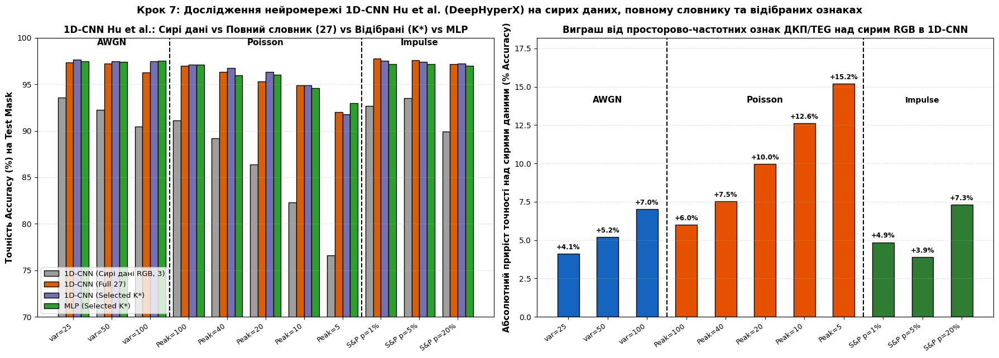

In [93]:
# =============================================================================
# MAIN 7: ДОСЛІДЖЕННЯ 1D-CNN (Hu et al., DeepHyperX) ТА ПОРІВНЯННЯ З MLP ТА XGBoost
# =============================================================================
import os
import io
import time
import math
import cv2
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# НАЛАШТУВАННЯ ПРИСТРОЮ (DEVICE SWITCH: CPU vs GPU)
# -----------------------------------------------------------------------------
# Опції: "mps" (Apple GPU), "cpu" (процесор), "cuda" (NVIDIA GPU), "auto" (автовибір)
DEVICE_TARGET = "mps"  # <--- ПЕРЕМИКАЧ: змініть на "cpu" або "mps"/"cuda" для порівняння!

if DEVICE_TARGET == "cpu":
    device = torch.device("cpu")
elif DEVICE_TARGET == "mps" and hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
elif DEVICE_TARGET == "cuda" and torch.cuda.is_available():
    device = torch.device("cuda")
else:
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    elif torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")

print(f"[*] Обраний пристрій для виконання 1D-CNN: {device} ({str(device).upper()})")

global step7_cnn_results

# -----------------------------------------------------------------------------
# Архітектура 1D-CNN Hu et al. (2015)
# Source: DeepHyperX (xiachangxue / Nicolas Brodu / nshaud)
# -----------------------------------------------------------------------------
class HuEtAl_1D_CNN(nn.Module):
    """
    Deep Convolutional Neural Networks for Hyperspectral Image Classification
    Wei Hu, Yangyu Huang, Li Wei, Fan Zhang and Hengchao Li
    Journal of Sensors, Volume 2015 (2015).
    """
    @staticmethod
    def weight_init(m):
        if isinstance(m, (nn.Linear, nn.Conv1d)):
            init.uniform_(m.weight, -0.05, 0.05)
            if m.bias is not None:
                init.zeros_(m.bias)

    def _get_final_flattened_size(self):
        with torch.no_grad():
            x = torch.zeros(1, 1, self.input_channels)
            x = self.conv(x)
            x = self.pool(x)
            return x.numel()

    def __init__(self, input_channels, n_classes=4, kernel_size=3, pool_size=None):
        super(HuEtAl_1D_CNN, self).__init__()
        self.input_channels = input_channels
        if pool_size is None:
            pool_size = 2 if input_channels >= 4 else 1
            
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=20, kernel_size=kernel_size, padding=kernel_size // 2),
            nn.Tanh()
        )
        self.pool = nn.MaxPool1d(kernel_size=pool_size, stride=pool_size)
        self.features_size = self._get_final_flattened_size()
        
        self.fc1 = nn.Linear(self.features_size, 100)
        self.fc2 = nn.Linear(100, n_classes)
        self.apply(self.weight_init)

    def forward(self, x):
        if len(x.shape) == 2:
            x = x.unsqueeze(1)  # [batch_size, 1, input_channels]
        x = self.conv(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = torch.tanh(self.fc1(x))
        x = self.fc2(x)
        return x

def train_and_eval_1d_cnn(X_tr, y_tr, X_te, y_te, X_fl, device, epochs=15, batch_size=256, h=512, w=512):
    t0 = time.perf_counter()
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)
    X_fl_s = scaler.transform(X_fl)
    
    train_dataset = TensorDataset(torch.FloatTensor(X_tr_s), torch.LongTensor(y_tr))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    t_prep = time.perf_counter() - t0
    
    model = HuEtAl_1D_CNN(input_channels=X_tr.shape[1], n_classes=4).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    t0 = time.perf_counter()
    model.train()
    for ep in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
    t_train = time.perf_counter() - t0
    
    # Інференс на тесті (93,324 px)
    t0 = time.perf_counter()
    model.eval()
    test_loader = DataLoader(TensorDataset(torch.FloatTensor(X_te_s)), batch_size=2048, shuffle=False)
    preds_test = []
    with torch.no_grad():
        for (bx,) in test_loader:
            bx = bx.to(device)
            preds_test.extend(torch.argmax(model(bx), dim=1).cpu().numpy())
    t_inf_test = time.perf_counter() - t0
    
    acc_test = accuracy_score(y_te, preds_test)
    f1_test = f1_score(y_te, preds_test, average="macro")
    
    # Інференс на повному знімку (262,144 px)
    t0 = time.perf_counter()
    full_loader = DataLoader(TensorDataset(torch.FloatTensor(X_fl_s)), batch_size=4096, shuffle=False)
    preds_full = []
    with torch.no_grad():
        for (bx,) in full_loader:
            bx = bx.to(device)
            preds_full.extend(torch.argmax(model(bx), dim=1).cpu().numpy())
    t_inf_full = time.perf_counter() - t0
    
    pred_map = np.array(preds_full, dtype=np.uint8).reshape(h, w)
    
    return {
        "acc": acc_test,
        "f1": f1_test,
        "t_prep": t_prep,
        "t_train": t_train,
        "t_inf_test": t_inf_test,
        "t_inf_full": t_inf_full,
        "pred_map": pred_map
    }

def main_step7_1d_cnn_evaluation():
    global step7_cnn_results
    
    if os.path.exists("data/step3_classification_results.npy"):
        step3_data = np.load("data/step3_classification_results.npy", allow_pickle=True).item()
    else:
        raise RuntimeError("Помилка: Не знайдено data/step3_classification_results.npy. Спочатку запустіть Крок 3!")

    if os.path.exists("data/step5_mlp_results.npy"):
        step5_data = np.load("data/step5_mlp_results.npy", allow_pickle=True).item()
    else:
        raise RuntimeError("Помилка: Не знайдено data/step5_mlp_results.npy. Спочатку запустіть Крок 5!")

    color_to_class = {(255, 0, 0): 0, (0, 255, 0): 1, (0, 0, 0): 2, (0, 255, 255): 3}
    class_colors_rgb = {
        0: (0, 0, 255),    # Вода — синій (RGB)
        1: (0, 255, 0),    # Рослинність — зелений
        2: (0, 0, 0),      # Ґрунт — чорний
        3: (255, 255, 0)   # Урбанізація — жовтий
    }

    def colorize_pred_map(pred_map):
        h, w = pred_map.shape[:2]
        rgb = np.full((h, w, 3), 255, dtype=np.uint8)
        for c_id, col in class_colors_rgb.items():
            rgb[pred_map == c_id] = col
        return rgb

    train_mask = cv2.imread("data/SS1_spatial_train_pool.bmp", cv2.IMREAD_COLOR)
    test_mask = cv2.imread("data/SS1_spatial_test.bmp", cv2.IMREAD_COLOR)
    gt_mask = cv2.imread("data/SS1_ground_truth.bmp", cv2.IMREAD_COLOR)

    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    test_coords, y_test = extract_coords_and_labels(test_mask, color_to_class)
    h, w = train_mask.shape[:2]
    full_coords = [(y, x) for y in range(h) for x in range(w)]

    cases = [
        ("AWGN", "AWGN var=25", "data/SS1_awgn_var_25.bmp"),
        ("AWGN", "AWGN var=50", "data/SS1_awgn_var_50.bmp"),
        ("AWGN", "AWGN var=100", "data/SS1_awgn_var_100.bmp"),
        ("Poisson", "Poisson Peak=100", "data/SS1_poisson_peak_100.bmp"),
        ("Poisson", "Poisson Peak=40", "data/SS1_poisson_peak_40.bmp"),
        ("Poisson", "Poisson Peak=20", "data/SS1_poisson_peak_20.bmp"),
        ("Poisson", "Poisson Peak=10", "data/SS1_poisson_peak_10.bmp"),
        ("Poisson", "Poisson Peak=5", "data/SS1_poisson_peak_5.bmp"),
        ("Impulse", "S&P p=1%", "data/SS1_sp_1pct.bmp"),
        ("Impulse", "S&P p=5%", "data/SS1_sp_5pct.bmp"),
        ("Impulse", "S&P p=20%", "data/SS1_sp_20pct.bmp")
    ]

    cnn_timing_records = []
    cnn_comparison_records = []
    step7_cnn_results = {
        "device": str(device),
        "gt_mask_rgb": cv2.cvtColor(gt_mask, cv2.COLOR_BGR2RGB),
        "cases_data": {}
    }

    for ntype, label, path in cases:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        cdata_step3 = step3_data["cases_data"][label]
        cdata_step5 = step5_data["cases_data"][label]
        sel_fnames = cdata_step3["sel_features"]
        k_star = len(sel_fnames)
        
        # 0. Raw RGB (3 ознаки)
        X_tr_raw, t_ext_tr_raw, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=True, use_dct=False, use_teg=False)
        X_te_raw, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=False, use_teg=False)
        X_fl_raw, t_ext_fl_raw, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=False, use_teg=False)
        res_raw = train_and_eval_1d_cnn(X_tr_raw, y_train, X_te_raw, y_test, X_fl_raw, device, epochs=15, h=h, w=w)
        
        # 1. Full 27 features
        X_tr_27, t_ext_tr_27, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=True, use_dct=True, use_teg=True)
        X_te_27, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=True, use_teg=True)
        X_fl_27, t_ext_fl_27, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=True, use_teg=True)
        res_full = train_and_eval_1d_cnn(X_tr_27, y_train, X_te_27, y_test, X_fl_27, device, epochs=15, h=h, w=w)
        
        # 2. Selected K* features
        has_teg = any(f.startswith("TEG_") for f in sel_fnames)
        has_dct = any(f.startswith("DCT_") for f in sel_fnames)
        has_rgb = any(f.startswith("RGB_") for f in sel_fnames)
        meta_sub = build_feature_metadata({"USE_RGB": has_rgb, "USE_DCT": has_dct, "USE_TEG": has_teg})
        sub_name_to_idx = {m["name"]: i for i, m in enumerate(meta_sub)}
        active_indices = [sub_name_to_idx[fn] for fn in sel_fnames]
        
        X_tr_sub, t_ext_tr_sel, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_te_sub, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_fl_sub, t_ext_fl_sel, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        
        X_tr_sel = X_tr_sub[:, active_indices]
        X_te_sel = X_te_sub[:, active_indices]
        X_fl_sel = X_fl_sub[:, active_indices]
        res_sel = train_and_eval_1d_cnn(X_tr_sel, y_train, X_te_sel, y_test, X_fl_sel, device, epochs=15, h=h, w=w)
        
        cnn_timing_records.append({
            "noise_type": ntype, "level": label, "k_star": k_star,
            "raw_train": res_raw["t_train"], "raw_inf_full": res_raw["t_inf_full"],
            "full_prep": res_full["t_prep"] + t_ext_tr_27, "full_train": res_full["t_train"], "full_inf_full": res_full["t_inf_full"],
            "sel_prep": res_sel["t_prep"] + t_ext_tr_sel, "sel_train": res_sel["t_train"], "sel_inf_full": res_sel["t_inf_full"],
            "speedup_full_scene": (t_ext_fl_27 + res_full["t_inf_full"]) / (t_ext_fl_sel + res_sel["t_inf_full"])
        })
        
        xgb_acc = cdata_step3["acc_full"]
        xgb_acc_sel = cdata_step3["acc_sel"]
        mlp_acc_sel = cdata_step5["acc_mlp_sel"]
        gain_over_raw = res_sel["acc"] - res_raw["acc"]
        
        cnn_comparison_records.append({
            "noise_type": ntype, "level": label, "k_star": k_star, "sel_features": sel_fnames,
            "cnn_acc_raw": res_raw["acc"], "cnn_f1_raw": res_raw["f1"],
            "cnn_acc_full": res_full["acc"], "cnn_f1_full": res_full["f1"],
            "cnn_acc_sel": res_sel["acc"], "cnn_f1_sel": res_sel["f1"],
            "mlp_acc_sel": mlp_acc_sel, "xgb_acc_sel": xgb_acc_sel,
            "delta_cnn_xgb": res_sel["acc"] - xgb_acc_sel,
            "delta_cnn_mlp": res_sel["acc"] - mlp_acc_sel,
            "gain_over_raw": gain_over_raw
        })
        
        diff_raw_sel = (res_raw["pred_map"] != res_sel["pred_map"]).astype(np.uint8) * 255
        
        step7_cnn_results["cases_data"][label] = {
            "noise_type": ntype, "label": label, "img_rgb": cdata_step3["img_rgb"],
            "k_star": k_star, "sel_features": sel_fnames,
            "acc_cnn_raw": res_raw["acc"], "acc_cnn_full": res_full["acc"],
            "acc_cnn_sel": res_sel["acc"], "acc_mlp_sel": mlp_acc_sel, "acc_xgb_sel": xgb_acc_sel,
            "color_map_cnn_raw_rgb": colorize_pred_map(res_raw["pred_map"]),
            "color_map_cnn_full_rgb": colorize_pred_map(res_full["pred_map"]),
            "color_map_cnn_sel_rgb": colorize_pred_map(res_sel["pred_map"]),
            "color_map_mlp_sel_rgb": cdata_step5["color_map_mlp_sel_rgb"],
            "diff_raw_sel_rgb": diff_raw_sel
        }

    np.save("data/step7_1d_cnn_results.npy", step7_cnn_results, allow_pickle=True)

    # ДРУК ТАБЛИЦІ 1
    print("=" * 135)
    print(f"ТАБЛИЦЯ 1: Хронометраж 1D-CNN (Hu et al.) на пристрої {str(device).upper()} (Train: 47,938 px | Test: 93,324 px | Full: 262,144 px)")
    print("=" * 135)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'K*':<3} | {'Raw Fit':>8} {'Raw Inf':>8} | {'Підг. Full':>10} {'Fit Full':>9} {'Full Inf':>9} | {'Підг. Sel':>9} {'Fit Sel':>8} {'Full Inf':>9} | {'Прискорення':>12}")
    print("-" * 135)
    for r in cnn_timing_records:
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {r['k_star']:<3} | {r['raw_train']:>7.2f}с {r['raw_inf_full']:>7.3f}с | {r['full_prep']:>9.3f}с {r['full_train']:>8.2f}с {r['full_inf_full']:>8.3f}с | {r['sel_prep']:>8.3f}с {r['sel_train']:>7.2f}с {r['sel_inf_full']:>8.3f}с | {r['speedup_full_scene']:>11.2f}x")
    print("-" * 135)

    # ДРУК ТАБЛИЦІ 2
    print("\n" + "=" * 145)
    print("ТАБЛИЦЯ 2: Порівняння якості: 1D-CNN Hu et al. vs MLP (Baseline NN) vs XGBoost (Test Mask: 93,324 px)")
    print("=" * 145)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'1D-CNN Raw (3)':<17} | {'1D-CNN Full':>11} {'1D-CNN Sel':>10} | {'MLP Sel':>8} {'XGB Sel':>8} | {'Δ(CNN-XGB)':>10} {'Δ(CNN-MLP)':>10} | {'Приріст над Raw':>16}")
    print("-" * 145)
    for r in cnn_comparison_records:
        raw_str = f"{r['cnn_acc_raw']*100:.2f}% / {r['cnn_f1_raw']:.4f}"
        delta_xgb_str = f"{r['delta_cnn_xgb']*100:+.2f}%"
        delta_mlp_str = f"{r['delta_cnn_mlp']*100:+.2f}%"
        gain_raw_str = f"+{r['gain_over_raw']*100:.2f}%"
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {raw_str:<17} | {r['cnn_acc_full']*100:>10.2f}% {r['cnn_acc_sel']*100:>9.2f}% | {r['mlp_acc_sel']*100:>7.2f}% {r['xgb_acc_sel']*100:>7.2f}% | {delta_xgb_str:>10} {delta_mlp_str:>10} | {gain_raw_str:>16}")
    print("-" * 145)

    # ВІЗУАЛІЗАЦІЯ
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))
    x_labels = [r["level"].replace("AWGN ", "").replace("Poisson ", "") for r in cnn_comparison_records]
    x_pos = np.arange(len(x_labels))
    bar_w = 0.20

    cnn_raw_vals = [r["cnn_acc_raw"] * 100 for r in cnn_comparison_records]
    cnn_full_vals = [r["cnn_acc_full"] * 100 for r in cnn_comparison_records]
    cnn_sel_vals = [r["cnn_acc_sel"] * 100 for r in cnn_comparison_records]
    mlp_sel_vals = [r["mlp_acc_sel"] * 100 for r in cnn_comparison_records]

    ax1.bar(x_pos - 1.5*bar_w, cnn_raw_vals, bar_w, label="1D-CNN (Сирі дані RGB, 3)", color="#9e9e9e", edgecolor="black")
    ax1.bar(x_pos - 0.5*bar_w, cnn_full_vals, bar_w, label="1D-CNN (Full 27)", color="#d95f02", edgecolor="black")
    ax1.bar(x_pos + 0.5*bar_w, cnn_sel_vals, bar_w, label="1D-CNN (Selected K*)", color="#7570b3", edgecolor="black")
    ax1.bar(x_pos + 1.5*bar_w, mlp_sel_vals, bar_w, label="MLP (Selected K*)", color="#2ca02c", edgecolor="black")

    ax1.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax1.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax1.text(1.0, 99.2, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax1.text(5.0, 99.2, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax1.text(9.0, 99.2, "Impulse", ha="center", fontsize=11, fontweight="bold")

    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax1.set_ylabel("Точність Accuracy (%) на Test Mask", fontsize=11, fontweight="bold")
    ax1.set_ylim(70, 100)
    ax1.set_title("1D-CNN Hu et al.: Сирі дані vs Повний словник (27) vs Відібрані (K*) vs MLP", fontsize=12, fontweight="bold")
    ax1.grid(axis="y", linestyle=":", alpha=0.6)
    ax1.legend(loc="lower left", fontsize=9.5)

    gains_vals = [r["gain_over_raw"] * 100 for r in cnn_comparison_records]
    colors_gain = ["#1565c0" if "AWGN" in r["noise_type"] else ("#e65100" if "Poisson" in r["noise_type"] else "#2e7d32") for r in cnn_comparison_records]

    ax2.bar(x_pos, gains_vals, width=0.55, color=colors_gain, edgecolor="black")
    ax2.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax2.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax2.text(1.0, max(gains_vals)*0.92, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax2.text(5.0, max(gains_vals)*0.92, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax2.text(9.0, max(gains_vals)*0.92, "Impulse", ha="center", fontsize=10, fontweight="bold")

    for i, g in enumerate(gains_vals):
        ax2.text(x_pos[i], g + 0.3, f"+{g:.1f}%", ha="center", fontsize=8.5, fontweight="bold")

    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax2.set_ylabel("Абсолютний приріст точності над сирими даними (% Accuracy)", fontsize=11, fontweight="bold")
    ax2.set_ylim(0, max(gains_vals) + 3.0)
    ax2.set_title("Виграш від просторово-частотних ознак ДКП/TEG над сирим RGB в 1D-CNN", fontsize=12, fontweight="bold")
    ax2.grid(axis="y", linestyle=":", alpha=0.6)

    fig.suptitle("Крок 7: Дослідження нейромережі 1D-CNN Hu et al. (DeepHyperX) на сирих даних, повному словнику та відібраних ознаках", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main_step7_1d_cnn_evaluation()



### КРОК 8: Візуалізація карт повної класифікації 1D-CNN Hu et al.

#### Архітектурна залежність від Кроку 7:
Ця клітинка є презентаційним шаром для порівняння сегментаційних карт, згенерованих згортковою нейромережею **1D-CNN (Hu et al.)** на сирих даних, повному словнику ознак та відібраних ознаках $K^*$, проти результатів **MLP Selected** та еталону **Ground Truth**.

**Що саме використовується з Кроку 7:**
1. **Зашумлені вхідні знімки (`img_rgb`):** Візуальний контекст спотворення для кожного з 11 випадків.
2. **Еталонна маска розмітки (`gt_mask_rgb`):** Ground Truth розміром $512\times512$.
3. **Карта класифікації 1D-CNN на сирих даних (`color_map_cnn_raw_rgb`):** Сегментація лише за 3 значеннями RGB без просторового контексту (демонструє велику кількість шумових помилок).
4. **Карта класифікації 1D-CNN Full (`color_map_cnn_full_rgb`):** Сегментація на повному словнику з 27 ознак.
5. **Карта класифікації 1D-CNN Selected ($K^*$) (`color_map_cnn_sel_rgb`):** Сегментація на компактному наборі відібраних ознак.
6. **Карта класифікації MLP Selected ($K^*$) (`color_map_mlp_sel_rgb`):** Порівняльний результат повнозв'язної мережі.
7. **Карта виправлених помилок (`diff_raw_sel_rgb`):** Червоним кольором підсвічено пікселі, де класифікація на сирих даних помилялася, але була виправлена за рахунок застосування відібраних ознак ДКП/TEG у 1D-CNN.

**Чому Крок 8 не буде працювати без Кроку 7:**
Застосовано патерн **Separation of Concerns**. Крок 8 використовує кешовані дані `step7_cnn_results` (або завантажує `data/step7_1d_cnn_results.npy`), що усуває потребу повторного прогону тензорів через 262,144 пікселі.


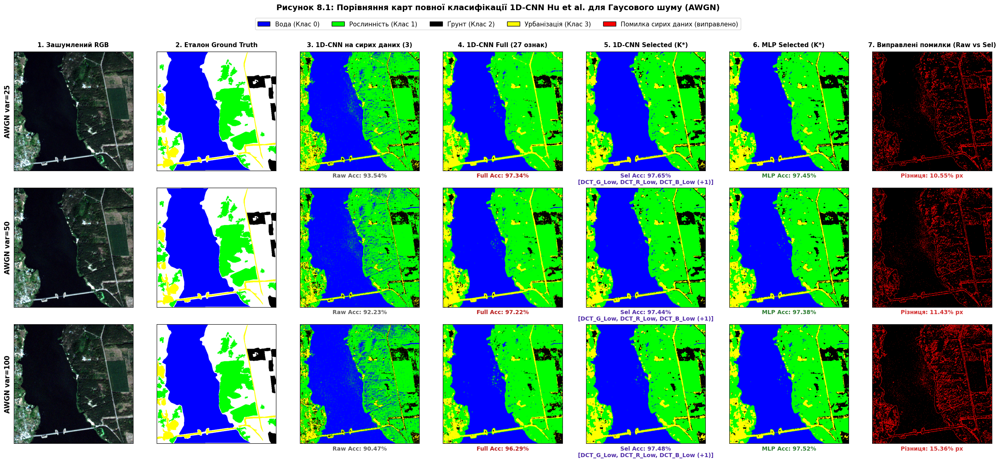

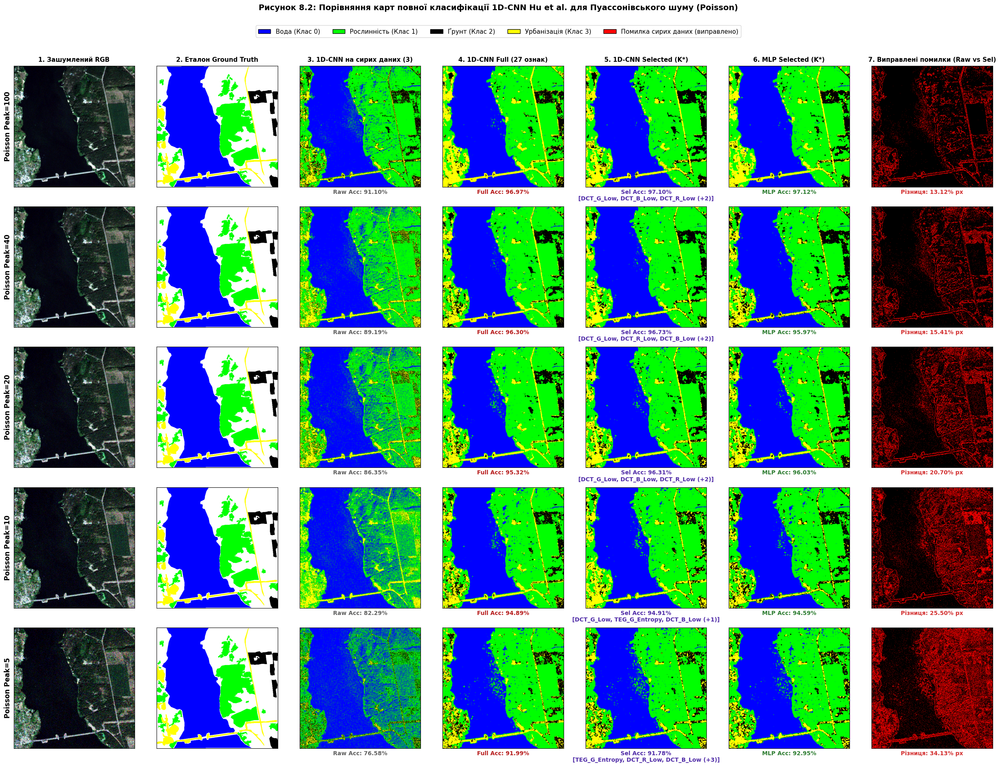

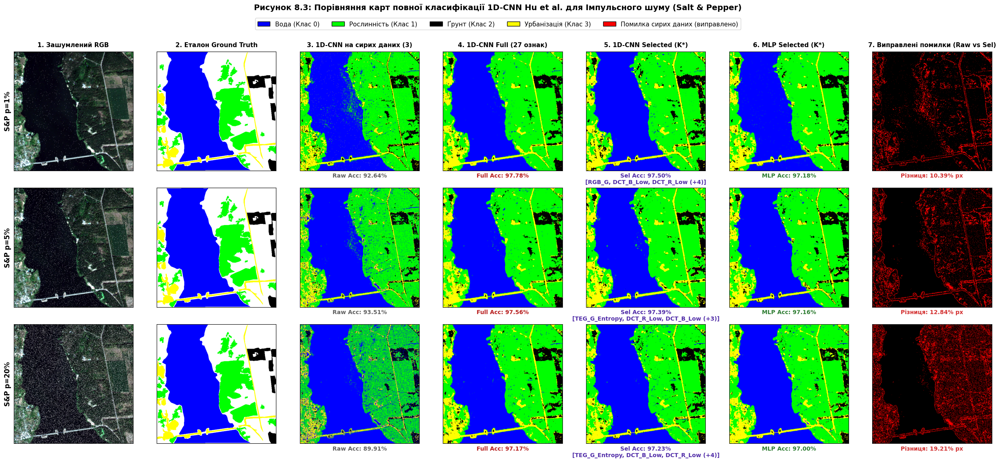

In [94]:
# =============================================================================
# MAIN 8: ВІЗУАЛІЗАЦІЯ КАРТ СЕГМЕНТАЦІЇ 1D-CNN ТА ПОРІВНЯННЯ З MLP
# =============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def main_step8_visualize_1d_cnn_maps():
    global step7_cnn_results
    
    if "step7_cnn_results" not in globals() or step7_cnn_results is None:
        if os.path.exists("data/step7_1d_cnn_results.npy"):
            print("[i] Завантаження підготовлених результатів Кроку 7 з data/step7_1d_cnn_results.npy...")
            step7_cnn_results = np.load("data/step7_1d_cnn_results.npy", allow_pickle=True).item()
        else:
            raise RuntimeError(
                "ПОМИЛКА: Крок 8 не може бути виконаний без результатів Кроку 7!\n"
                "Будь ласка, спочатку запустіть клітинку Кроку 7 (main_step7_1d_cnn_evaluation()),\n"
                "яка навчає нейромережу 1D-CNN, генерує карти класифікації та кешує результати."
            )
            
    groups = [
        ("AWGN", ["AWGN var=25", "AWGN var=50", "AWGN var=100"], "Рисунок 8.1: Порівняння карт повної класифікації 1D-CNN Hu et al. для Гаусового шуму (AWGN)"),
        ("Poisson", ["Poisson Peak=100", "Poisson Peak=40", "Poisson Peak=20", "Poisson Peak=10", "Poisson Peak=5"], "Рисунок 8.2: Порівняння карт повної класифікації 1D-CNN Hu et al. для Пуассонівського шуму (Poisson)"),
        ("Impulse", ["S&P p=1%", "S&P p=5%", "S&P p=20%"], "Рисунок 8.3: Порівняння карт повної класифікації 1D-CNN Hu et al. для Імпульсного шуму (Salt & Pepper)")
    ]
    
    col_titles = [
        "1. Зашумлений RGB",
        "2. Еталон Ground Truth",
        "3. 1D-CNN на сирих даних (3)",
        "4. 1D-CNN Full (27 ознак)",
        "5. 1D-CNN Selected (K*)",
        "6. MLP Selected (K*)",
        "7. Виправлені помилки (Raw vs Sel)"
    ]
    
    legend_elements = [
        Patch(facecolor=(0.0, 0.0, 1.0), edgecolor="black", label="Вода (Клас 0)"),
        Patch(facecolor=(0.0, 1.0, 0.0), edgecolor="black", label="Рослинність (Клас 1)"),
        Patch(facecolor=(0.0, 0.0, 0.0), edgecolor="black", label="Ґрунт (Клас 2)"),
        Patch(facecolor=(1.0, 1.0, 0.0), edgecolor="black", label="Урбанізація (Клас 3)"),
        Patch(facecolor=(1.0, 0.0, 0.0), edgecolor="black", label="Помилка сирих даних (виправлено)")
    ]
    
    for g_title, g_levels, fig_title in groups:
        n_rows = len(g_levels)
        fig, axes = plt.subplots(n_rows, 7, figsize=(25, 3.6 * n_rows))
        if n_rows == 1:
            axes = np.expand_dims(axes, 0)
            
        for r_idx, lvl in enumerate(g_levels):
            cdata = step7_cnn_results["cases_data"][lvl]
            
            # Col 1: Noisy RGB
            axes[r_idx, 0].imshow(cdata["img_rgb"])
            axes[r_idx, 0].set_ylabel(lvl, fontsize=12, fontweight="bold")
            
            # Col 2: GT mask
            axes[r_idx, 1].imshow(step7_cnn_results["gt_mask_rgb"])
            
            # Col 3: 1D-CNN Raw RGB
            axes[r_idx, 2].imshow(cdata["color_map_cnn_raw_rgb"])
            axes[r_idx, 2].set_xlabel(f"Raw Acc: {cdata['acc_cnn_raw']*100:.2f}%", fontsize=10, fontweight="bold", color="#616161")
            
            # Col 4: 1D-CNN Full 27
            axes[r_idx, 3].imshow(cdata["color_map_cnn_full_rgb"])
            axes[r_idx, 3].set_xlabel(f"Full Acc: {cdata['acc_cnn_full']*100:.2f}%", fontsize=10, fontweight="bold", color="#b71c1c")
            
            # Col 5: 1D-CNN Selected K*
            axes[r_idx, 4].imshow(cdata["color_map_cnn_sel_rgb"])
            features_brief = ", ".join(cdata["sel_features"][:3]) + (f" (+{len(cdata['sel_features'])-3})" if len(cdata['sel_features']) > 3 else "")
            axes[r_idx, 4].set_xlabel(f"Sel Acc: {cdata['acc_cnn_sel']*100:.2f}%\n[{features_brief}]", fontsize=10, fontweight="bold", color="#512da8")
            
            # Col 6: MLP Selected K*
            axes[r_idx, 5].imshow(cdata["color_map_mlp_sel_rgb"])
            axes[r_idx, 5].set_xlabel(f"MLP Acc: {cdata['acc_mlp_sel']*100:.2f}%", fontsize=10, fontweight="bold", color="#2e7d32")
            
            # Col 7: Diff map between 1D-CNN Raw and 1D-CNN Sel
            diff = cdata["diff_raw_sel_rgb"]
            diff_vis = np.zeros((512, 512, 3), dtype=np.uint8)
            diff_vis[diff > 0] = [255, 0, 0]
            axes[r_idx, 6].imshow(diff_vis)
            diff_pct = (np.count_nonzero(diff) / (512 * 512)) * 100.0
            axes[r_idx, 6].set_xlabel(f"Різниця: {diff_pct:.2f}% px", fontsize=10, fontweight="bold", color="#d32f2f")
            
            for c_idx in range(7):
                axes[r_idx, c_idx].set_xticks([])
                axes[r_idx, c_idx].set_yticks([])
                if r_idx == 0:
                    axes[r_idx, c_idx].set_title(col_titles[c_idx], fontsize=11, fontweight="bold", pad=8)
                    
        fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5, fontsize=11, frameon=True)
        fig.suptitle(fig_title, fontsize=14, fontweight="bold", y=1.045)
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    main_step8_visualize_1d_cnn_maps()



### КРОК 9: Дослідження архітектури TabNet (Arik & Pfister, Google Cloud AI, AAAI 2021)

**Мета кроку:** Оцінити якість класифікації, інтерпретованість та обчислювальну стійкість нейромережі **TabNet** (*Sercan O. Arik & Tomas Pfister, Google Cloud AI, "TabNet: Attentive Interpretable Tabular Learning", AAAI 2021*), яка є сучасним де-факто стандартом (2021–2026) для глибокого навчання на табличних і багатоканальних просторових дескрипторах у дистанційному зондуванні Землі (ДДЗ).

#### Архітектурні особливості TabNet:
* **Покроковий механізм уваги (Sequential Decision Steps):** Замість обробки всіх ознак одночасно, мережа виконує послідовність кроків прийняття рішень ($N_{\text{steps}} = 3$), на кожному з яких фокусується на найбільш релевантних каналах.
* **Блок уваги (Attentive Transformer):** 
  * Розраховує розріджену маску уваги $M[i]$ для відбору ознак на кожному кроці $i$.
  * Використовує динамічну шкалу попереднього використання (Prior Scale $P[i] = \prod (\gamma - M[i])$), що регулює частоту повторного використання тих самих ознак.
* **Блок трансформації ознак (Feature Transformer):** 
  * Складається з шарів вентильованих лінійних блоків (**Gated Linear Units, GLU**), розділених на спільні (shared) та незалежні (step-dependent) шари з залишковими зв'язками (Residual scaling $\sqrt{0.5}$).
  * Поділ виходу на дві частини: вектор рішень $d[i] \in \mathbb{R}^{n_d}$ (активується $\text{ReLU}$ для фінального виходу) та вектор уваги $a[i] \in \mathbb{R}^{n_a}$ (передається на наступний крок уваги).
* **Фінальна агрегація:** $D_{\text{total}} = \sum_{i=1}^{N_{\text{steps}}} d[i] \rightarrow \text{Linear}(n_d, 4)$ (класи покриття).

---

### Апаратне прискорення та перемикач пристрою (CPU vs GPU):
На початку клітинки наведено явний параметр **`DEVICE_TARGET`**:
* **`"mps"`** — апаратне прискорення на графічному процесорі Apple Silicon.
* **`"cpu"`** — виконання на центральному процесорі.
* **`"cuda"`** — прискорення на NVIDIA GPU.
* **`"auto"`** — автоматичний вибір доступного прискорювача.

---

### Досліджувані конфігурації вхідних даних для TabNet:
1. **`TabNet Raw (3)` — Бейзлайн сирих даних:** нейромережа навчається виключно на 3 каналах RGB поточного пікселя.
2. **`TabNet Full (27)` — Повний словник ознак:** 9 кільцевих енергій 2D-ДКП + 3 сирих RGB + 15 дескрипторів TEG.
3. **`TabNet Selected (K*)` — Оптимізований компактний підпростір:** відібрані інформативні ознаки ($K^* \in [4, 7]$).

---

### Формуються 2 аналітичні таблиці Кроку 9:
1. **ТАБЛИЦЯ 1: Хронометраж TabNet (Arik & Pfister) на обраному пристрої [CPU/GPU]**
   * Час підготовки даних, навчання (`fit`) та інференсу для тесту (93 324 пікс.) і повної сцени (262 144 пікс.).
2. **ТАБЛИЦЯ 2: Порівняння якості: TabNet vs 1D-CNN vs MLP vs XGBoost**
   * Точність **Accuracy (%)** та **F1-Score (Macro)**.
   * Дельти порівняння $\Delta(\text{Tab} - \text{XGB})$, $\Delta(\text{Tab} - \text{CNN})$ та $\Delta(\text{Tab} - \text{MLP})$.
   * **Чистий виграш над сирими даними:** $\text{Gain} = \text{Acc}_{\text{Tab Sel}} - \text{Acc}_{\text{Tab Raw}}$.


[*] Обраний пристрій для виконання TabNet: mps (MPS)

ТАБЛИЦЯ 1: Хронометраж TabNet (Arik & Pfister) на пристрої MPS (Train: 47,938 px | Test: 93,324 px | Full: 262,144 px)
Тип шуму   | Випадок / Рівень   | K*  |  Raw Fit  Raw Inf | Підг. Full  Fit Full  Full Inf | Підг. Sel  Fit Sel  Full Inf |  Прискорення
---------------------------------------------------------------------------------------------------------------------------------------
AWGN       | AWGN var=25        | 4   |   19.63с   0.506с |     0.685с    14.68с    0.592с |    0.047с   15.39с    0.454с |        3.26x
AWGN       | AWGN var=50        | 4   |   14.51с   0.501с |     0.628с    13.90с    0.561с |    0.046с   14.57с    0.456с |        3.21x
AWGN       | AWGN var=100       | 4   |   14.56с   0.434с |     0.742с    13.81с    0.443с |    0.047с   15.07с    0.573с |        2.44x
Poisson    | Poisson Peak=100   | 5   |   15.23с   0.485с |     0.555с    14.05с    0.466с |    0.535с   15.85с    0.478с |        0.98x
Poisso

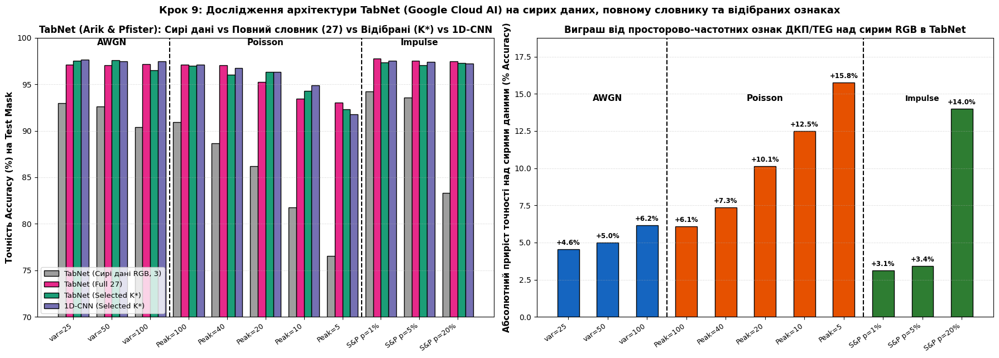

In [95]:
# =============================================================================
# MAIN 9: ДОСЛІДЖЕННЯ TabNet (Arik & Pfister, Google Cloud AI, AAAI 2021)
# =============================================================================
import os
import io
import time
import math
import cv2
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# НАЛАШТУВАННЯ ПРИСТРОЮ (DEVICE SWITCH: CPU vs GPU)
# -----------------------------------------------------------------------------
# Опції: "mps" (Apple GPU), "cpu" (процесор), "cuda" (NVIDIA GPU), "auto" (автовибір)
DEVICE_TARGET = "mps"  # <--- ПЕРЕМИКАЧ: змініть на "cpu" або "mps"/"cuda" для порівняння!

if DEVICE_TARGET == "cpu":
    device = torch.device("cpu")
elif DEVICE_TARGET == "mps" and hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
elif DEVICE_TARGET == "cuda" and torch.cuda.is_available():
    device = torch.device("cuda")
else:
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    elif torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")

print(f"[*] Обраний пристрій для виконання TabNet: {device} ({str(device).upper()})")

global step9_tabnet_results

# -----------------------------------------------------------------------------
# Архітектура TabNet (Arik & Pfister, Google Cloud AI, AAAI 2021)
# -----------------------------------------------------------------------------
class TabNet_Arik_Pfister(nn.Module):
    """
    TabNet: Attentive Interpretable Tabular Learning
    Sercan O. Arik, Tomas Pfister (Google Cloud AI, AAAI 2021).
    Modern state-of-the-art benchmark architecture for tabular and multispectral data.
    """
    def __init__(self, input_dim, num_classes=4, n_d=24, n_a=24, n_steps=3, gamma=1.3):
        super(TabNet_Arik_Pfister, self).__init__()
        self.input_dim = input_dim
        self.num_classes = num_classes
        self.n_d = n_d
        self.n_a = n_a
        self.n_steps = n_steps
        self.gamma = gamma
        
        # Shared GLU feature transformation layers
        self.shared1 = nn.Linear(input_dim, (n_d + n_a) * 2, bias=False)
        self.shared1_bn = nn.BatchNorm1d((n_d + n_a) * 2)
        
        self.shared2 = nn.Linear(n_d + n_a, (n_d + n_a) * 2, bias=False)
        self.shared2_bn = nn.BatchNorm1d((n_d + n_a) * 2)
        
        # Step-dependent attentive and feature transformer layers
        self.att_fcs = nn.ModuleList([nn.Linear(n_a, input_dim, bias=False) for _ in range(n_steps)])
        self.att_bns = nn.ModuleList([nn.BatchNorm1d(input_dim) for _ in range(n_steps)])
        
        self.step_fcs = nn.ModuleList([nn.Linear(input_dim, (n_d + n_a) * 2, bias=False) for _ in range(n_steps)])
        self.step_bns = nn.ModuleList([nn.BatchNorm1d((n_d + n_a) * 2) for _ in range(n_steps)])
        
        self.final_head = nn.Linear(n_d, num_classes)
        self.scale = math.sqrt(0.5)

    def glu(self, x):
        h = x.shape[1] // 2
        return x[:, :h] * torch.sigmoid(x[:, h:])

    def forward(self, x):
        prior = torch.ones_like(x)
        # Initial feature representation
        x1 = self.glu(self.shared1_bn(self.shared1(x)))
        x2 = (x1 + self.glu(self.shared2_bn(self.shared2(x1)))) * self.scale
        a = x2[:, self.n_d:]
        
        out_d = 0.0
        masks = []
        for step in range(self.n_steps):
            # Attentive Transformer (Sparse / Soft attention with prior penalty)
            h_att = self.att_bns[step](self.att_fcs[step](a)) * prior
            mask = F.softmax(h_att, dim=-1)
            masks.append(mask)
            prior = prior * (self.gamma - mask)
            
            # Feature Transformer for masked input
            x_step = self.glu(self.step_bns[step](self.step_fcs[step](mask * x)))
            d = F.relu(x_step[:, :self.n_d])
            a = x_step[:, self.n_d:]
            out_d = out_d + d
            
        logits = self.final_head(out_d)
        return logits, masks

def train_and_eval_tabnet(X_tr, y_tr, X_te, y_te, X_fl, device, epochs=15, batch_size=256, h=512, w=512):
    t0 = time.perf_counter()
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)
    X_fl_s = scaler.transform(X_fl)
    
    train_dataset = TensorDataset(torch.FloatTensor(X_tr_s), torch.LongTensor(y_tr))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    t_prep = time.perf_counter() - t0
    
    model = TabNet_Arik_Pfister(input_dim=X_tr.shape[1], num_classes=4, n_d=24, n_a=24, n_steps=3).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.006, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    
    t0 = time.perf_counter()
    model.train()
    for ep in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            logits, masks = model(bx)
            ce_loss = criterion(logits, by)
            # Sparsity regularization on attention masks
            sparse_loss = sum(torch.mean(-m_i * torch.log(m_i + 1e-15)) for m_i in masks) / len(masks)
            loss = ce_loss + 1e-4 * sparse_loss
            loss.backward()
            optimizer.step()
    t_train = time.perf_counter() - t0
    
    # Інференс на тесті (93,324 px)
    t0 = time.perf_counter()
    model.eval()
    test_loader = DataLoader(TensorDataset(torch.FloatTensor(X_te_s)), batch_size=2048, shuffle=False)
    preds_test = []
    with torch.no_grad():
        for (bx,) in test_loader:
            bx = bx.to(device)
            logits, _ = model(bx)
            preds_test.extend(torch.argmax(logits, dim=1).cpu().numpy())
    t_inf_test = time.perf_counter() - t0
    
    acc_test = accuracy_score(y_te, preds_test)
    f1_test = f1_score(y_te, preds_test, average="macro")
    
    # Інференс на повному знімку (262,144 px)
    t0 = time.perf_counter()
    full_loader = DataLoader(TensorDataset(torch.FloatTensor(X_fl_s)), batch_size=4096, shuffle=False)
    preds_full = []
    with torch.no_grad():
        for (bx,) in full_loader:
            bx = bx.to(device)
            logits, _ = model(bx)
            preds_full.extend(torch.argmax(logits, dim=1).cpu().numpy())
    t_inf_full = time.perf_counter() - t0
    
    pred_map = np.array(preds_full, dtype=np.uint8).reshape(h, w)
    
    return {
        "acc": acc_test,
        "f1": f1_test,
        "t_prep": t_prep,
        "t_train": t_train,
        "t_inf_test": t_inf_test,
        "t_inf_full": t_inf_full,
        "pred_map": pred_map
    }

def main_step9_tabnet_evaluation():
    global step9_tabnet_results
    
    if os.path.exists("data/step3_classification_results.npy"):
        step3_data = np.load("data/step3_classification_results.npy", allow_pickle=True).item()
    else:
        raise RuntimeError("Помилка: Не знайдено data/step3_classification_results.npy. Спочатку запустіть Крок 3!")

    if os.path.exists("data/step5_mlp_results.npy"):
        step5_data = np.load("data/step5_mlp_results.npy", allow_pickle=True).item()
    else:
        raise RuntimeError("Помилка: Не знайдено data/step5_mlp_results.npy. Спочатку запустіть Крок 5!")

    if os.path.exists("data/step7_1d_cnn_results.npy"):
        step7_data = np.load("data/step7_1d_cnn_results.npy", allow_pickle=True).item()
    else:
        raise RuntimeError("Помилка: Не знайдено data/step7_1d_cnn_results.npy. Спочатку запустіть Крок 7!")

    color_to_class = {(255, 0, 0): 0, (0, 255, 0): 1, (0, 0, 0): 2, (0, 255, 255): 3}
    class_colors_rgb = {
        0: (0, 0, 255),    # Вода — синій (RGB)
        1: (0, 255, 0),    # Рослинність — зелений
        2: (0, 0, 0),      # Ґрунт — чорний
        3: (255, 255, 0)   # Урбанізація — жовтий
    }

    def colorize_pred_map(pred_map):
        h, w = pred_map.shape[:2]
        rgb = np.full((h, w, 3), 255, dtype=np.uint8)
        for c_id, col in class_colors_rgb.items():
            rgb[pred_map == c_id] = col
        return rgb

    train_mask = cv2.imread("data/SS1_spatial_train_pool.bmp", cv2.IMREAD_COLOR)
    test_mask = cv2.imread("data/SS1_spatial_test.bmp", cv2.IMREAD_COLOR)
    gt_mask = cv2.imread("data/SS1_ground_truth.bmp", cv2.IMREAD_COLOR)

    train_coords, y_train = extract_coords_and_labels(train_mask, color_to_class)
    test_coords, y_test = extract_coords_and_labels(test_mask, color_to_class)
    h, w = train_mask.shape[:2]
    full_coords = [(y, x) for y in range(h) for x in range(w)]

    cases = [
        ("AWGN", "AWGN var=25", "data/SS1_awgn_var_25.bmp"),
        ("AWGN", "AWGN var=50", "data/SS1_awgn_var_50.bmp"),
        ("AWGN", "AWGN var=100", "data/SS1_awgn_var_100.bmp"),
        ("Poisson", "Poisson Peak=100", "data/SS1_poisson_peak_100.bmp"),
        ("Poisson", "Poisson Peak=40", "data/SS1_poisson_peak_40.bmp"),
        ("Poisson", "Poisson Peak=20", "data/SS1_poisson_peak_20.bmp"),
        ("Poisson", "Poisson Peak=10", "data/SS1_poisson_peak_10.bmp"),
        ("Poisson", "Poisson Peak=5", "data/SS1_poisson_peak_5.bmp"),
        ("Impulse", "S&P p=1%", "data/SS1_sp_1pct.bmp"),
        ("Impulse", "S&P p=5%", "data/SS1_sp_5pct.bmp"),
        ("Impulse", "S&P p=20%", "data/SS1_sp_20pct.bmp")
    ]

    tabnet_timing_records = []
    tabnet_comparison_records = []
    step9_tabnet_results = {
        "device": str(device),
        "gt_mask_rgb": cv2.cvtColor(gt_mask, cv2.COLOR_BGR2RGB),
        "cases_data": {}
    }

    for ntype, label, path in cases:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        cdata_step3 = step3_data["cases_data"][label]
        cdata_step5 = step5_data["cases_data"][label]
        cdata_step7 = step7_data["cases_data"][label]
        sel_fnames = cdata_step3["sel_features"]
        k_star = len(sel_fnames)
        
        # 0. Raw RGB (3 ознаки)
        X_tr_raw, t_ext_tr_raw, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=True, use_dct=False, use_teg=False)
        X_te_raw, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=False, use_teg=False)
        X_fl_raw, t_ext_fl_raw, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=False, use_teg=False)
        res_raw = train_and_eval_tabnet(X_tr_raw, y_train, X_te_raw, y_test, X_fl_raw, device, epochs=15, h=h, w=w)
        
        # 1. Full 27 features
        X_tr_27, t_ext_tr_27, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=True, use_dct=True, use_teg=True)
        X_te_27, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=True, use_dct=True, use_teg=True)
        X_fl_27, t_ext_fl_27, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=True, use_dct=True, use_teg=True)
        res_full = train_and_eval_tabnet(X_tr_27, y_train, X_te_27, y_test, X_fl_27, device, epochs=15, h=h, w=w)
        
        # 2. Selected K* features
        has_teg = any(f.startswith("TEG_") for f in sel_fnames)
        has_dct = any(f.startswith("DCT_") for f in sel_fnames)
        has_rgb = any(f.startswith("RGB_") for f in sel_fnames)
        meta_sub = build_feature_metadata({"USE_RGB": has_rgb, "USE_DCT": has_dct, "USE_TEG": has_teg})
        sub_name_to_idx = {m["name"]: i for i, m in enumerate(meta_sub)}
        active_indices = [sub_name_to_idx[fn] for fn in sel_fnames]
        
        X_tr_sub, t_ext_tr_sel, _ = extract_combined_features_fast(img, None, train_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_te_sub, _, _ = extract_combined_features_fast(img, None, test_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        X_fl_sub, t_ext_fl_sel, _ = extract_combined_features_fast(img, None, full_coords, use_rgb=has_rgb, use_dct=has_dct, use_teg=has_teg)
        
        X_tr_sel = X_tr_sub[:, active_indices]
        X_te_sel = X_te_sub[:, active_indices]
        X_fl_sel = X_fl_sub[:, active_indices]
        res_sel = train_and_eval_tabnet(X_tr_sel, y_train, X_te_sel, y_test, X_fl_sel, device, epochs=15, h=h, w=w)
        
        tabnet_timing_records.append({
            "noise_type": ntype, "level": label, "k_star": k_star,
            "raw_train": res_raw["t_train"], "raw_inf_full": res_raw["t_inf_full"],
            "full_prep": res_full["t_prep"] + t_ext_tr_27, "full_train": res_full["t_train"], "full_inf_full": res_full["t_inf_full"],
            "sel_prep": res_sel["t_prep"] + t_ext_tr_sel, "sel_train": res_sel["t_train"], "sel_inf_full": res_sel["t_inf_full"],
            "speedup_full_scene": (t_ext_fl_27 + res_full["t_inf_full"]) / (t_ext_fl_sel + res_sel["t_inf_full"])
        })
        
        xgb_acc_sel = cdata_step3["acc_sel"]
        mlp_acc_sel = cdata_step5["acc_mlp_sel"]
        cnn_acc_sel = cdata_step7["acc_cnn_sel"]
        gain_over_raw = res_sel["acc"] - res_raw["acc"]
        
        tabnet_comparison_records.append({
            "noise_type": ntype, "level": label, "k_star": k_star, "sel_features": sel_fnames,
            "tabnet_acc_raw": res_raw["acc"], "tabnet_f1_raw": res_raw["f1"],
            "tabnet_acc_full": res_full["acc"], "tabnet_f1_full": res_full["f1"],
            "tabnet_acc_sel": res_sel["acc"], "tabnet_f1_sel": res_sel["f1"],
            "cnn_acc_sel": cnn_acc_sel, "mlp_acc_sel": mlp_acc_sel, "xgb_acc_sel": xgb_acc_sel,
            "delta_tabnet_xgb": res_sel["acc"] - xgb_acc_sel,
            "delta_tabnet_cnn": res_sel["acc"] - cnn_acc_sel,
            "delta_tabnet_mlp": res_sel["acc"] - mlp_acc_sel,
            "gain_over_raw": gain_over_raw
        })
        
        diff_raw_sel = (res_raw["pred_map"] != res_sel["pred_map"]).astype(np.uint8) * 255
        
        step9_tabnet_results["cases_data"][label] = {
            "noise_type": ntype, "label": label, "img_rgb": cdata_step3["img_rgb"],
            "k_star": k_star, "sel_features": sel_fnames,
            "acc_tabnet_raw": res_raw["acc"], "acc_tabnet_full": res_full["acc"],
            "acc_tabnet_sel": res_sel["acc"], "acc_cnn_sel": cnn_acc_sel,
            "acc_mlp_sel": mlp_acc_sel, "acc_xgb_sel": xgb_acc_sel,
            "color_map_tabnet_raw_rgb": colorize_pred_map(res_raw["pred_map"]),
            "color_map_tabnet_full_rgb": colorize_pred_map(res_full["pred_map"]),
            "color_map_tabnet_sel_rgb": colorize_pred_map(res_sel["pred_map"]),
            "color_map_cnn_sel_rgb": cdata_step7["color_map_cnn_sel_rgb"],
            "diff_raw_sel_rgb": diff_raw_sel
        }

    np.save("data/step9_tabnet_results.npy", step9_tabnet_results, allow_pickle=True)

    # ДРУК ТАБЛИЦІ 1
    print("=" * 135)
    print(f"ТАБЛИЦЯ 1: Хронометраж TabNet (Arik & Pfister) на пристрої {str(device).upper()} (Train: 47,938 px | Test: 93,324 px | Full: 262,144 px)")
    print("=" * 135)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'K*':<3} | {'Raw Fit':>8} {'Raw Inf':>8} | {'Підг. Full':>10} {'Fit Full':>9} {'Full Inf':>9} | {'Підг. Sel':>9} {'Fit Sel':>8} {'Full Inf':>9} | {'Прискорення':>12}")
    print("-" * 135)
    for r in tabnet_timing_records:
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {r['k_star']:<3} | {r['raw_train']:>7.2f}с {r['raw_inf_full']:>7.3f}с | {r['full_prep']:>9.3f}с {r['full_train']:>8.2f}с {r['full_inf_full']:>8.3f}с | {r['sel_prep']:>8.3f}с {r['sel_train']:>7.2f}с {r['sel_inf_full']:>8.3f}с | {r['speedup_full_scene']:>11.2f}x")
    print("-" * 135)

    # ДРУК ТАБЛИЦІ 2
    print("\n" + "=" * 155)
    print("ТАБЛИЦЯ 2: Порівняння якості: TabNet (Arik & Pfister, 2021) vs 1D-CNN vs MLP vs XGBoost (Test Mask: 93,324 px)")
    print("=" * 155)
    print(f"{'Тип шуму':<10} | {'Випадок / Рівень':<18} | {'TabNet Raw (3)':<17} | {'TabNet Full':>11} {'TabNet Sel':>10} | {'1D-CNN Sel':>10} {'MLP Sel':>8} {'XGB Sel':>8} | {'Δ(Tab-XGB)':>10} {'Δ(Tab-CNN)':>10} | {'Приріст над Raw':>16}")
    print("-" * 155)
    for r in tabnet_comparison_records:
        raw_str = f"{r['tabnet_acc_raw']*100:.2f}% / {r['tabnet_f1_raw']:.4f}"
        delta_xgb_str = f"{r['delta_tabnet_xgb']*100:+.2f}%"
        delta_cnn_str = f"{r['delta_tabnet_cnn']*100:+.2f}%"
        gain_raw_str = f"+{r['gain_over_raw']*100:.2f}%"
        print(f"{r['noise_type']:<10} | {r['level']:<18} | {raw_str:<17} | {r['tabnet_acc_full']*100:>10.2f}% {r['tabnet_acc_sel']*100:>9.2f}% | {r['cnn_acc_sel']*100:>9.2f}% {r['mlp_acc_sel']*100:>7.2f}% {r['xgb_acc_sel']*100:>7.2f}% | {delta_xgb_str:>10} {delta_cnn_str:>10} | {gain_raw_str:>16}")
    print("-" * 155)

    # ВІЗУАЛІЗАЦІЯ
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5))
    x_labels = [r["level"].replace("AWGN ", "").replace("Poisson ", "") for r in tabnet_comparison_records]
    x_pos = np.arange(len(x_labels))
    bar_w = 0.20

    tabnet_raw_vals = [r["tabnet_acc_raw"] * 100 for r in tabnet_comparison_records]
    tabnet_full_vals = [r["tabnet_acc_full"] * 100 for r in tabnet_comparison_records]
    tabnet_sel_vals = [r["tabnet_acc_sel"] * 100 for r in tabnet_comparison_records]
    cnn_sel_vals = [r["cnn_acc_sel"] * 100 for r in tabnet_comparison_records]

    ax1.bar(x_pos - 1.5*bar_w, tabnet_raw_vals, bar_w, label="TabNet (Сирі дані RGB, 3)", color="#9e9e9e", edgecolor="black")
    ax1.bar(x_pos - 0.5*bar_w, tabnet_full_vals, bar_w, label="TabNet (Full 27)", color="#e7298a", edgecolor="black")
    ax1.bar(x_pos + 0.5*bar_w, tabnet_sel_vals, bar_w, label="TabNet (Selected K*)", color="#1b9e77", edgecolor="black")
    ax1.bar(x_pos + 1.5*bar_w, cnn_sel_vals, bar_w, label="1D-CNN (Selected K*)", color="#7570b3", edgecolor="black")

    ax1.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax1.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax1.text(1.0, 99.2, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax1.text(5.0, 99.2, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax1.text(9.0, 99.2, "Impulse", ha="center", fontsize=11, fontweight="bold")

    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax1.set_ylabel("Точність Accuracy (%) на Test Mask", fontsize=11, fontweight="bold")
    ax1.set_ylim(70, 100)
    ax1.set_title("TabNet (Arik & Pfister): Сирі дані vs Повний словник (27) vs Відібрані (K*) vs 1D-CNN", fontsize=12, fontweight="bold")
    ax1.grid(axis="y", linestyle=":", alpha=0.6)
    ax1.legend(loc="lower left", fontsize=9.5)

    gains_vals = [r["gain_over_raw"] * 100 for r in tabnet_comparison_records]
    colors_gain = ["#1565c0" if "AWGN" in r["noise_type"] else ("#e65100" if "Poisson" in r["noise_type"] else "#2e7d32") for r in tabnet_comparison_records]

    ax2.bar(x_pos, gains_vals, width=0.55, color=colors_gain, edgecolor="black")
    ax2.axvline(2.5, color="black", linestyle="--", linewidth=1.5)
    ax2.axvline(7.5, color="black", linestyle="--", linewidth=1.5)
    ax2.text(1.0, max(gains_vals)*0.92, "AWGN", ha="center", fontsize=11, fontweight="bold")
    ax2.text(5.0, max(gains_vals)*0.92, "Poisson", ha="center", fontsize=11, fontweight="bold")
    ax2.text(9.0, max(gains_vals)*0.92, "Impulse", ha="center", fontsize=10, fontweight="bold")

    for i, g in enumerate(gains_vals):
        ax2.text(x_pos[i], g + 0.3, f"+{g:.1f}%", ha="center", fontsize=8.5, fontweight="bold")

    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(x_labels, rotation=35, ha="right", fontsize=9)
    ax2.set_ylabel("Абсолютний приріст точності над сирими даними (% Accuracy)", fontsize=11, fontweight="bold")
    ax2.set_ylim(0, max(gains_vals) + 3.0)
    ax2.set_title("Виграш від просторово-частотних ознак ДКП/TEG над сирим RGB в TabNet", fontsize=12, fontweight="bold")
    ax2.grid(axis="y", linestyle=":", alpha=0.6)

    fig.suptitle("Крок 9: Дослідження архітектури TabNet (Google Cloud AI) на сирих даних, повному словнику та відібраних ознаках", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main_step9_tabnet_evaluation()



### КРОК 10: Візуалізація карт повної класифікації TabNet (Google Cloud AI)

#### Архітектурна залежність від Кроку 9:
Ця клітинка є презентаційним шаром для порівняння сегментаційних карт, згенерованих архітектурою **TabNet (Arik & Pfister)** на сирих даних, повному словнику ознак та відібраних ознаках $K^*$, проти результатів **1D-CNN Selected** та еталону **Ground Truth**.

**Що саме використовується з Кроку 9:**
1. **Зашумлені вхідні знімки (`img_rgb`):** Візуальний контекст спотворення для кожного з 11 випадків.
2. **Еталонна маска розмітки (`gt_mask_rgb`):** Ground Truth розміром $512\times512$.
3. **Карта класифікації TabNet на сирих даних (`color_map_tabnet_raw_rgb`):** Сегментація лише за 3 значеннями RGB без просторового контексту (демонструє велику кількість шумових помилок).
4. **Карта класифікації TabNet Full (`color_map_tabnet_full_rgb`):** Сегментація на повному словнику з 27 ознак.
5. **Карта класифікації TabNet Selected ($K^*$) (`color_map_tabnet_sel_rgb`):** Сегментація на компактному наборі відібраних ознак.
6. **Карта класифікації 1D-CNN Selected ($K^*$) (`color_map_cnn_sel_rgb`):** Порівняльний результат одновимірної згортки.
7. **Карта виправлених помилок (`diff_raw_sel_rgb`):** Червоним кольором підсвічено пікселі, де класифікація на сирих даних помилялася, але була виправлена за рахунок застосування відібраних ознак ДКП/TEG у TabNet.

**Чому Крок 10 не буде працювати без Кроку 9:**
Застосовано патерн **Separation of Concerns**. Крок 10 використовує кешовані дані `step9_tabnet_results` (або завантажує `data/step9_tabnet_results.npy`), що усуває потребу повторного прогону тензорів через 262,144 пікселі.


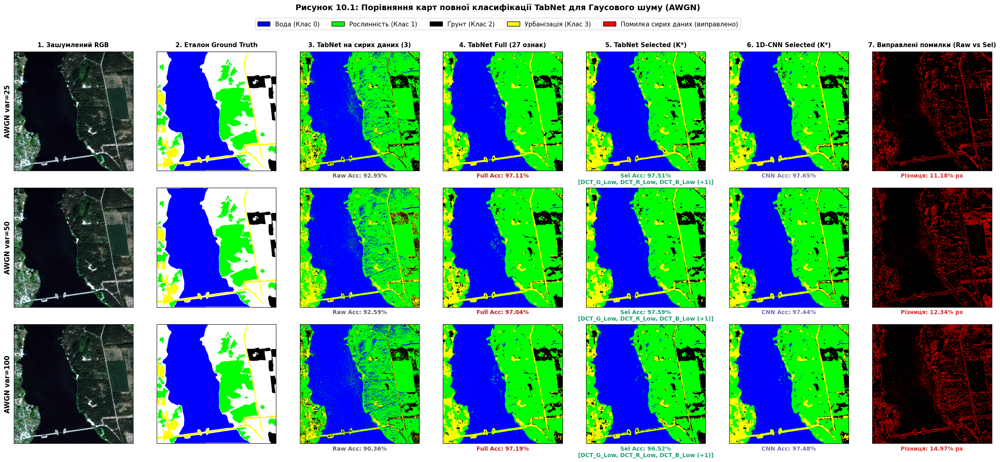

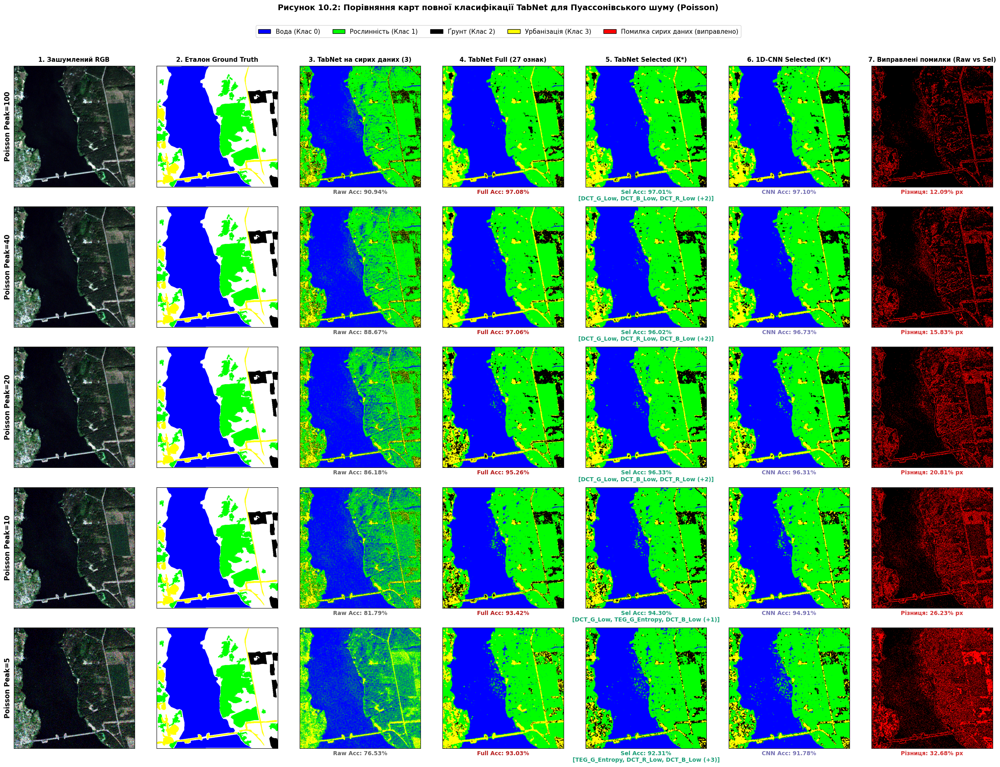

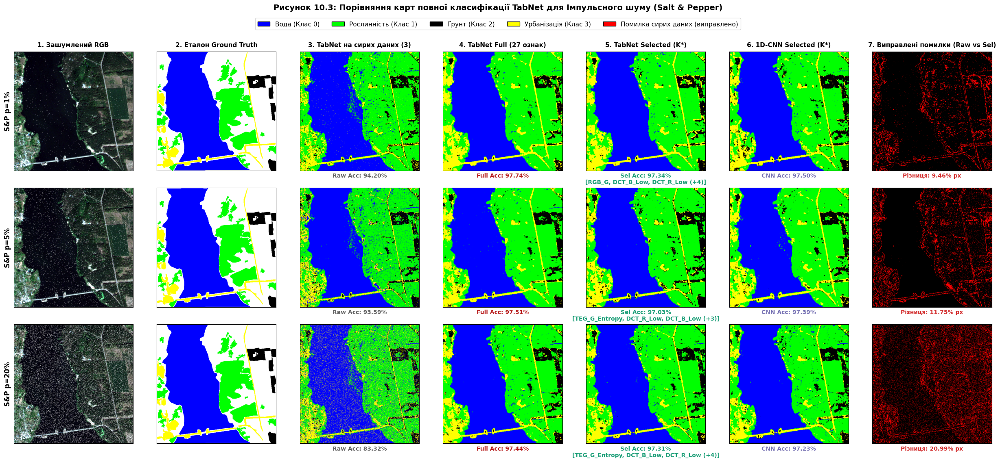

In [96]:
# =============================================================================
# MAIN 10: ВІЗУАЛІЗАЦІЯ КАРТ СЕГМЕНТАЦІЇ TabNet ТА ПОРІВНЯННЯ З 1D-CNN
# =============================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def main_step10_visualize_tabnet_maps():
    global step9_tabnet_results
    
    if "step9_tabnet_results" not in globals() or step9_tabnet_results is None:
        if os.path.exists("data/step9_tabnet_results.npy"):
            print("[i] Завантаження підготовлених результатів Кроку 9 з data/step9_tabnet_results.npy...")
            step9_tabnet_results = np.load("data/step9_tabnet_results.npy", allow_pickle=True).item()
        else:
            raise RuntimeError(
                "ПОМИЛКА: Крок 10 не може бути виконаний без результатів Кроку 9!\n"
                "Будь ласка, спочатку запустіть клітинку Кроку 9 (main_step9_tabnet_evaluation()),\n"
                "яка навчає нейромережу TabNet, генерує карти класифікації та кешує результати."
            )
            
    groups = [
        ("AWGN", ["AWGN var=25", "AWGN var=50", "AWGN var=100"], "Рисунок 10.1: Порівняння карт повної класифікації TabNet для Гаусового шуму (AWGN)"),
        ("Poisson", ["Poisson Peak=100", "Poisson Peak=40", "Poisson Peak=20", "Poisson Peak=10", "Poisson Peak=5"], "Рисунок 10.2: Порівняння карт повної класифікації TabNet для Пуассонівського шуму (Poisson)"),
        ("Impulse", ["S&P p=1%", "S&P p=5%", "S&P p=20%"], "Рисунок 10.3: Порівняння карт повної класифікації TabNet для Імпульсного шуму (Salt & Pepper)")
    ]
    
    col_titles = [
        "1. Зашумлений RGB",
        "2. Еталон Ground Truth",
        "3. TabNet на сирих даних (3)",
        "4. TabNet Full (27 ознак)",
        "5. TabNet Selected (K*)",
        "6. 1D-CNN Selected (K*)",
        "7. Виправлені помилки (Raw vs Sel)"
    ]
    
    legend_elements = [
        Patch(facecolor=(0.0, 0.0, 1.0), edgecolor="black", label="Вода (Клас 0)"),
        Patch(facecolor=(0.0, 1.0, 0.0), edgecolor="black", label="Рослинність (Клас 1)"),
        Patch(facecolor=(0.0, 0.0, 0.0), edgecolor="black", label="Ґрунт (Клас 2)"),
        Patch(facecolor=(1.0, 1.0, 0.0), edgecolor="black", label="Урбанізація (Клас 3)"),
        Patch(facecolor=(1.0, 0.0, 0.0), edgecolor="black", label="Помилка сирих даних (виправлено)")
    ]
    
    for g_title, g_levels, fig_title in groups:
        n_rows = len(g_levels)
        fig, axes = plt.subplots(n_rows, 7, figsize=(25, 3.6 * n_rows))
        if n_rows == 1:
            axes = np.expand_dims(axes, 0)
            
        for r_idx, lvl in enumerate(g_levels):
            cdata = step9_tabnet_results["cases_data"][lvl]
            
            # Col 1: Noisy RGB
            axes[r_idx, 0].imshow(cdata["img_rgb"])
            axes[r_idx, 0].set_ylabel(lvl, fontsize=12, fontweight="bold")
            
            # Col 2: GT mask
            axes[r_idx, 1].imshow(step9_tabnet_results["gt_mask_rgb"])
            
            # Col 3: TabNet Raw RGB
            axes[r_idx, 2].imshow(cdata["color_map_tabnet_raw_rgb"])
            axes[r_idx, 2].set_xlabel(f"Raw Acc: {cdata['acc_tabnet_raw']*100:.2f}%", fontsize=10, fontweight="bold", color="#616161")
            
            # Col 4: TabNet Full 27
            axes[r_idx, 3].imshow(cdata["color_map_tabnet_full_rgb"])
            axes[r_idx, 3].set_xlabel(f"Full Acc: {cdata['acc_tabnet_full']*100:.2f}%", fontsize=10, fontweight="bold", color="#b71c1c")
            
            # Col 5: TabNet Selected K*
            axes[r_idx, 4].imshow(cdata["color_map_tabnet_sel_rgb"])
            features_brief = ", ".join(cdata["sel_features"][:3]) + (f" (+{len(cdata['sel_features'])-3})" if len(cdata['sel_features']) > 3 else "")
            axes[r_idx, 4].set_xlabel(f"Sel Acc: {cdata['acc_tabnet_sel']*100:.2f}%\n[{features_brief}]", fontsize=10, fontweight="bold", color="#1b9e77")
            
            # Col 6: 1D-CNN Selected K*
            axes[r_idx, 5].imshow(cdata["color_map_cnn_sel_rgb"])
            axes[r_idx, 5].set_xlabel(f"CNN Acc: {cdata['acc_cnn_sel']*100:.2f}%", fontsize=10, fontweight="bold", color="#7570b3")
            
            # Col 7: Diff map between TabNet Raw and TabNet Sel
            diff = cdata["diff_raw_sel_rgb"]
            diff_vis = np.zeros((512, 512, 3), dtype=np.uint8)
            diff_vis[diff > 0] = [255, 0, 0]
            axes[r_idx, 6].imshow(diff_vis)
            diff_pct = (np.count_nonzero(diff) / (512 * 512)) * 100.0
            axes[r_idx, 6].set_xlabel(f"Різниця: {diff_pct:.2f}% px", fontsize=10, fontweight="bold", color="#d32f2f")
            
            for c_idx in range(7):
                axes[r_idx, c_idx].set_xticks([])
                axes[r_idx, c_idx].set_yticks([])
                if r_idx == 0:
                    axes[r_idx, c_idx].set_title(col_titles[c_idx], fontsize=11, fontweight="bold", pad=8)
                    
        fig.legend(handles=legend_elements, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5, fontsize=11, frameon=True)
        fig.suptitle(fig_title, fontsize=14, fontweight="bold", y=1.045)
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    main_step10_visualize_tabnet_maps()

